In [1]:
#This is my cannimballised setup for analysis of HERFD data.
#This should define all functions and import all the required packages to run the analysis of the data.
#Initial setup for analysis of the combined data (required to import the data structure from the pickle file)
import numpy as np
import math
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
import scipy.signal
from mpl_toolkits.mplot3d import Axes3D
import h5py
from nexusformat.nexus import *
from matplotlib import cm
from scipy.optimize import curve_fit
import sys
import json
from scipy import interpolate
import matplotlib.colors as colors
from pystyle import Colors, Colorate
import os
import re
import time
from scipy.ndimage import label, center_of_mass, gaussian_filter
import pickle
from sklearn.decomposition import NMF, PCA, FastICA, LatentDirichletAllocation
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from _pca import PCA as PCA2
from scipy.signal import savgol_filter
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from tensorly.decomposition import Tucker, non_negative_tucker, non_negative_tucker_hals, parafac, parafac2
from tensorly.tucker_tensor import tucker_to_tensor
import lmfit
import matplotlib.pyplot as plt
from scipy.special import voigt_profile as voigt
from decimal import Decimal
import csv
from collections import defaultdict as dd
from mpl_toolkits import mplot3d
from mpl_toolkits.mplot3d import Axes3D
import h5py
from nexusformat.nexus import *
from matplotlib import cm
from scipy.optimize import curve_fit
from scipy import interpolate

#function to locate all the relevant files coresponding to the given scan number (only works on Ubuntu)
def Find_files(File_path,Scan_No):
    nexus_file = []
    hdf_files = []
    #loop through all the files in the specified location
    for trial_file in os.listdir(File_path):
        #if the file name contains the desired scan number
        if Scan_No in trial_file:
            #if it's a nexus file
            if trial_file.endswith(".nxs"):
                #add it to the list of nexus files that relate to our specific scan
                nexus_file =trial_file
            #if it's a hdf file
            elif trial_file.endswith(".hdf"):
                hdf_files.append(trial_file)
    return nexus_file, hdf_files

#function that will find the incident and emission energies as well as the I1 counts
def Get_Nexus(nxs):
    #print(nxs.tree)
    #we know that the data for the thigns we want will always be in a directory starting with entry1.instrament
    for source in nxs.entry1.instrument.keys():
        #look through until we find our XES energy data
        if 'XESE' in source:
            XES_Folder = nxs.entry1.instrument[source]
            for source2 in XES_Folder.keys():
                #assign the data to an array
                Ef = np.asarray(XES_Folder[source2])
                break
            break
    #do the same for the incident energy data
    for source in nxs.entry1.instrument.keys():
        if 'bragg1Wi' in source or 'xas_scannable' in source:
            Ei_Folder = nxs.entry1.instrument[source]
            for source2 in Ei_Folder.keys():
                if 'bragg1Wi' in source2:
                    Ei = np.asarray(Ei_Folder[source2])
                    break
            break
    #do the same for the incident intensity data
    for source in nxs.entry1.instrument.keys():
        if 'I1' in source:
            I1_Folder = nxs.entry1.instrument[source]
            for source2 in I1_Folder.keys():
                if 'I1' in source2:
                    I1 = np.asarray(I1_Folder[source2])
                    break
            break
    return Ei, Ef, I1

def Get_Elastic_Nexus(nxs):
    print(nxs.tree)
    #we know that the data for the thigns we want will always be in a directory starting with entry1.instrament
    for source in nxs.entry1.instrument.keys():
        #look through until we find our XES energy data
        if 'XESE' in source:
            XES_Folder = nxs.entry1.instrument[source]
            for source2 in XES_Folder.keys():
                #assign the data to an array
                Ef = np.asarray(XES_Folder[source2])
                break
            break
    #do the same for the incident energy data
    for source in nxs.entry1.instrument.keys():
        if 'bragg1Wi' in source or 'xas_scannable' in source:
            Ei_Folder = nxs.entry1.instrument[source]
            for source2 in Ei_Folder.keys():
                if 'bragg1Wi' in source2:
                    Ei = np.asarray(Ei_Folder[source2])
                    break
            break
    #do the same for the incident intensity data
    for source in nxs.entry1.instrument.keys():
        if 'I1' in source:
            I1_Folder = nxs.entry1.instrument[source]
            for source2 in I1_Folder.keys():
                if 'I1' in source2:
                    I1 = np.asarray(I1_Folder[source2])
                    break
            break
    return Ei, Ef, I1

# #function to read in the hdf binary files (no flipping version)
# def read_HDF(filename):
#     f = h5py.File(filename, 'r')
#     group = f['entry']
#     i_dataset = group['instrument']
#     d_dataset = i_dataset['detector']
#     dataset = group['data']
#     return dataset['data']

#function to read in the hdf binary files
def read_HDF(filename):
    f = h5py.File(filename, 'r')
    group = f['entry']
    i_dataset = group['instrument']
    d_dataset = i_dataset['detector']
    dataset = group['data']
    data = dataset['data']
    if FLIP_VERTICAL:
        # detector image rows are the second-last axis
        try:
            data = np.flip(data, axis=-2)
        except Exception:
            # fallback for unexpected shapes
            data = np.flipud(data)
    return data

#function that will find the energy (or energies) that correspond to the detector image that is most intense
def find_max_intensity(sparce_data):
    #take the average of the last two axes
    ave_sparce = np.mean(sparce_data,axis=(-1,-2))
    #find the location of the element that has the strongest signal
    max_loc = np.unravel_index(np.argmax(ave_sparce), ave_sparce.shape)
    #convert this into a more usable list
    max_index = [int(x) for x in max_loc]
    #convert that into a form we can use to isolate just the one detector image we want
    max_index_tuple = tuple(max_index) + (slice(None),) * (sparce_data.ndim - len(max_index))
    return max_index_tuple

#function that takes a detector image and will count and locate all the crystal regions
def find_analysers(max_detector):
    cents = []
    #smooth the data first to help things out, sigma determines how smooth you want the data to be (higher = smoother)
    smoothed = gaussian_filter(max_detector, sigma=2)
    #define the threshold for detection,  you can tune this based on noise level
    threshold = np.amax(smoothed)/10.0
    print('Threshold = ' + str(threshold))
    binary_mask = smoothed > threshold
    # Connected component labeling
    labeled_array, num_spots = label(binary_mask)
    # Compute spot locations (centroids)
    centroids = center_of_mass(smoothed, labeled_array, range(1, num_spots + 1))
    #round values and convert to more usable form
    centroids = np.rint(np.array(centroids)).astype(int)
    #check for and remove duplicate peaks
    centroids=check_for_duplicates(centroids)
    #order the spots from left to right
    order= np.argsort((centroids)[:,1])
    # Optionally compute additional properties (like total intensity or area)
    index = 1
    spot_properties = []
    for i in order: # range(1, num_spots + 1):
        spot_mask = (labeled_array == (i+1))
        total_intensity = smoothed[spot_mask].sum()
        area = spot_mask.sum()
        cents.append(centroids[i,:])
        spot_properties.append({
            "index": index,
            "centroid": centroids[i,:],#tuple([round(float(x)) for x in centroids[i]]), #centroids[i - 1],
            "area": area,
            "intensity": total_intensity
            })
        index+=1
    return cents

#a function that will check to see if we are counting the same crystal region more than once and return only unique detections and the average of the duplicates
def check_for_duplicates(centroids):
    #define how close you want the threshold for duplicates to be
    delta = 70
    y_centroids = centroids[:,1]
    #loop through every value
    for i in y_centroids:
        others = y_centroids[y_centroids != i]
        #check to see if we have duplicates
        is_within_range = np.any(np.abs(others -i)<delta)
        if is_within_range:
            #define all values that arent duplicates
            non_d_indices = np.where(np.abs(y_centroids - i) > delta)[0]
            #define all duplicates
            d_indicies = np.where(np.abs(y_centroids - i) < delta)[0]
            #average over the duplicate coordinates
            ave = np.rint(np.mean(centroids[d_indicies,:],axis=0)).astype(int)
            #redefine the centroids to only include non duplicates and the average of the duplicates
            centroids = np.vstack([centroids[non_d_indices,:],ave])
            #go again without these duplicates
            return check_for_duplicates(centroids)
    return centroids

def Get_Crystal_Coords(File_path, hdf_files):
    centroids = []
    for count,hdf_file in enumerate(hdf_files):
        #tell the code where the data is and (kind of) read it in
        data  = read_HDF(File_path+hdf_file)
        start = time.time()
        #define how space the data to be read in should be (the higher the sparcer)
        sparceness = 20
        #actually read in only a smaller version of the sata that only taken in a low res version of the detector for speed reasons
        sparce_data = data[...,0::sparceness,0::sparceness]
        end = time.time()
        print(f'>> Detector {count}:')
        print(f'Sparce Data Read in Took: ', end-start,'Seconds')
        #find the energy/energies with the highest intensity
        max_index_tuple = find_max_intensity(sparce_data)
        #read in the full detector image for just that energy
        max_detector = data[max_index_tuple]
        #see how many analysers we have and where they're located
        centroids.append(find_analysers(max_detector))
    return np.asarray(centroids)

#function that read in the data from the hfd binaries and outputs the data around each pixel region
def get_data(File_path,hdf_files,crystal_height,crystal_width,plot_data,Crystal_Coords):
    #make an array into which the data from each crystal will be read
    hdf_data = []
    medipix_index=0
    #now time to read in the actual data
    for hdf_file in hdf_files:
        #tell the code where the data is and (kind of) read it in
        data  = read_HDF(File_path+hdf_file)
        #loop through each crystal that's been found
        for crystal_index in range(Crystal_Coords.shape[1]):
            x_coord = Crystal_Coords[medipix_index,crystal_index,0]
            y_coord = Crystal_Coords[medipix_index,crystal_index,1]
            # print('Medipix'+str(medipix_index+1)+' Crystal: ',crystal_index+1, ', Position: ','('+str(x_coord)+', ' +str(y_coord)+')')
            #plot the crystal regions if you want
            if plot_data:
                fig, ax = plt.subplots(figsize = (10,8))
                c = ax.pcolormesh(max_detector[x_coord-crystal_height:x_coord+crystal_height,y_coord-crystal_width:y_coord+crystal_width], cmap='rainbow',shading='gouraud')
                cbar=fig.colorbar(c,orientation='vertical').set_label(label='Counts/Pixel',size=14)
                ax.set_title('('+str(x_coord)+', ' + str(prop['centroid'][1])+')')
                #add in only the data surounding each crystal for data and time saving
            hdf_data.append(data[...,x_coord-crystal_height:x_coord+crystal_height,y_coord-crystal_width:y_coord+crystal_width])
        if plot_data:
            fig, ax = plt.subplots(figsize = (10,8))
            c = ax.pcolormesh(max_detector[...], cmap='rainbow',shading='gouraud')
            cbar=fig.colorbar(c,orientation='vertical').set_label(label='Counts/Pixel',size=14)
        medipix_index+=1
    #rearrange the list into a more useful array
    hdf_data = np.stack(hdf_data, axis=-1)
    return hdf_data

#function that generates a surface plot of a 2D data set
def surface_plot(x,y,data,z_axis):
    x_new,y_new = np.meshgrid(y,x)
    fig = plt.figure(figsize = (10,12))
    axes = plt.axes(projection ='3d')
    plot=axes.plot_surface(x_new, y_new, data,color='yellow',rcount = np.amax([len(x),len(y)]),ccount = np.amax([len(x),len(y)]))
    plot=axes.plot_wireframe(x_new, y_new, data,color='black',linewidths=0.3,rcount = np.amax([len(x),len(y)]),ccount = np.amax([len(x),len(y)]))
    axes.set_ylabel('$E_{em}$ (eV)')
    axes.set_xlabel('$E_{in}$ (eV)')
    axes.set_zlabel(z_axis)

def contour_plot(x,y,data,z_axis):
    x_new,y_new = np.meshgrid(y,x)
    fig, ax = plt.subplots(figsize = (10,12))
    c = ax.pcolormesh(x_new, y_new, data, cmap='rainbow',shading='gouraud')
    cbar=fig.colorbar(c,orientation='horizontal').set_label(label=z_axis,size=14)
    plt.ylabel('$E_{em}$ (eV)')
    plt.xlabel('$E_{in}$ (eV)')

def Get_Analysers(File_path,Strong_Scan):
    #see if a specific scan has been specified
    if Strong_Scan:
        nexus_file, hdf_files = Find_files(File_path,str(Strong_Scan))
        #get the crystal locations
        Crystal_Coords = Get_Crystal_Coords(File_path, hdf_files)
    else:
        nexus_file, hdf_files = Find_files(File_path, Scan_Nos[0])
        Crystal_Coords = Get_Crystal_Coords(File_path, hdf_files)
    #Print the resutls
    print('>> Crystal Positions:')
    for medipix in range(Crystal_Coords.shape[0]):
        for crystal in range(Crystal_Coords.shape[1]):
            x_coord = Crystal_Coords[medipix,crystal,0]
            y_coord = Crystal_Coords[medipix,crystal,1]
            print('Medipix'+str(medipix+1)+' Crystal: ',crystal+1, ', Position: ','('+str(x_coord)+', ' +str(y_coord)+')')
    return Crystal_Coords

def Get_single_full_image(File_path,Scan_No):
    nexus_file, hdf_files = Find_files(File_path,Scan_No)
    #tell the code where the data is and (kind of) read it in
    data = []
    for hdf_file in hdf_files:
        data.append(read_HDF(File_path+hdf_file))
    return data

# ==============================================================================================================
# Functions for XR-HERFD Splicing:
# ==============================================================================================================
#define center of crystal regions
def Simple_CenterROI(region):
    center_x =0
    center_y =0
    total = 0
    Ei = np.shape(region)[1]
    for j in range(np.shape(region)[0]):
        for k in range(np.shape(region)[2]):
            for l in range(np.shape(region)[3]):
                center_x += k*region[j,Ei-1,k,l]
                center_y += l*region[j,Ei-1,k,l]
                total += region[j,Ei-1,k,l]
    return [int(round(center_x/total)),int(round(center_y/total))]

#defines slices for the crystal regions
def slice_ROI(region,slice_height,slice_width,ROI_height,n_Ei,n_Ef):
    center = Simple_CenterROI(region)
    #print(type(np.shape(region)[0]))
    print(center)

    Summed_slices = np.zeros((n_Ef,n_Ei,int(ROI_height/slice_height)))
    slices_error = np.zeros((n_Ef,n_Ei,int(ROI_height/slice_height)))
    for i in range(n_Ef):
        #print(i)
        for j in range(n_Ei):
            for k in range(int(ROI_height/slice_height)):
                #print(i,j,k)
                Summed_slices[i,j,k]=np.sum(region[i,j,int(center[0]-ROI_height/2+k*slice_height):\
                int(center[0]-ROI_height/2+k*slice_height+slice_height),int(center[1]-slice_width/2):\
                int(center[1]+slice_width/2)])#/ASCII[j,i,3]
                slices_error[i,j,k]=Summed_slices[i,j,k]**0.5#/ASCII[j,i,3]

    return Summed_slices


# ==============================================================================================================
# Functions for plotting
# ==============================================================================================================
def normalize_data(input, new_min=0, new_max=1): 
    input = np.array(input)
    old_min, old_max = np.min(input), np.max(input)
    
    # Avoid dividing by zero
    if old_min == old_max:
        return [new_min for _ in input]
    
    normalized = (input - old_min) / (old_max - old_min)  # scale to [0,1]
    normalized = normalized * (new_max - new_min) + new_min  # scale to [new_min,new_max]
    
    return normalized.tolist()

def Find_files(File_loc, Scan_No):
    nexus_file = '' 
    hdf_files = []
    for trial_file in os.listdir(File_loc):
        if Scan_No in trial_file:
            if trial_file.endswith('.nxs'):
                nexus_file = trial_file
            elif trial_file.endswith('.hdf'):
                hdf_files.append(trial_file)
    return nexus_file, hdf_files



# Extract Ei, Ef, and I1 from the Nexus file
def Get_Nexus(nxs):
    print(nxs.tree)
    Ei = None
    Ef = None
    I1 = None

    for source in nxs.entry1.instrument.keys():
        if 'XESE' in source:
            XES_Folder = nxs.entry1.instrument[source]
            for source2 in XES_Folder.keys():
                Ef = np.asarray(XES_Folder[source2])
                break
            break

    for source in nxs.entry1.instrument.keys():
        if (
            'bragg1Wi' in source
            or 'xas_scannable' in source
            or 'braggoffset' in source
        ):
            Ei_Folder = nxs.entry1.instrument[source]
            for source2 in Ei_Folder.keys():
                if 'bragg1Wi' in source2 or 'braggoffset' in source2:
                    Ei = np.asarray(Ei_Folder[source2])
                    break
            break

    for source in nxs.entry1.instrument.keys():
        if 'I1' in source or 'd9_current_detector' in source:
            I1_Folder = nxs.entry1.instrument[source]
            for source2 in I1_Folder.keys():
                if 'I1' in source2 or 'data' in source2:
                    I1 = np.asarray(I1_Folder[source2])
                    break
            break

    return Ei, Ef, I1

# Read the HDF file and extract the data
def read_HDF(filename):
    f = h5py.File(filename, 'r')
    group = f['entry']
    i_dataset = group['instrument']
    d_dataset = i_dataset['detector']
    dataset = group['data']
    return dataset['data']


# Find the maximum intensity in the sparse data and return its index
def find_max_intensity(sparce_data):
    ave_sparce = np.mean(sparce_data, axis=(-1, -2))
    max_loc = np.unravel_index(np.argmax(ave_sparce), ave_sparce.shape)
    max_index = [int(x) for x in max_loc]
    max_index_tuple = tuple(max_index) + (slice(None),) * (
        sparce_data.ndim - len(max_index)
    )
    return max_index_tuple


# Find the centroids of the analyzers in the maximum intensity detector image
def find_analysers(max_detector):
    cents = []
    smoothed = gaussian_filter(max_detector, sigma=2)
    threshold = np.amax(smoothed) / 10.0
    binary_mask = smoothed > threshold
    labeled_array, num_spots = label(binary_mask)
    centroids = center_of_mass(
        smoothed, labeled_array, range(1, num_spots + 1)
    )
    centroids = np.rint(np.array(centroids)).astype(int)
    centroids = check_for_duplicates(centroids)
    order = np.argsort((centroids)[:, 1])
    
    index = 1
    spot_properties = []
    for i in order:
        spot_mask = labeled_array == (i + 1)
        total_intensity = smoothed[spot_mask].sum()
        area = spot_mask.sum()
        cents.append(centroids[i, :])
        spot_properties.append(
            {
                'index': index,
                'centroid': centroids[i, :],
                'area': area,
                'intensity': total_intensity,
            }
        )
        index += 1
    return cents

# Check for duplicate centroids and average them if they are too close together
def check_for_duplicates(centroids):
    delta = 70
    y_centroids = centroids[:, 1]
    for i in y_centroids:
        others = y_centroids[y_centroids != i]
        is_within_range = np.any(np.abs(others - i) < delta)
        if is_within_range:
            non_d_indices = np.where(np.abs(y_centroids - i) > delta)[0]
            d_indicies = np.where(np.abs(y_centroids - i) < delta)[0]
            ave = np.rint(np.mean(centroids[d_indicies, :], axis=0)).astype(int)
            centroids = np.vstack([centroids[non_d_indices, :], ave])
            return check_for_duplicates(centroids)
    return centroids


# Get the crystal coordinates for each HDF file by finding the centroids of the analyzers in the maximum intensity detector image
def Get_Crystal_Coords(hdf_files):
    centroids = []
    for hdf_file in hdf_files:
        data = read_HDF(File_loc + hdf_file)
        start = time.time()
        sparceness = 20
        sparce_data = data[..., 0::sparceness, 0::sparceness]
        end = time.time()
        print('Sparce Data Read in Took: ', end - start, 'Seconds')
        max_index_tuple = find_max_intensity(sparce_data)
        max_detector = data[max_index_tuple]
        centroids.append(find_analysers(max_detector))
    return np.asarray(centroids)

# Get the data for each HDF file and each crystal by extracting the region of interest around the crystal coordinates
def get_data(
    hdf_files,
    crystal_height,
    crystal_width,
    plot_data,
    Crystal_Coords,
    plot_scan_no='305229',
):
    all_data = []
    medipix_index = 0

    hdf_files = sorted(hdf_files)

    for hdf_file in hdf_files:
        if medipix_index >= Crystal_Coords.shape[0]:
            print(f'Warning: Extra HDF file ignored ({hdf_file})')
            break

        data = read_HDF(File_loc + hdf_file)
        sparceness = 20
        sparce_data = data[..., 0::sparceness, 0::sparceness]
        max_index_tuple = find_max_intensity(sparce_data)
        max_detector = data[max_index_tuple]

        should_plot = plot_data and (plot_scan_no in hdf_file)

        for crystal_index in range(Crystal_Coords.shape[1]):
            x_coord = Crystal_Coords[medipix_index, crystal_index, 0]
            y_coord = Crystal_Coords[medipix_index, crystal_index, 1]

            if should_plot:
                fig, ax = plt.subplots()
                c = ax.pcolormesh(
                    max_detector[
                        x_coord - crystal_height : x_coord + crystal_height,
                        y_coord - crystal_width : y_coord + crystal_width,
                    ],
                    cmap='rainbow',
                    shading='gouraud',
                )
                cbar = fig.colorbar(c, orientation='vertical')
                cbar.set_label(label='Counts/Pixel', size=14)
                ax.set_title(
                    f'Scan {plot_scan_no} Crystal ({x_coord}, {y_coord})'
                )

            all_data.append(
                data[
                    ...,
                    x_coord - crystal_height : x_coord + crystal_height,
                    y_coord - crystal_width : y_coord + crystal_width,
                ]
            )

        if should_plot:
            fig, ax = plt.subplots()
            c = ax.pcolormesh(max_detector, cmap='rainbow', shading='gouraud')
            cbar = fig.colorbar(c, orientation='vertical')
            cbar.set_label(label='Counts/Pixel', size=14)
            ax.set_title(f'Scan {plot_scan_no} Full Detector')

        medipix_index += 1

    all_data = np.stack(all_data, axis=-1)
    return all_data

# Create a 3D surface plot of the data
def surface_plot(x, y, data, z_axis):
    x_new, y_new = np.meshgrid(y, x)
    fig = plt.figure()
    axes = plt.axes(projection='3d')
    plot = axes.plot_surface(
        x_new,
        y_new,
        data,
        color='yellow',
        rcount=np.amax([len(x), len(y)]),
        ccount=np.amax([len(x), len(y)]),
    )
    plot = axes.plot_wireframe(
        x_new,
        y_new,
        data,
        color='black',
        linewidths=0.3,
        rcount=np.amax([len(x), len(y)]),
        ccount=np.amax([len(x), len(y)]),
    )
    axes.set_ylabel(r'Emission Energy (eV)')
    axes.set_xlabel(r'Incident Energy (eV)')
    axes.set_zlabel(z_axis)


# Get the analyser coordinates from the HDF files, either from a strong scan or the first scan in the list
def Get_Analysers(File_loc, Strong_Scan):
    if Strong_Scan:
        nexus_file, hdf_files = Find_files(File_loc, str(Strong_Scan))
        Crystal_Coords = Get_Crystal_Coords(hdf_files)
    else:
        nexus_file, hdf_files = Find_files(File_loc, Scan_Nos[0])
        Crystal_Coords = Get_Crystal_Coords(hdf_files)
        
    for medipix in range(Crystal_Coords.shape[0]):
        for crystal in range(Crystal_Coords.shape[1]):
            x_coord = Crystal_Coords[medipix, crystal, 0]
            y_coord = Crystal_Coords[medipix, crystal, 1]
            print(
                'Medipix' + str(medipix + 1) + ' Crystal: ',
                crystal + 1,
                ', Position: ',
                '(' + str(x_coord) + ', ' + str(y_coord) + ')',
            )
    return Crystal_Coords


#Definition of peakfit functions and data reading functions for experimental and computational data analysis
"""
Created on Wed Apr 10 10:38:54 2024

@author: smkrstevski
"""


def read_exp(path, energy_range = [8010,8070], normalise = False, error_vals = True, skip = 0):
    '''
    Reads in a list of experimental data (e.g Mendenhall or Deutsh ect.)

    Parameters
    ----------
    path : STRING
        Path to experimental data.
    energy_range : List, optional
        The range of energies to be considered (used to cut out redundant data).
        The default is [8010,8080].
    normalise : BOOL, optional
        Whether or not the intensities should be normalised (note if the
        intensities are normalised then the errors likely loos meaning). The default is True.
    error_vals : BOOL, optional
        Set False if no errors provided. The default is True.

    Returns
    -------
    LIST
        List of lists containg (in order) [energy values, intensity values, error values].

    '''
    # Reads in experimental data
    lines = []
    with open(path, 'r') as file:
        for i in range(skip):
            next(file)    
        for line in file:
            lines.append(line.split())

    # Makes lists to store experimental data
    e_vals = []
    i_vals = []
    err_vals = []
    
    # Itterates over and sorts all data
    for i in lines:
        if float(i[0]) < energy_range[1] and float(i[0]) > energy_range[0]:
            e_vals.append(float(i[0]))
            i_vals.append(float(i[1]))
            if error_vals:
                err_vals.append(float(i[2]))
    
    # makes the energy values and error values an np array
    e_vals_arr = np.array(e_vals)
    
    # Normalises the intensities (if required) and makes them an np array
    if normalise:
        i_vals_arr = np.array(MinMaxScaler.fit_transform(i_vals))
    else:
        i_vals_arr = np.array(i_vals)
    
    # Returns data with error values included (all as np arrays)
    if error_vals:
        err_vals_arr = np.array(err_vals)
        return e_vals_arr, i_vals_arr, err_vals_arr
    
    # Returns data if error values not included
    else:
        return e_vals_arr, i_vals_arr

def exp_voigt_profile(exp_data, e_vals):
    '''
    Creates voigt profile for a set of experimental data

    Parameters
    ----------
    exp_data : LIST
        exp_data : LIST
            List of experimental parameters of the form:
            [centeroids, areas, g_fwhms, l_fwhms]
                centroids : LIST
                    Location of experimental data peaks Energy in eV.
                areas : LIST
                    Expermental value for the integrated area of each peak.
                g_fwhms : LIST
                    Gaussian full width half maximum of each experimental peak.
                l_fwhms : LIST
                    Lorentzian full width half maximum of each experimental peak.
    e_vals : LIST
        The energy values for the experiental data.

    Returns
    -------
    Intensity values for the corresponding energy values.

    '''
    # Checks for invalid inputs
    if len(exp_data) != 4:
        raise ValueError("Invalid number of experimental data catagories")
    
    # Defines Experimental Parameters
    centroids = exp_data[0] 
    areas = exp_data[1]
    g_fwhms = exp_data[2]
    l_fwhms = exp_data[3] 
    
    if not len(g_fwhms) == len(l_fwhms) == len(centroids) == len(areas):
        raise ValueError("Experimental data not the same length")
    
    func = np.zeros(len(e_vals))
    #Sums over all peaks in the experimental data
    for i in range(0,len(g_fwhms)):
        # Checks to makse sure there is width
        if g_fwhms[i] == 0 and l_fwhms[i] == 0:
            raise ValueError(f"no width in experimental data {i} in list")
        
        # Defines the variables for each part of the experimental data 
        area = areas[i]
        e0 = centroids[i]
        sigma = g_fwhms[i]/(2*np.sqrt(2*np.log(2)))
        gamma = l_fwhms[i]/2
        shift_e_vals = e_vals - e0
        
        # Adds the part to the combined profile
        func += area * voigt(shift_e_vals, sigma, gamma)
    return func

def rate_j_lvl(ct):
    my_dict = dd(float)
    for i in range(0,len(ct[0])):
        lvl = ct[-4][i]
        j = ct[-2][i]
        A_coef = (ct[1][i] + ct[2][i])/2 
        my_dict[f"j{j}L{lvl}"] += A_coef * np.pi
    return dict(my_dict) 

def indvidual_bound(param_value, bound_value, bound_type, param_num, cur_sat):
    '''
    Makes the bound for a single parameter as deffined by bound value and type

    Parameters
    ----------
    param_value : FLOAT
        The value of the parameter that the bounds if made around.
    bound_value : FLOAT/TUPPLE
        value(s) that specify the range of the bound.
    bound_type : STRING
        The bound calculation method, Must be one of:
        -s (set value): a TUPPLE (lower bound, Upper bound)
        -p (percentage): a FLOAT of the percentage the variable can change
        -c (constant): A FLOAT the fixed value the bound can change by
        -f (fixed): Keepd the variable fixed (smallest possible variation)
    param_num : INT
        The position of the parameter in the list (used for error traceback).
    cur_sat : INT/STRING
        The satellites number that the parameter belongs too (used for traceback).

    Returns
    -------
    bound : LIST
        Upper and lower bound for the parameter.

    '''
    if bound_type == "s":
        # Checks for valid input
        if bound_value[0] > bound_value[1]:
            raise ValueError(f"The specified bounds for parameter {param_num} in  paramter set {cur_sat} " +
                             "has the lower bound larger than the upper bound")
        if bound_value[0] == bound_value[1]:
            raise ValueError(f"The specified bounds for parameter {param_num} in  paramter set {cur_sat} " +
                             "are equal to fix bound use the bound type 'f'")
        if param_value <  bound_value[0] or param_value >  bound_value[1]:
            raise ValueError(f"paramater {param_num} in  paramter set {cur_sat} (val = {param_value}) outside of bounds {bound_value}")
        
        # If Valid adds to bounds list
        bound = [bound_value[0],bound_value[1]]
    
    # Sets the bounds for percentage
    elif bound_type == "p":
        # Checks for valid input
        if bound_value == 0:
            raise ValueError(f"The specified bounds for parameter {param_num} in  paramter set {cur_sat} "+
                             "Was set to a percentage of 0 to fix bound use the bound type 'f'")
            
        # If valid adds to bounds list
        bound = [param_value - (abs(bound_value) * param_value),param_value + (abs(bound_value) * param_value)]
    
    # Sets the bounds for Constant
    elif bound_type == "c":
        if bound_value == 0:
            raise ValueError(f"The specified bounds for parameter {param_num} in  paramter set {cur_sat} " +
                             "Was set to a constant shift of 0 to fix bound use the bound type 'f'")
        
        # If Valid adds to bounds list
        bound = [param_value - abs(bound_value),param_value + abs(bound_value)]
    
    # Sets the Bounds for fixed
    elif bound_type == "f":
        bound = [param_value, param_value]
    
    # If no valid bound method provided
    else:
        raise ValueError(f"parameter number {param_num} for paramter set {cur_sat}, has an invalid bound type " +
                         "It must be s (set value), p (percentage), c (constant) or f (fixed)" + 
                         f" but {bound_type} given")
    return bound

def make_bounds(cparams, sat_params, cvar, sat_var, spec_sat = False):
    '''
    Make the bounds for a set of parameters and a set of instructions

    Parameters
    ----------
    cparams : LIST
        List of common parameters.
    sat_params : LIST
        List of satellites parameters.
    cvar : LIST
        List describing how each common parameter varies.
    sat_var : LIST
        List describing how satellites parameters vary. or if spec_stat list of 
        list of satellites parameters for each unique satellites.
    spec_sat : BOOL, optional
        Describes whether the satellitess are specified individually. The default is False.

    Returns
    -------
    Bounds for all common parameters and satellitess in a way useable by make_params.

    '''    
    # Converts the single set of variations into a repeated list if no spec_sat
    num_sat = len(sat_params)
    var = sat_var if spec_sat else [sat_var] * num_sat
    
    # Defines the list that will hold the bounds information
    cbounds = []
    all_sat_bounds = []
    
    # itterates over all common_parameters
    for a, cparam in enumerate(cparams):
        # Defines the value for the bound and the method of bound calculation
        bound_value = cvar[a][0]
        bound_type = cvar[a][1]

        # Calculates bound for the parameter
        bound = indvidual_bound(cparam, bound_value, bound_type, param_num = a, cur_sat = "common params")
        cbounds.append(bound)
    
    # itterates over all satellites parameters
    for c, param_set in enumerate(sat_params):
        sat_bounds = []
        for d, pram in enumerate(param_set):
            # Defines the value for the bound and the method of bound calculation
            bound_value = var[c][d][0]
            bound_type = var[c][d][1]
            # Calculates bound for the parameter
            bound = indvidual_bound(pram, bound_value, bound_type, param_num = d, cur_sat = c)
            sat_bounds.append(bound)
        # adds the bounds info for that satellite to the larger list
        all_sat_bounds.append(sat_bounds)
        
    
    return cbounds, all_sat_bounds

def make_params(cparams, sat_params, cbounds, sat_bounds, 
                sat_list, cparam_names, sat_param_names):
    '''
    Makes parameter objects for each parameter used by lmfit

    Parameters
    ----------
    cparams : LIST
        List of value for each of the common parameters (same order as names).
    sat_params : LIST
        List of Paramters in lists for each satellites with each sublist being in
        order of the sat_list and each parameter being in the order of sat_param_names.
    cbounds : LIST
        common parameter bounds output by make_bounds.
    sat_bounds : LIST
        satellites parameter bounds output by make_bounds.
    sat_list : LIST
        List of the satellites names involved in the fit.
    cparam_names : LIST
        List of the common parameter names.
    sat_param_names : LIST
        List of the names of all the parameters for the satellitess.

    Returns
    -------
    params : lmfit_Parameters
        lmfit parameters that can be used by lmfit.minimize.

    '''
    # Parameters deffined as lmfit.Paramter class 
    params = lmfit.Parameters()

    # Iterates over all common parameter names
    for i, cparam in enumerate(cparams):
        cname = cparam_names[i]
        # Deffines the parameters values
        params[cname] = lmfit.Parameter(cname, value = cparam)
        # Deffines the parameters bounds
        if cbounds[i][0] == cbounds[i][1]:
            params[cname].vary = False
        else:
            params[cname].min = cbounds[i][0]
            params[cname].max = cbounds[i][1]
    
    # Iterates over satellite params and paramters within the satellite params
    for j, param_set in enumerate(sat_params):
        for k, param in enumerate(param_set):
            # Deffines the parameters name
            sname = "sat_" + sat_list[j] + "_" + sat_param_names[k]
            #Sets the parameters value
            params[sname] = lmfit.Parameter(sname, value = param)
            # Deffines the parameters bounds
            if sat_bounds[j][k][0] == sat_bounds[j][k][1]:
                params[sname].vary = False
            else:
                params[sname].min = sat_bounds[j][k][0]
                params[sname].max = sat_bounds[j][k][1]
    return params

def validate_fwhm(params, width, sat_list, fwhm_scale):
    def set_fwhm(params, key, min_val=0, value=0, vary=False):
        params[key].min = min_val
        params[key].value = value
        params[key].vary = vary
    
    if width.lower() == "common":
        if fwhm_scale.lower() != "unscaled":
            raise ValueError(f"The the width is common for all profiles but fwhm scaling is: {fwhm_scale} not 'unscaled'")
        if params["cfwhm"] == 0:
            raise ValueError("The profile will have a common FWHM but cfwhm is 0")
        set_fwhm(params, "fwhm_ka1")
        set_fwhm(params, "fwhm_ka2")
        for sat in sat_list:
            set_fwhm(params, f"sat_{sat}_fwhm")
    
    elif width.lower() == "sat":
        if fwhm_scale.lower() not in ["unscaled", "common"]:
            raise ValueError("The profile will have a common FWHM for each satellite but "+
                             f"fwhm scaling is: {fwhm_scale} must be either 'unscaled' or 'common'")
        for a, sat in enumerate(sat_list):
            if params[f"sat_{sat}_fwhm"] == 0:
                raise ValueError(f"The profile will have a common FWHM for each satellite but fwhm is 0 for sat number {a}")
        set_fwhm(params, "cfwhm")
        set_fwhm(params, "fwhm_ka1")
        set_fwhm(params, "fwhm_ka2")
    
    elif width.lower() == "j_lvl":
        if fwhm_scale.lower() not in ["unscaled", "common", "sat"]:
            raise ValueError("The profile will have a unique FWHM for each j or lvl but "+
                             f"fwhm scaling is '{fwhm_scale}' must be either 'unscaled', 'common' or 'sat'")
        set_fwhm(params, "cfwhm")
        set_fwhm(params, "fwhm_ka1")
        set_fwhm(params, "fwhm_ka2")
        for b, sat in enumerate(sat_list):
            set_fwhm(params, f"sat_{sat}_fwhm")
    
    elif width.lower() == "ka1ka2":
        if params["fwhm_ka1"] == 0 or params["fwhm_ka2"] == 0:
            raise ValueError("The profile will have a common FWHM but cfwhm is 0")
        for sat in sat_list:
            set_fwhm(params, f"sat_{sat}_fwhm")
                        
    else:
        raise ValueError("Invalid width. Must be one of: 'common', 'sat', 'j_lvl', 'ka1ka2'.")
    
    if fwhm_scale.lower() == "unscaled":
        set_fwhm(params, "cfwhm_scale")

    elif fwhm_scale.lower() == "common":
        if params["cfwhm_scale"] == 0:
            raise ValueError("The profile will have a common FWHM scale but cfwhm_scale is 0")
    
    elif fwhm_scale.lower() == "sat":
        set_fwhm(params, "cfwhm_scale")
        for a, sat in enumerate(sat_list):
            if params[f"sat_{sat}_fwhm_scl"] == 0:
                raise ValueError(f"The profile will have a common FWHM for each satellite but fwhm is 0 for sat number {a}")
        
def lorentz(e_vals, fwhm):
    '''
    Calculates the lorentzian profile for a given FWHM

    Parameters
    ----------
    e_vals : LIST
        List of energy values (x-axis).
    fwhm : FLOAT
        The Full Width Half Maximum of the lorentzian profile.

    Returns
    -------
    np.array
        List of the intensity values for each energy value.

    '''
    profile = (1/np.pi) * (fwhm/2)/((e_vals**2)+(fwhm/2)**2)
    return np.array(profile)

def theory_profile(params, ct_files, e_vals, sat_list, width, fwhm_scale, ka_dict, theory_fwhm): #include theory FWHM here
    ''' 
    Makes a theoretical profile for a given set of ct files and parameters made
    out of lorentzians

    Parameters
    ----------
    params : lmfit.Parameters
        Parameters made by make_params specifying each parameter and how it varies.
    ct_files : LIST
        List of data output from read_ct.
    e_vals : LIST
        List of energy the theory profile will find intensities for.
    sat_list : LIST
        LIST of satellites names.

    Returns
    -------
    LIST
        Returns the Intensity values generated for the given set of
        parameters and ct files.

    '''
    # Determines the number of satellitess
    num_ct = len(ct_files)

    # Defines list to contain the theoretical intensities
    total_prof = np.zeros(len(e_vals))
    
    # Deffines the common variables
    scale = params["scale"]
    bm = params["bkg_grad"]
    bc = params["bkg_yint"]
    c_fwhm = params["cfwhm"]
    c_shift = params["cshift"]
    

    # Builds background
    bkg = (bm*e_vals) + bc 
    
    #Itterates over every satellites
    for i in range(0, num_ct):        
        # Defines energy eigenvalues and intensities
        e_eigen = ct_files[i][0]
        i_eigen = norm(0.5 * (ct_files[i][3] + ct_files[i][4]))
        init_js = ct_files[i][-2]
        init_lvls = ct_files[i][-4]
        fin_js = ct_files[i][-1]
        fin_lvls = ct_files[i][-3]
        
        # Defines parameters for this satellites
        s_fwhm = params["sat_" + sat_list[i] + "_fwhm"]
        area = params["sat_" + sat_list[i] + "_area"]
        s_shift = params["sat_" + sat_list[i] + "_shift"]
        if ka_dict != None:
            s_ka_dict = ka_dict[i]
        
        # Adds lorentzian profile for each eigenvalue to the total profile
        profile = np.zeros(len(e_vals))
        for j in range(0,len(e_eigen)):
            i_J = init_js[j]
            i_lvl = init_lvls[j]
            f_J = fin_js[j]
            f_lvl = fin_lvls[j]
            
            if fwhm_scale.lower() == "unscaled":
                width_scl = 1
            elif fwhm_scale.lower() == "common":
                width_scl = params["cfwhm_scale"]
            elif fwhm_scale.lower() == "sat":
                width_scl = params["sat_" + sat_list[i] + "_fwhm_scl"]
    
            # defines the width value
            if width.lower() == "common":
                fwhm = c_fwhm
            elif width.lower() == "sat":
                fwhm = s_fwhm * width_scl
            elif width.lower() == "j_lvl":
                fwhm = theory_fwhm[i][f"j{i_J}L{i_lvl}"] * width_scl
            elif width.lower() == "ka1ka2":
                if s_ka_dict[f"J_{f_J}_lvl_{f_lvl}"] == "ka1":
                    fwhm = params["fwhm_ka1"] * width_scl
                elif s_ka_dict[f"J_{f_J}_lvl_{f_lvl}"] == "ka2":
                    fwhm = params["fwhm_ka2"] * width_scl
            else:
                raise ValueError("Bad width variation (shouldnt be possible lol)")
            shift_e_vals = np.array(e_vals - (e_eigen[j] + s_shift + c_shift))
            profile += i_eigen[j] * lorentz(shift_e_vals, fwhm)
            
        # Adds this satellitess profile and backgrond to the total theoretical profile
        total_prof += area * profile

    return np.array(total_prof) * scale + bkg

def fitting_csv(fig_title, directory, params, opt_params, cparam_names, sat_param_names, 
                sat_list, width, norm_area, norm_opt_area, chisq, fwhm_scale):    
        dec = 4 # number of decimal places included
        
        # Sets up CSV path
        csv_filename = f"{fig_title}.csv"
        csv_path = os.path.join(directory, csv_filename)
        
        # Begins writing CSV
        with open(csv_path, mode='w', newline='') as file:
            writer = csv.writer(file)
            param_line = ["Parameter:","Common Scale","Background Grad", 
                          "Background y-int", "Common shift", "Common FWHM", "FWHM Scale"]
            if width.lower() == "ka1ka2":
                param_line += ["FWHM Ka1", "FWHM Ka2"]
            # Writes common Parameters
            writer.writerow(["Common Parameters:"])
            writer.writerow(param_line)
            opt_cvals = ["Optimal Value:"]
            init_cvals = ["Initial Value:"]
            init_cbounds = ["Bounds:"]
            std_errs = ["Uncertainty:"]
            for name in cparam_names:
                opt_cvals.append(round(opt_params[name].value,dec))
                init_cvals.append(round(params[name].value,dec))
                std_errs.append(round(opt_params[name].stderr, dec) if opt_params[name].stderr is not None else 0)
                if params[name].vary:
                    init_cbounds.append(str([round(params[name].min,dec),round(params[name].max,dec)]))
                else:
                    init_cbounds.append("Fixed")
            writer.writerow(init_cvals)
            writer.writerow(opt_cvals)
            writer.writerow(std_errs)
            writer.writerow(init_cbounds)                                
            writer.writerow([])
            
            # Writes satellites parameters
            writer.writerow(["Satellites Parameters: "])
            for j, sat in enumerate(sat_list):
                writer.writerow([sat + ":"])
                sat_title = ["Parameter:", "Area", "Probability", "Shift"]
                opt_sat_vals = ["Optimal Value:"]
                init_sat_vals = ["Initial Value:"]
                init_sat_bounds = ["Bounds:"]
                sat_std_errs = ["Uncertainty:"]
                for name in sat_param_names[1:]:
                    opt_sat_vals.append(round(opt_params["sat_" + sat + "_" + name].value,dec))
                    init_sat_vals.append(round(params["sat_" + sat + "_" + name].value,dec))
                    sat_std_errs.append(
                        round(opt_params["sat_" + sat + "_" + name].stderr,dec) if opt_params["sat_" + sat + "_" + name].stderr is not None else 0
                        )
                    if params["sat_" + sat + "_" + name].vary:
                        init_sat_bounds.append(str([round(params["sat_" + sat + "_" + name].min,dec),
                                                 round(params["sat_" + sat + "_" + name].max,dec)]))
                    else:
                        init_sat_bounds.append("Fixed")
                    if name == "area":
                        opt_sat_vals.append(round(norm_opt_area[j],dec))
                        init_sat_vals.append(round(norm_area[j],dec))
                        sat_std_errs.append(
                            round(opt_params["sat_" + sat + "_" + name].stderr,dec) if opt_params["sat_" + sat + "_" + name].stderr is not None else 0
                            )
                        init_sat_bounds.append("")
                
                # Determines fwhm scale
                if fwhm_scale == "sat":
                    sat_title.append("FWHM scale")
                    opt_scale = opt_params["sat_" + sat + "_fwhm_scl"].value
                    init_scale = params["sat_" + sat + "_fwhm_scl"].value
                elif fwhm_scale == "common":
                    opt_scale = opt_params["cfwhm_scale"].value
                    init_scale = params["cfwhm_scale"].value
                else:
                    opt_scale = 1
                    init_scale = 1
                
                # Adds the FWHM line (with scaled value)
                sat_title.append("FWHM")
                opt_sat_vals.append(round(opt_params["sat_" + sat + "_fwhm"].value * opt_scale,dec))
                init_sat_vals.append(round(params["sat_" + sat + "_fwhm"].value * init_scale,dec))
                sat_std_errs.append(
                    round(opt_params["sat_" + sat + "_fwhm"].stderr,dec) if opt_params["sat_" + sat + "_fwhm"].stderr is not None else 0
                    )
                if params["sat_" + sat + "_fwhm"].vary:
                    init_sat_bounds.append(str([round(params["sat_" + sat + "_fwhm"].min * opt_scale,dec),
                                             round(params["sat_" + sat + "_fwhm"].max * opt_scale,dec)]))
                else:
                    init_sat_bounds.append("Fixed")
                        
                # Adds sat data to CSV    
                writer.writerow(sat_title)
                writer.writerow(init_sat_vals)     
                writer.writerow(opt_sat_vals)
                writer.writerow(sat_std_errs)
                writer.writerow(init_sat_bounds)                                
                writer.writerow([])
            writer.writerow(["Theoretical Widths", width.lower() == 'j_lvl'])
            writer.writerow([])
            writer.writerow(["Chi Squared reduced:", chisq])

def residual(params, ct_files, e_vals, sat_list, exp_int, width, fwhm_scale, ka_dict, theory_fwhm):
    '''
    Calculates the residual

    Parameters
    ----------
    params : lmfit.Parameters
        Parameters made by make_params specifying each parameter and how it varies.
    ct_files : LIST
        List of data output from read_ct.
    e_vals : LIST
        List of energy the theory profile will find intensities for.
    sat_list : LIST
        LIST of satellites names.
    exp_int : LIST
        List of experimental intensities for a given satlite

    Returns
    -------
    LIST
        List of the difference between the theoretical and expermental data
        used as the target function for the fitting procedure.

    '''
    # Calculates the theoretical profile
    thr_int = theory_profile(params, ct_files, e_vals, sat_list, width, fwhm_scale, ka_dict, theory_fwhm)
    
    # Returns the Residual
    return thr_int - exp_int

def chi_squared(thr_int, exp_int, scale, err = None, num_fitted = 0):
    '''
    Returns the chisquared reduced for a given set of theory and experimental data

    Parameters
    ----------
    thr_int : LIST
        List of the theoretical intensities.
    exp_int : LIST
        List of the experimental intensities.
    scale : FLOAT
        The scale factor for the theoretical data.
    err : BOOL or NONE, optional
        List of associated error values (or none if not provided by data).
        The default is None.
    num_fitted : int, optional
        Number of fitted parameters for degrees of freedom.
        The default is 0.

    Returns
    -------
    FLOAT
        Returns the chi-squared reduced.

    '''
    # Checks that experiment and theory have same number of intenisty values
    if len(exp_int) != len(thr_int):
        raise ValueError("In Chi Square the experimental and theoretical data were not the same length")
    
    # Deffines the weighting
    weights = 1/abs(exp_int) if err is None else 1/((err)**2)
    
    # Deffines the residual for each 
    residual =  np.array(exp_int - thr_int)
    
    # Calsulates and returns the Chi-squared
    chi_sqr = np.sum((residual)**2 * weights)

    return chi_sqr/(len(exp_int)-num_fitted)

def read_ct(path):
    '''
    Extracts relevent data for computational alalysis from CT files generated
    by GRASP 

    Parameters
    ----------
    path : String
        Path to the Ct file.

    Returns
    -------
    list
        [energy eigenvalue ,Intensity (colomb), Intensity (Babushkin)]

    '''
    eV = 0.000123984203773 # Kays to eV conversion
    lines = []
    with open(path, 'r') as file:
        for i in range(10):
            next(file)    
        for line in file:
            lines.append(line.split())
    # Reads in the lines
    
    combined = []
    for j in range(1,len(lines),2):
        new_line = lines[j - 1] + lines[j]
        combined.append(new_line)
    # Combines so data for one transtion is all in one line
    
    combined_e = []
    for l in combined:
        with_e = [word.replace('D', 'e') for word in l]
        combined_e.append(with_e)
    # Replaces the D to python readable e for scientific notation
    
    energy = [] # table of energies
    A_v = [] # table of coefficents (colomb gauge)
    A_l = [] # table of coefficents (babushkin gauge)
    gf_v = [] # intensity (colomb gauge)
    gf_l = [] # intensity (babushkin gauge)
    init_j = [] # initial TAM
    final_j = [] # final TAM
    upr_lvl = [] # upper level
    lwr_lvl = [] # Lower level
    
    # Fills list of energies and intensities 
    for k in combined_e:
            energy.append(float(k[8])*eV) # Adds energy values
            A_v.append(float(k[10])) # Adds A-coefficent (colomb)
            A_l.append(float(k[-3])) # Adds A-coefficent (babushkin)
            gf_v.append(float(k[-6])) # Adds transtion probability
            gf_l.append(float(k[-2])) # Adds transtion probability
            init_j.append(k[2].replace('/','_')) # Adds initial j value
            final_j.append(k[6].replace('/','_')) # Adds final state j value
            upr_lvl.append(k[1]) # Adds initial j value
            lwr_lvl.append(k[5]) # Adds final state j value

            
    return [np.array(energy), np.array(A_v), np.array(A_l), np.array(gf_v), np.array(gf_l),
            upr_lvl, lwr_lvl, init_j, final_j]

def norm(intensities):
    if len(intensities) == 0:
        return # Returns nothing if the intensity list is empty
    
    # Normalises the a list of numbers so they add to 1
    total = sum(intensities)
    normalised_numbers = []
    for i in intensities:
        normalised_numbers.append(i/total)
    return normalised_numbers
    

def my_iter_cb(params, iteration_number, residual, ct_files, e_vals, sat_list, exp_int, width, fwhm_scale, ka_dict, theory_fwhm):
    '''
    Function used to track the progress of fitting while it is happening

    Parameters
    ----------
    params : lmfit.Parameters
        Parameters made by make_params specifying each parameter and how it varies.
    iteration_number : INT
        The number of fitting itterations that have transpired.
    residual : LIST
        List of the difference between the theoryetical and experimental profiles at that iteration.
    ct_files/e_vals/sat_list/exp_int
        Redundent variables that must be included because they are the inpts of residual function.

    Returns
    -------
    None.

    '''
    update_threshold = 100 # How often updates are given
    # Provides updates on the progress of the fitting
    if iteration_number%update_threshold == 0:
        avg_res = sum(abs(residual))/len(residual)
        max_res = max(abs(residual))
        print(f"Iteration number: {iteration_number}")
        print(f"average residual: {avg_res}")
        print(f"Max residual: {max_res}")
        return None
    else:
        return None

def fitting_function(
    ct_files, exp_data, cinitial, sat_initial, cvar, sat_var,
    spec_sat = False,
    width = "sat",
    fwhm_scale = "unscaled",
    ka_dict = None,
    plot_init = True,
    make_csv = True,
    save_plot = True, 
    plot_sats = True, 
    n_sigma = 1,
    sat_list = ["Diagram"], 
    sat_param_names = ["fwhm","area","shift"],
    cparam_names = ["scale","bkg_grad","bkg_yint","cshift","cfwhm","cfwhm_scale","fwhm_ka1", "fwhm_ka2"],
    sat_cols = ["b","darkorange","green","red","mediumorchid","saddlebrown","darkslategrey"],
    dont_fit = False, 
    return_output = False,
    fig_size = [18,14],
    fontsize = 25, 
    fig_title = "untitled", 
    directory = "/Users/chantler/DiamondData/",
    x_scale = False
    ):
    '''
    Generates lorentzian profiles from theoretical transition eigenvalues
    obtained with GRASP and fits the result to a experimental data set. 

    Parameters
    ----------
    ct_files : LIST
        List of ct data output by read_ct from GRASP2k .ct file.
    exp_data : LIST
        List of experimental data formated:
        [[Energy Values],[Intensity],[Error values (optional)]].
    cinitial : LIST
        Initial guess of the common parameters. (same order as cparam_names)
    sat_initial : LIST
        Initial guess for each satellite parameters. (same order as sat_param_names)
    cvar : LIST
        List of variations for common variables used to make bounds formated:
        [[variation,type], [variation,type], ...] (see make bounds for more info)
    sat_var : LIST
        List of variations for satellite variables used to make bounds formated:
        [[variation,type], [variation,type], ...] (see make bounds for more info)
        If spec stat must be a list of lists like this for each satalite
    spec_sat : BOOL, optional
        Determines if the bounds are different for each satellite or the same variations apply.
        The default is False.
    width : STRING, optional
        Determines the method by which the width is fitted. 
        The default is "sat".
    fwhm_scale : STRING, optional
        Determines how the FWHM is scaled. The default is "unscaled".
    ka_dict : LIST, optional
        List of dictionaries describing nature of each transition.
        The default is None.
    plot_init : BOOL, optional
        Toggels initial guess plot. 
        The default is True.
    make_csv : BOOL, optional
        Toggles whether a CSV summary of the parameters is generated. 
        The default is True.
    save_plot : BOOL, optional
        Toggels if the final figure is saved. 
        The default is True.
    plot_sats : BOOL, optional
        Toggles in Satellite transitions are included in the plot.
        The default is True.
    n_sigma : INT, optional
        Determines the number of sigma included in the residual plot.
        The default is 1.
    sat_list : LIST, optional
        List of satellite names included in the fit.
        The default is ["Diagram"].
    sat_param_names : LIST, optional
        Name of the satellite paramters.
        The default is ["fwhm","area","shift"].
    cparam_names : LIST, optional
        Names of the common parameters. 
        The default is ["scale","bkg_grad","bkg_yint","cshift","cfwhm","cfwhm_scale","fwhm_ka1", "fwhm_ka2"].
    sat_cols : LIST, optional
        Colours for each satellite.
        The default is ["b","darkorange","green","red","mediumorchid","saddlebrown","darkslategrey"].
    dont_fit : BOOL, optional
        Toggels whether the fitting procedure is skipped (Just plots and saves the initial guess. 
        The default is False.
    return_output : BOOL, optional
        Toggels if the final intensity values, final reduced Chi-squared and optamised paramters are returned.
        The default is False.
    fig_size : LIST, optional
        The horizontal and verticle dimesnsions of the figure.
        The default is [16,12].
    fontsize : INT, optional
        Toggels the font size of the text in the figure.
        The default is 25.
    fig_title : STRING, optional
        The name of the saved figure.
        The default is "untitled".
    directory : STRING, optional
        The path to the folder where the figure is saved. 
        The default is "/home/student.unimelb.edu.au/smkrstevski".
    x_scale : FLOAT, optional
        The scale of the x-axis. If False then the scale is set to the max energy value.
        The default is False.

    Returns
    -------
    None or opt_thr_int, chisq, opt_params upon request.

    '''
    # Checks for ka dicts if using ka1ka2 widths
    if width.lower() == "ka1ka2":
        if ka_dict == None:
            raise ValueError("No ka_dict provided")

    # Checks for invalid inputs in common variables
    if len(cinitial) != len(cparam_names) or len(cinitial) != len(cvar):
        raise ValueError("There is a mismatch in the number of common parameters: \n "+
                         f"There are {len(cinitial)} intial common parameters \n " +
                         f"There are {len(cparam_names)} common parameter names\n " + 
                         f"There are {len(cvar)} common bounds variations\n ")
    
    # Checks if spec_sat is done correctly
    if spec_sat:
        if type(sat_var[0][0]) != list:
            raise ValueError("spec_sat is true but no satalite sublists found")
    else:
        if type(sat_var[0][0]) == list:
            raise ValueError("spec_sat is False but sublist provided")
            
    
    # checks for invalid inputs in number of satalites
    if len(ct_files) != len(sat_list) or ((len(ct_files) != len(sat_var)) and spec_sat):
        raise ValueError("There is a mismatch in the number of satalites: \n "+
                         f"There are {len(ct_files)} ct files \n " +
                         f"There are {len(sat_list)} satellite names \n " +
                         f"There are {len(sat_initial)} satellite parameter sets \n " + 
                         f"There are {len(sat_var)} parameter vatiation sets and spec_sat is {spec_sat}")
    
    # Checks FWHM scale name
    if fwhm_scale.lower() not in ["unscaled", "common", "sat"]:
        raise ValueError(f"{fwhm_scale} is an invalid fwhm_scale must be \n "+ 
                         "unscaled: for no fwhm scaling \n "+ 
                         "common: for a common fwhm scale for all satelites \n "+
                         "sat: if the fwhm scale is unique for each satellite")
        
    # redefines the fwhm sat parameter if fwhm is sat scaled
    if fwhm_scale.lower() == "sat":
        if width.lower() == "j_lvl":
            sat_param_names = ["fwhm","area","shift","fwhm_scl"]
        else:
            raise ValueError("Can't scale fwhm by satellite unless the width is 'j_lvl' \n "+
                             f"fwhm scale = {fwhm_scale} \n " +
                             f"width = {width}")
    
    # Checks for invalid inputs in number of satalite params
    var_length_check = sat_var if spec_sat else [sat_var] * len(ct_files)
    for a, p_list in enumerate(sat_initial):
        if len(p_list) != len(sat_param_names) or len(p_list) != len(var_length_check[a]):
            raise ValueError("There is a mismatch in the number of satalite variables: \n "+
                             f"There are {len(sat_param_names)} satalite parameter names \n " +
                             f"There are {len(p_list)} satellite parameters for sat {a} \n " + 
                             f"There are {len(var_length_check[a])} parameter variations for sat {a}" + 
                             f" and spec_sat is {spec_sat}")
    

    # From experimental data gets eval, ivals (and error)
    e_vals = exp_data[0]
    exp_int = exp_data[1]
    err_vals = exp_data[2] if len(exp_data) == 3 else None
    
    #scales the ct files by xscale if provided
    print(ct_files)
    if x_scale:
        for i, ct in enumerate(ct_files):
            ct_files[i][0] = ct[0] * x_scale + ct[0][0] - (ct[0][0] * x_scale)
    
    # Calculates theoretical FWHM if needed
    if width.lower() == "j_lvl":
        theory_fwhm = []
        for file in ct_files:
            rate_dict = rate_j_lvl(file)
            for i in rate_dict.keys():
                rate_dict[i] *= (6.582119569e-16)
            theory_fwhm.append(rate_dict)
    else:
        theory_fwhm = None
    
    # Makes the bounds for each parameter
    cbounds, sat_bounds = make_bounds(cinitial, sat_initial, cvar, sat_var, spec_sat)

    # Makes the parameters
    params = make_params(cinitial, sat_initial, cbounds, sat_bounds, sat_list, cparam_names, sat_param_names)
    #add scale parameters to params if included
    
    # Makes sure only one of the options for FWHM variation is in use
    validate_fwhm(params, width, sat_list, fwhm_scale)
    for p in params:
        print(p,params[p])    
    # Determines if a fit or plot is being done
    if dont_fit:
        inp = "Would you like to save this plot (*/n)? "
        out = "Plotting"
    else:
        inp = "Would you like to optamise with this intial guess (*/n)? "
        out = "Fitting"
    
    # Plots the inital guess
    if plot_init:
        plt.figure(figsize=(fig_size[0], fig_size[1]))
        initial_thr_int = theory_profile(params, ct_files, e_vals, sat_list, width, fwhm_scale, ka_dict, theory_fwhm)
        plt.plot(e_vals, initial_thr_int, label = "Theoretical Data", color = "r")
        plt.plot(e_vals, exp_int, label = "Experimental Data", color = "black")
        if plot_sats:
            for i, sat_ct in enumerate(ct_files):
                sat_j_dict = None if theory_fwhm == None else [theory_fwhm[a]]
                sat_initial = theory_profile(params, [sat_ct], e_vals, [sat_list[i]], width, fwhm_scale, None if ka_dict == None else [ka_dict[i]], sat_j_dict)
                plt.plot(e_vals, sat_initial, label = sat_list[i], color = sat_cols[i], linestyle = "dashed")
        plt.legend()
        plt.show()
        # Asks user if they want to continue with this guess
        stop = input(inp)
        if stop.lower() == "n":
            print(out +" Canceled")
            return
    print("Begining " + out +" procedure")
    # Calculates the number of free paramters for chi squared calculations
    num_fitted_params = 0
    for p in params:
        if params[p].vary:
            num_fitted_params += 1
    # Finds Optimal Parameters using the Levenberg-Maraquardt Method (if fiting process required)
    if not dont_fit:
        result = lmfit.minimize(residual, params, args = (ct_files, e_vals, sat_list, exp_int, width, fwhm_scale, ka_dict, theory_fwhm), iter_cb = my_iter_cb)
    print(out + " procedure complete")
    opt_params = params if dont_fit else result.params
    
    # Generates the optimal theory data
    opt_thr_int = theory_profile(opt_params, ct_files, e_vals, sat_list, width, fwhm_scale, ka_dict, theory_fwhm)

    # Calculates the residual
    res = opt_thr_int - exp_int
    
    # Sets up axis for plot
    fig, (ax1, ax2) = plt.subplots(2,1,figsize=(fig_size[0], fig_size[1]), gridspec_kw={'height_ratios': [12, 3]})
    plt.subplots_adjust(hspace=0)
    
    # Plots the first Theory and Experimental data 
    ax1.plot(e_vals, opt_thr_int, label = "Theoretical Fit", color = "r", linewidth=3)
    ax1.plot(e_vals, exp_int, label = "Experimental Data", color = "black", linewidth=3)
    
    # Plots the Individual satellitess
    if plot_sats:
        sat_labs = sat_list if len(sat_list) == len(sat_cols) else [f"sat_{i}" for i in range(len(sat_cols))]
        for a, sat_ct in enumerate(ct_files):
            sat_j_dict = None if theory_fwhm == None else [theory_fwhm[a]]
            sat_final = theory_profile(opt_params, [sat_ct], e_vals, [sat_list[a]], width, fwhm_scale, None if ka_dict == None else [ka_dict[a]], sat_j_dict)
            ax1.plot(e_vals, sat_final, label = sat_labs[a], linestyle = "dashed", linewidth=2, color = sat_cols[a])

    # Sets up labels and axis for main plot
    ax1.legend(fontsize = str(fontsize - 5))
    ax1.set_xlim(min(e_vals),max(e_vals))
    ax1.set_ylabel('Intensity', fontsize = str(fontsize))
    ax1.xaxis.set_visible(False)
    ax1.tick_params(axis='y', labelsize=fontsize - 2, length=8, width=2)
    for spine in ax1.spines.values():
        spine.set_linewidth(2)  # Adjust the value to increase/decrease thickness
    
    # Adds Chi squared to plot
    placement = ((max(e_vals) - min(e_vals))/6) + min(e_vals)
    chisq = round(Decimal(chi_squared(opt_thr_int, exp_int, scale=opt_params["scale"], err = err_vals, num_fitted = num_fitted_params)),3)
    ax1.text(placement, max(exp_int)*3/4, f"$\chi^2_r$ = {chisq}", fontsize = str(fontsize - 2))

    # Plots the residual
    ax2.plot(e_vals, res, color='blue' , linewidth=2, label = "Residual")
    if n_sigma > 0:
        sigma = exp_data[2] if len(exp_data) == 3 else np.sqrt(exp_data[1])
        for i in range(1,n_sigma + 1):
            ax2.plot(e_vals, i * sigma, color='black' , linewidth=1, label = f"{i}σ")
            ax2.plot(e_vals, -i * sigma, color='black' , linewidth=1)
    ax2.legend(fontsize = str(fontsize - 10), loc = 'best')
    ax2.tick_params(axis='x', labelsize=fontsize - 2, length=8, width=2)
    ax2.tick_params(axis='y', labelsize=fontsize - 2, length=8, width=2)
    ax2.axhline(0, color='black', linestyle='--') #Dotted horizontal line
    
    # Sets up labels and axis
    ax2.set_xlabel('Energy (eV)', fontsize = str(fontsize - 2))
    ax2.set_ylabel('Residual', fontsize = str(fontsize - 2))
    max_val = max(max(abs(res)), n_sigma * max(sigma))
    ax2.set_ylim(-max_val - (0.1*max_val), max_val + (0.1*max_val))
    ax2.set_xlim(min(e_vals)-1,max(e_vals)+1)
    for spine in ax2.spines.values():
        spine.set_linewidth(2)  # Adjust the value to increase/decrease thickness
    # Saves and displays the figure
    if save_plot:
        sav_path = os.path.join(directory, fig_title)
        plt.savefig(sav_path + ".pdf")
    plt.show()
    
    # finds the probability (normalised area)
    area = []
    opt_area = []
    for sat in sat_list:
        area.append(params["sat_" + sat + "_area"].value)
        opt_area.append(opt_params["sat_" + sat + "_area"].value)
    norm_area = norm(area)
    norm_opt_area = norm(opt_area)
    print(lmfit.fit_report(result))
    # Makes CSV (the point is to know how each plot was made and be able to recreate it easliy)
    if make_csv:
        fitting_csv(fig_title, directory, params, opt_params, cparam_names, sat_param_names, 
                        sat_list, width, norm_area, norm_opt_area, chisq, fwhm_scale)
    
    # if you only wanted to obtain the optimal values return here
    if return_output:
        chisq = round(Decimal(chi_squared(opt_thr_int, exp_int, scale=opt_params["scale"], err = err_vals, num_fitted = num_fitted_params)),3)
        return opt_thr_int, chisq, opt_params
    else:
        return
    

<>:1674: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:1674: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
/var/folders/cw/st_v2k148xj2d900r6_z3bqh0000gq/T/ipykernel_21294/3124511131.py:1674: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
  ax1.text(placement, max(exp_int)*3/4, f"$\chi^2_r$ = {chisq}", fontsize = str(fontsize - 2))


Data structure loaded from pickle file.
Data structure keys: dict_keys(['all_data', 'crystal_data', 'sum_data', 'sigma_I', 'Ei', 'Ef', 'I1', 'FFcounts'])
Data structure types: {'all_data': <class 'numpy.ndarray'>, 'crystal_data': <class 'numpy.ndarray'>, 'sum_data': <class 'numpy.ndarray'>, 'sigma_I': <class 'numpy.ndarray'>, 'Ei': <class 'numpy.ndarray'>, 'Ef': <class 'numpy.ndarray'>, 'I1': <class 'numpy.ndarray'>, 'FFcounts': <class 'numpy.ndarray'>}
comb_data shape: (87, 244)
Ef shape: (87,)
Ei shape: (244,)
X_normalized shape: (244, 87)
X_scaled shape: (244, 87)
X_nscaled shape: (244, 87)
Imported data and set up PCA and NMF scaling. Ready for analysis.


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/decomposition/_nmf.py:1720: ConvergenceWarning: Maximum number of iterations 1000 reached. Increase it to improve convergence.
  warnings.warn(


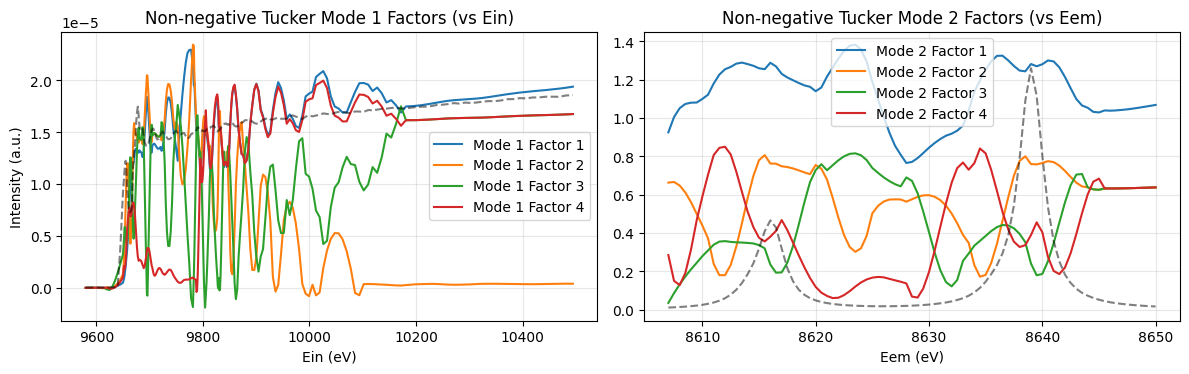

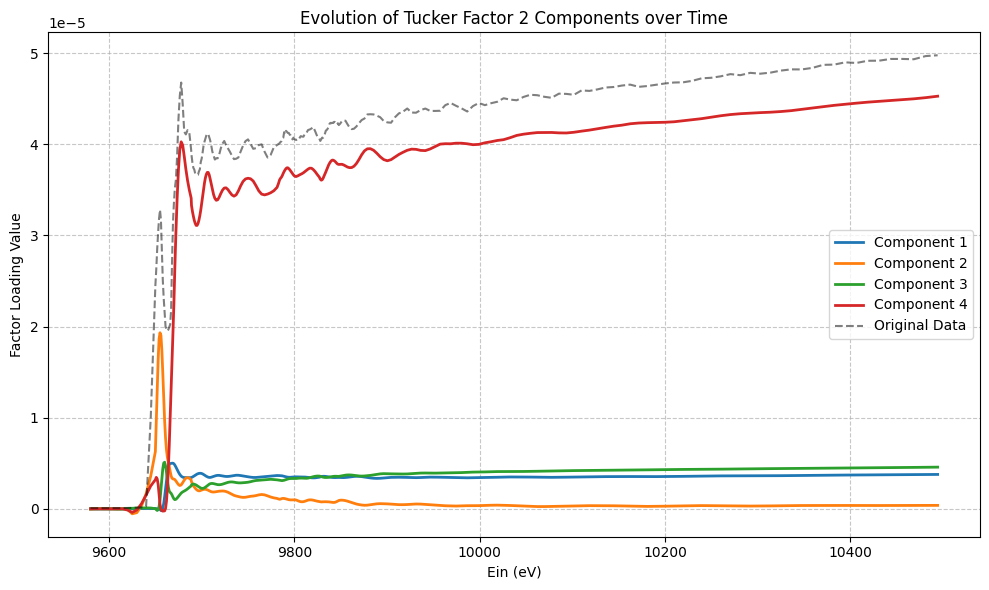

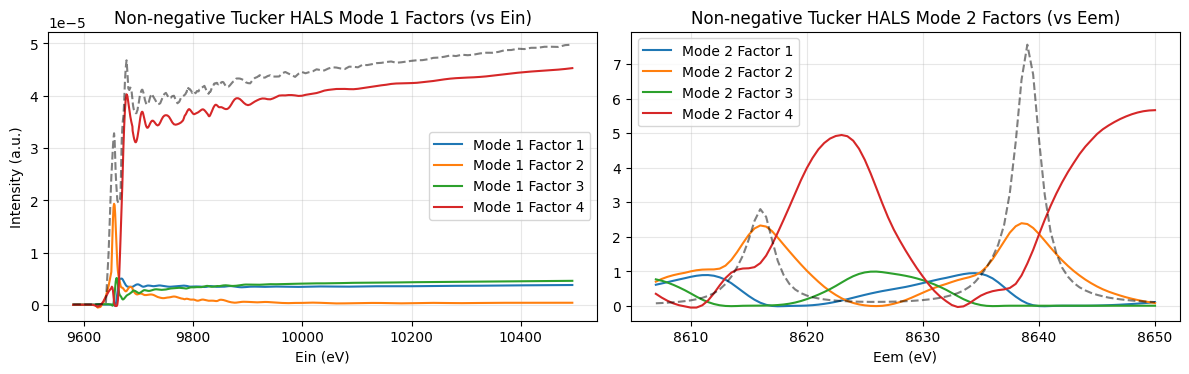

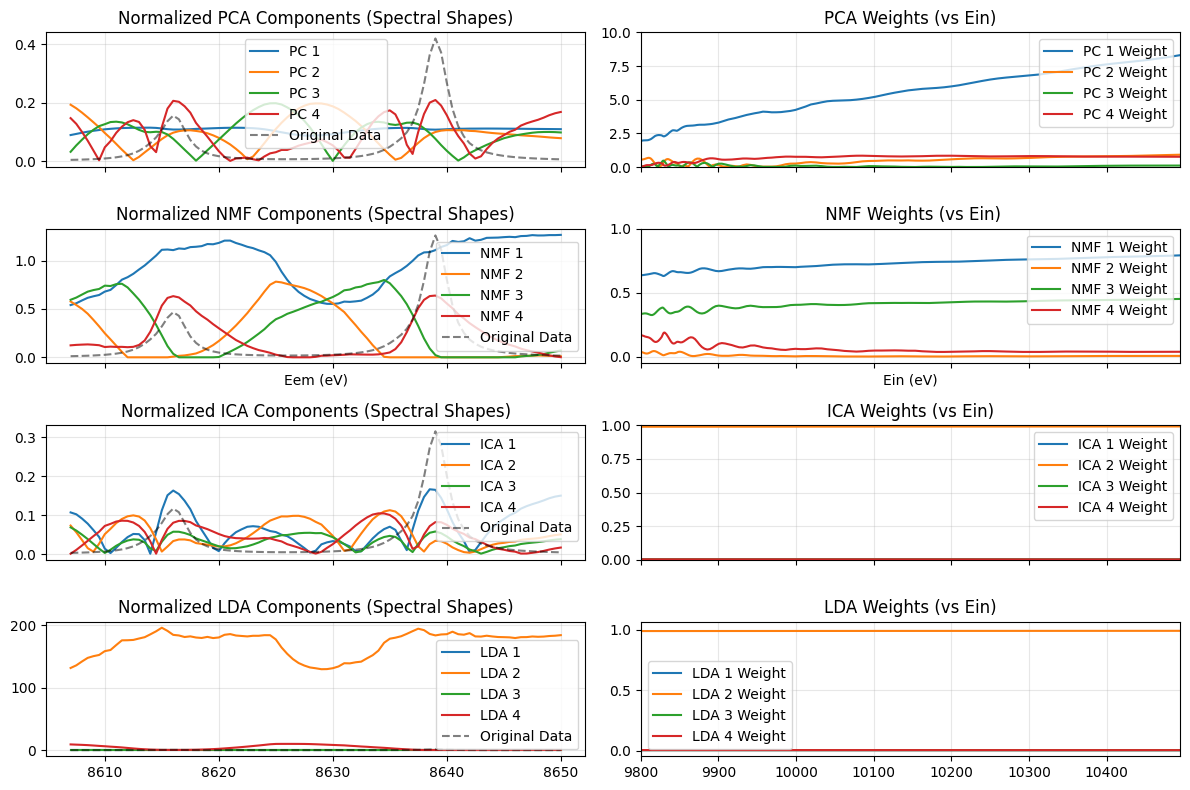

PCA Reconstruction Error (MSE): 0.012801
NMF Reconstruction Error (MSE): 0.000749
ICA Reconstruction Error (MSE): 1.005979
LDA Reconstruction Error (MSE): 25972.772750


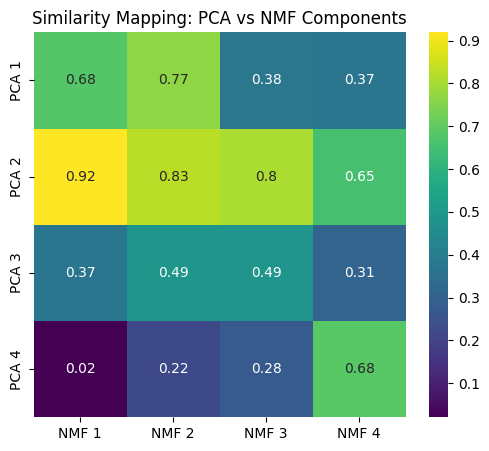

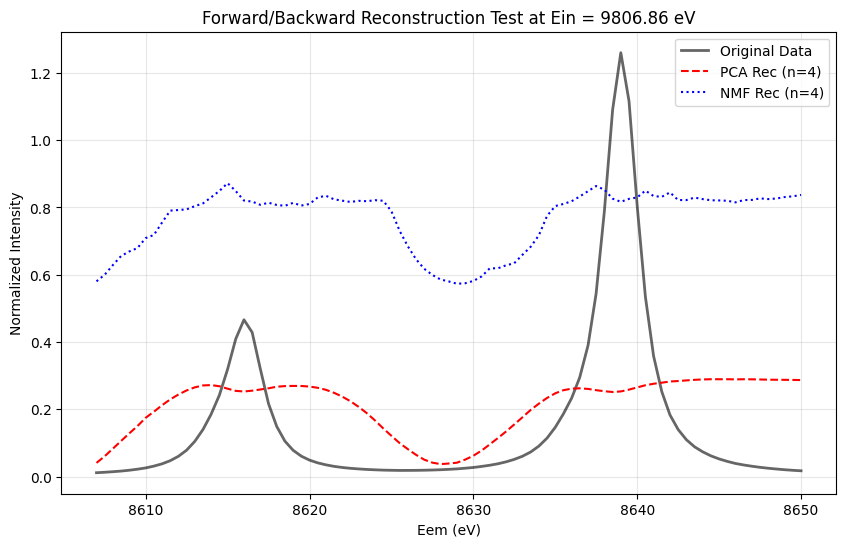

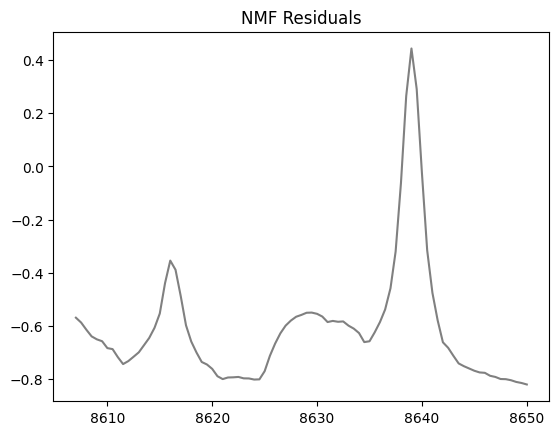

Non-negative Tucker HALS results saved to /Users/chantler/DiamondData/processed_data/nnth_results.pkl
Non-negative Tucker HALS factors saved to CSV files.
Ein and Eem values saved to CSV files.


In [2]:
#PCA and NMF setup for analysis of the combined data

#load the data structure from the pickle file
with open('/Users/chantler/DiamondData/processed_data/Data_struct', 'rb') as f:
    data_structure = pickle.load(f)
print('Data structure loaded from pickle file.')
print('Data structure keys:', data_structure.keys())
print('Data structure types:', {k: type(v) for k, v in data_structure.items()})

comb_data = data_structure['sum_data']
print('comb_data shape:', comb_data.shape)
Ef = data_structure['Ef'][:, 0]  # Assuming Ef is 2D and we want the second column
Ei = data_structure['Ei'][0, :]  # Assuming Ei is 2D and we want the second column
print('Ef shape:', Ef.shape)
print('Ei shape:', Ei.shape)

FFcounts = data_structure['FFcounts']
i1 = data_structure['I1']
X_trans = comb_data.T
print('X_normalized shape:', X_trans.shape)

#setup scaling for PCA and NMF
scaler = StandardScaler()
Nscaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_trans)
X_nscaled = Nscaler.fit_transform(X_trans)
print('X_scaled shape:', X_scaled.shape)
print('X_nscaled shape:', X_nscaled.shape)

print('Imported data and set up PCA and NMF scaling. Ready for analysis.')

# Perform PCA and NMF on the I1-normalized sum data
####################################################################################################
#### Add ICA, LatentDirichletAllocation, DDM and Functional decomposition, Tucker? methods here

#Perform PCA on the I1-normalized sum data
n_components = 4
pca = PCA(n_components=n_components)
W_pca = pca.fit_transform(X_scaled)
H_pca = pca.components_

# Perform NMF on the I1-normalized sum data
nmf = NMF(n_components=n_components, init='nndsvd', max_iter=1000)
W_nmf = nmf.fit_transform(X_nscaled)
H_nmf = nmf.components_

# Perform ICA on the I1-normalized sum data
ica = FastICA(n_components=n_components, algorithm='parallel', max_iter=200, whiten_solver='eigh')
W_ica = ica.fit_transform(X_scaled)
H_ica = ica.components_

# Perfom Latent Dirichlet Allocation on the I1-normalized sum data
lda = LatentDirichletAllocation(n_components=n_components, max_iter=10)
W_ica = lda.fit_transform(X_nscaled)
H_lda = lda.components_

# Perform Tucker decomposition on the I1-normalized sum data
#tucker_rank = [3, 3, 3]  # Define the rank for each mode
#core, factors = Tucker(rank=tucker_rank).fit(X_scaled)


# Perform non-negative Tucker decomposition on the I1-normalized sum data
nn_tucker_rank = [4, 4, 1]  # Define the rank for each mode
nn_core, nn_factors = non_negative_tucker(X_nscaled, rank=nn_tucker_rank, n_iter_max=1000)

#perform NN-Tucker Hals decomp
nnth_rank = [4, 4, 1]
nnth_core, nnth_factors = non_negative_tucker_hals(X_nscaled, rank=nnth_rank, algorithm='fista', n_iter_max=2000, random_state=100)

#perform PARAFAC
#pfc_rank = (4, 4, 1)
#pfc_core, pfc_factors = parafac(X_nscaled, rank=pfc_rank, n_iter_max=100)

#perform PARAFAC2
#pfc2_rank = (4, 4, 1)
#pfc2_core, pfc2_factors = parafac(X_nscaled, rank=pfc2_rank, n_iter_max=100)

window = 11
poly_order = 3

#smooth the PCA and NMF weights using Savitzky-Golay filter
W_pca_smooth = np.zeros_like(W_pca)
W_nmf_smooth = np.zeros_like(W_nmf)
W_ica_smooth = np.zeros_like(W_ica)
W_lda_smooth = np.zeros_like(W_ica) 


for i in range(n_components):
    W_pca_smooth[:, i] = savgol_filter(W_pca[:, i], window, poly_order)
    W_nmf_smooth[:, i] = savgol_filter(W_nmf[:, i], window, poly_order)
    W_ica_smooth[:, i] = savgol_filter(W_ica[:, i], window, poly_order)
    W_lda_smooth[:, i] = savgol_filter(W_ica[:, i], window, poly_order)
    
#smooth the nn_tucker factors using Savitzky-Golay filter
nn_factors_smooth = [np.zeros_like(factor) for factor in nn_factors]
for mode in range(len(nn_factors)):
    for i in range(nn_factors[mode].shape[1]):
        nn_factors_smooth[mode][:, i] = savgol_filter(nn_factors[mode][:, i], window, poly_order)

#smooth the nnth_tucker factors using Savitzky-Golay filter        
nnth_factors_smooth = [np.zeros_like(factor) for factor in nnth_factors]
for mode in range(len(nnth_factors)):
    for i in range(nnth_factors[mode].shape[1]):
        nnth_factors_smooth[mode][:, i] = savgol_filter(nnth_factors[mode][:, i], window, poly_order)   
        
#create test points for later
test_idx = X_trans.shape[0] // 2
ein_val = Ei[test_idx]

# --- 2D Plots of nn_tucker factors against the original data ---

fig, axes = plt.subplots(1, len(nn_factors), figsize=(12, 4), sharex='col')
for mode in range(len(nn_factors)):
    for i in range(nn_factors[mode].shape[1]):
        if mode == 0:
            axes[mode].plot(Ei, nn_factors_smooth[mode][:, i], label=f'Mode {mode+1} Factor {i+1}')
        else:
            axes[mode].plot(Ef, nn_factors_smooth[mode][:, i], label=f'Mode {mode+1} Factor {i+1}')
    axes[mode].set_title(f'Non-negative Tucker Mode {mode+1} Factors')
    axes[mode].legend()
    axes[mode].grid(True, alpha=0.3)
axes[0].plot(Ei, X_trans[:, 32]/1500, 'k--', label='Original Data', alpha=0.5)
axes[1].plot(Ef, X_trans[test_idx, :], 'k--', label='Original Data', alpha=0.5)
axes[0].set_title('Non-negative Tucker Mode 1 Factors (vs Ein)')
axes[1].set_title('Non-negative Tucker Mode 2 Factors (vs Eem)')
axes[0].set_ylabel('Intensity (a.u.)')
axes[0].set_xlabel('Ein (eV)')
axes[1].set_xlabel('Eem (eV)')

plt.tight_layout()
plt.show()

# --- Evolution of Tucker factor 2 ---
time_mode_index = 0
time_factor_matrix = nnth_factors_smooth[time_mode_index]
plt.figure(figsize=(10, 6))

# Plot each column of the factor matrix
for i in range(time_factor_matrix.shape[1]):
    plt.plot(Ei, time_factor_matrix[:, i], label=f'Component {i+1}', linewidth=2)
plt.plot(Ei, X_trans[:, 32]/560, 'k--', label='Original Data', alpha=0.5)
plt.title('Evolution of Tucker Factor 2 Components over Time')
plt.xlabel('Ein (eV)')
plt.ylabel('Factor Loading Value')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# --- 2D Plots of nnth factors against the original data ---

fig, axes = plt.subplots(1, len(nnth_factors), figsize=(12, 4), sharex='col')
for mode in range(len(nnth_factors)):
    for i in range(nnth_factors_smooth[mode].shape[1]):
        if mode == 0:
            axes[mode].plot(Ei, nnth_factors_smooth[mode][:, i], label=f'Mode {mode+1} Factor {i+1}')
        else:
            axes[mode].plot(Ef, nnth_factors_smooth[mode][:, i], label=f'Mode {mode+1} Factor {i+1}')
    axes[mode].set_title(f'Non-negative Tucker HALS Mode {mode+1} Factors')
    axes[mode].legend()
    axes[mode].grid(True, alpha=0.3)
axes[0].plot(Ei, X_trans[:, 32]/560, 'k--', label='Original Data', alpha=0.5)
axes[1].plot(Ef, X_trans[test_idx, :]*6, 'k--', label='Original Data', alpha=0.5)
axes[0].set_title('Non-negative Tucker HALS Mode 1 Factors (vs Ein)')
axes[1].set_title('Non-negative Tucker HALS Mode 2 Factors (vs Eem)')
axes[0].set_ylabel('Intensity (a.u.)')
axes[0].set_xlabel('Ein (eV)')
axes[1].set_xlabel('Eem (eV)')

plt.tight_layout()
plt.show()

# --- 2D Plots of PCA and NMF Components and Weights ---
fig, axes = plt.subplots(4, 2, figsize=(12, 8), sharex='col')


# --- PCA Plots ---
for i in range(n_components):
    axes[0, 0].plot(Ef, abs(H_pca[i]), label=f'PC {i+1}')
    axes[0, 1].plot(Ei.T, abs(W_pca_smooth[:, i]), label=f'PC {i+1} Weight')
axes[0, 0].plot(Ef, X_trans[test_idx, :]/3, 'k--', label='Original Data', alpha=0.5)
axes[0, 0].set_title('Normalized PCA Components (Spectral Shapes)')
axes[0, 1].set_title('PCA Weights (vs Ein)')

#set readable axes limits for the PCA and NMF weight plots
Ei_min = 9800
W_pcamax = 10
W_nmfmax = 1
axes[0, 1].set_xlim(Ei_min, np.max(Ei.T))
axes[0, 1].set_ylim(0, W_pcamax)
axes[1, 1].set_xlim(Ei_min, np.max(Ei.T))
axes[1, 1].set_ylim(np.min(W_nmf_smooth), W_nmfmax)
axes[2, 1].set_xlim(Ei_min, np.max(Ei.T))
axes[2, 1].set_ylim(0, W_nmfmax)


# --- NMF Plots ---
for i in range(n_components):
    axes[1, 0].plot(Ef, H_nmf[i], label=f'NMF {i+1}')
    axes[1, 1].plot(Ei.T, W_nmf_smooth[:, i], label=f'NMF {i+1} Weight')
    
# plot original data for comparison
axes[1, 0].plot(Ef, X_trans[test_idx, :], 'k--', label='Original Data', alpha=0.5)
axes[1, 0].set_title('Normalized NMF Components (Spectral Shapes)')
axes[1, 1].set_title(' NMF Weights (vs Ein)')

# --- ICA Plots ---
for i in range(n_components):
    axes[2, 0].plot(Ef, abs(H_ica[i]), label=f'ICA {i+1}')
    axes[2, 1].plot(Ei.T, abs(W_ica_smooth[:, i]), label=f'ICA {i+1} Weight')
axes[2, 0].plot(Ef, X_trans[test_idx, :]/4, 'k--', label='Original Data', alpha=0.5)
axes[2, 0].set_title('Normalized ICA Components (Spectral Shapes)')
axes[2, 1].set_title('ICA Weights (vs Ein)')

# --- LDA Plots ---
for i in range(n_components):
    axes[3, 0].plot(Ef, abs(H_lda[i]), label=f'LDA {i+1}')
    axes[3, 1].plot(Ei.T, abs(W_lda_smooth[:, i]), label=f'LDA {i+1} Weight')
axes[3, 0].plot(Ef, X_trans[test_idx, :], 'k--', label='Original Data', alpha=0.5)
axes[3, 0].set_title('Normalized LDA Components (Spectral Shapes)')
axes[3, 1].set_title('LDA Weights (vs Ein)')

# Formatting
for ax in axes.flat:
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[1, 0].set_xlabel('Eem (eV)')
axes[1, 1].set_xlabel('Ein (eV)')
plt.tight_layout()
plt.show()


#Create reconstructed data from PCA and NMF
X_pca_rec = np.dot(W_pca, H_pca) + pca.mean_  # Add mean back for PCA
X_nmf_rec = np.dot(W_nmf, H_nmf)
X_ica_rec = np.dot(W_ica, H_ica) + ica.mean_  # Add mean back for ICA
X_lda_rec = np.dot(W_ica, H_lda) 

#Create reconstructed data from non-negative Tucker decomposition


# --- 3. Quantify the Error ---
mse_pca = mean_squared_error(X_scaled, X_pca_rec)
mse_nmf = mean_squared_error(X_nscaled, X_nmf_rec)
mse_ica = mean_squared_error(X_scaled, X_ica_rec)
mse_lda = mean_squared_error(X_scaled, X_lda_rec)



print(f"PCA Reconstruction Error (MSE): {mse_pca:.6f}")
print(f"NMF Reconstruction Error (MSE): {mse_nmf:.6f}")
print(f"ICA Reconstruction Error (MSE): {mse_ica:.6f}")
print(f"LDA Reconstruction Error (MSE): {mse_lda:.6f}")


#Correlation analysis between PCA and NMF components
import seaborn as sns
# Calculate correlation between spectral shapes (H matrices)
# We compare the first n_comp of each
corr = np.corrcoef(H_pca, H_nmf[:n_components, :])
# We only want the cross-correlation block (PCA vs NMF)
cross_corr = corr[:n_components, n_components:]

plt.figure(figsize=(6, 5))
sns.heatmap(np.abs(cross_corr), annot=True, xticklabels=[f'NMF {i+1}' for i in range(n_components)], 
            yticklabels=[f'PCA {i+1}' for i in range(n_components)], cmap='viridis')
plt.title('Similarity Mapping: PCA vs NMF Components')
plt.show()

plt.figure(figsize=(10, 6))
# Plot Original
plt.plot(Ef, X_trans[test_idx, :], 'k-', lw=2, label='Original Data', alpha=0.6)

# Plot PCA Reconstruction
plt.plot(Ef, X_pca_rec[test_idx, :], 'r--', label=f'PCA Rec (n={n_components})')

# Plot NMF Reconstruction
plt.plot(Ef, X_nmf_rec[test_idx, :], 'b:', label=f'NMF Rec (n={n_components})')

plt.title(f'Forward/Backward Reconstruction Test at Ein = {ein_val:.2f} eV')
plt.xlabel('Eem (eV)')
plt.ylabel('Normalized Intensity')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

residual_nmf = X_trans[test_idx, :] - X_nmf_rec[test_idx, :]
plt.figure()
plt.plot(Ef, residual_nmf, color='gray')
plt.title('NMF Residuals')
plt.show()

#save the nnth factors and core to a pickle file for later use
nnth_results = {
    'nnth_core': nnth_core,
    'nnth_factors': nnth_factors,
    'nnth_factors_smooth': nnth_factors_smooth,
    'nnth_rank': nnth_rank
}   
pickle_file_path = '/Users/chantler/DiamondData/processed_data/nnth_results.pkl'
with open(pickle_file_path, 'wb') as f:
    pickle.dump(nnth_results, f)
print(f"Non-negative Tucker HALS results saved to {pickle_file_path}")
import pandas as pd
#save the nnth factors to a CSV file for later use
nnth_factors_df = pd.DataFrame(nnth_factors_smooth[0], columns=[f'Mode1_Factor{i+1}' for i in range(nnth_factors_smooth[0].shape[1])])
nnth_factors_df.to_csv('/Users/chantler/DiamondData/processed_data/nnth_factors_mode1.csv', index=False)
nnth_factors_df = pd.DataFrame(nnth_factors_smooth[1], columns=[f'Mode2_Factor{i+1}' for i in range(nnth_factors_smooth[1].shape[1])])
nnth_factors_df.to_csv('/Users/chantler/DiamondData/processed_data/nnth_factors_mode2.csv', index=False)
print("Non-negative Tucker HALS factors saved to CSV files.")
#save Ei and Ef to CSV for reference
Ei_df = pd.DataFrame(Ei, columns=['Ein'])
Ei_df.to_csv('/Users/chantler/DiamondData/processed_data/Ein_values.csv', index=False)
Ef_df = pd.DataFrame(Ef, columns=['Eem'])
Ef_df.to_csv('/Users/chantler/DiamondData/processed_data/Eem_values.csv', index=False)
print("Ein and Eem values saved to CSV files.")


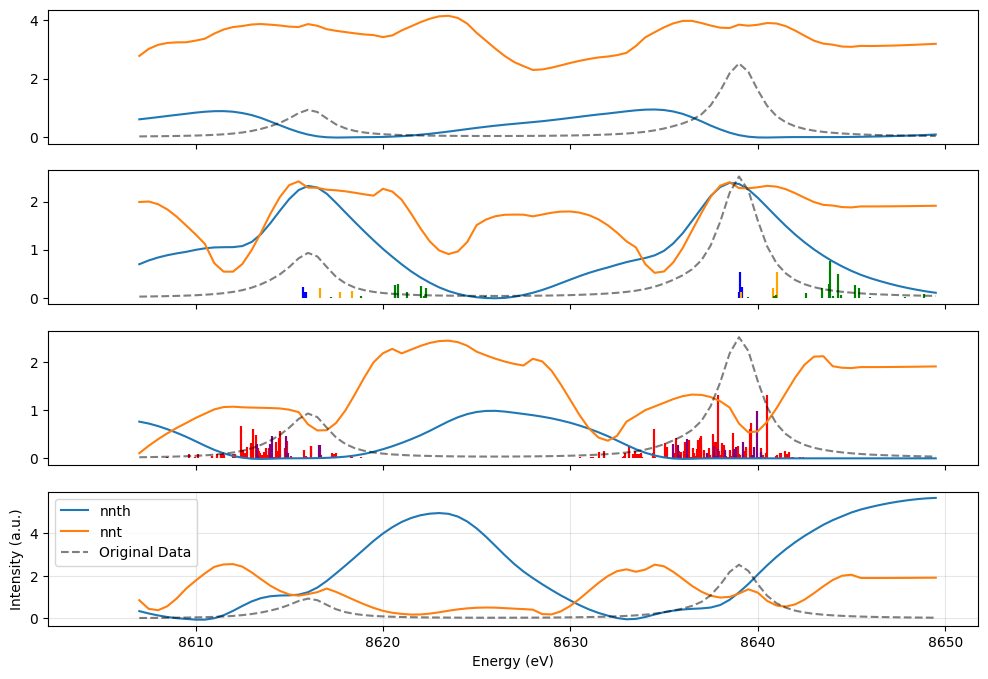

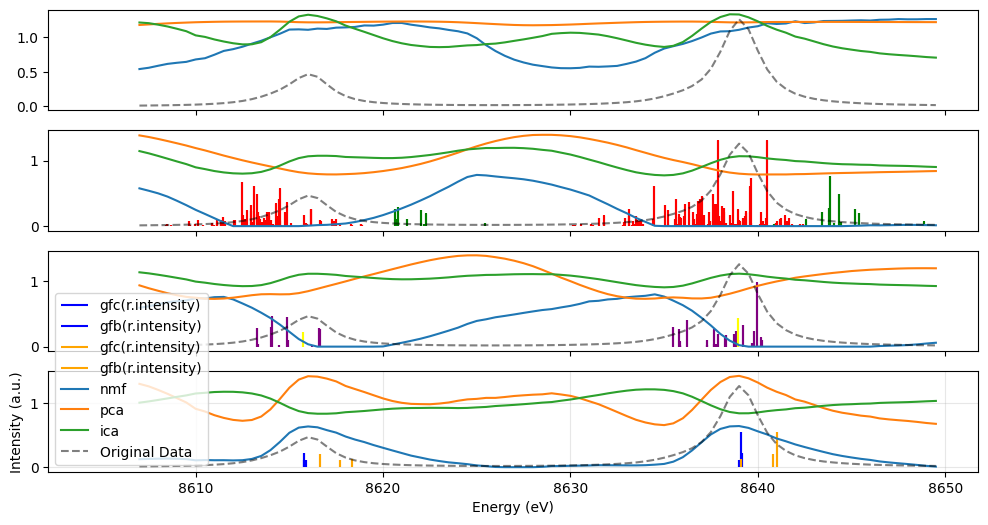

In [3]:
# dataframe for initial data.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

n_components = 4  # Number of components for PCA/NMF/ICA

# Read in info from the transition files
Dia = read_ct("/Users/chantler/DiamondData/TransitionFiles/ZnDiagram-A6g.txt")
FrameDia = pd.DataFrame(Dia, index = [ "Energy (ev)","Ac (s-1)", "Ab(s-1)", "gfc(r.intensity)", "gfb(r.intensity)","Ulev","Llev","UJ","LJ"])
s4s = read_ct("/Users/chantler/DiamondData/TransitionFiles/Zn4s1-A6s.txt")
Frame4s = pd.DataFrame(s4s, index = [ "Energy (ev)","Ac (s-1)", "Ab(s-1)", "gfc(r.intensity)", "gfb(r.intensity)","Ulev","Llev","UJ","LJ"])
s3s = read_ct("/Users/chantler/DiamondData/TransitionFiles/Zn3s1-B6g.txt")
Frame3s = pd.DataFrame(s3s, index = [ "Energy (ev)","Ac (s-1)", "Ab(s-1)", "gfc(r.intensity)", "gfb(r.intensity)","Ulev","Llev","UJ","LJ"])
s3p5 = read_ct("/Users/chantler/DiamondData/TransitionFiles/Zn3p5-B5g.txt")
Frame3p5 = pd.DataFrame(s3p5, index = [ "Energy (ev)","Ac (s-1)", "Ab(s-1)", "gfc(r.intensity)", "gfb(r.intensity)","Ulev","Llev","UJ","LJ"])
s3d8 = read_ct("/Users/chantler/DiamondData/TransitionFiles/Zn3d8-5p.txt")
Frame3d8 = pd.DataFrame(s3d8, index = [ "Energy (ev)","Ac (s-1)", "Ab(s-1)", "gfc(r.intensity)", "gfb(r.intensity)","Ulev","Llev","UJ","LJ"])   
s3d9 = read_ct("/Users/chantler/DiamondData/TransitionFiles/Zn3d9-B6s.txt")
Frame3d9 = pd.DataFrame(s3d9, index = [ "Energy (ev)","Ac (s-1)", "Ab(s-1)", "gfc(r.intensity)", "gfb(r.intensity)","Ulev","Llev","UJ","LJ"])   
s3d4s = read_ct("/Users/chantler/DiamondData/TransitionFiles/Zn3d4s-B5s.txt")
Frames3d4s = pd.DataFrame(s3d4s, index = [ "Energy (ev)","Ac (s-1)", "Ab(s-1)", "gfc(r.intensity)", "gfb(r.intensity)","Ulev","Llev","UJ","LJ"])

fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex='col')
# Plot the transition data
axes[1].vlines(Frame4s.loc["Energy (ev)"], 0, Frame4s.loc["gfc(r.intensity)"], label='gfc(r.intensity)', color='blue')
axes[1].vlines(Frame4s.loc["Energy (ev)"], 0, Frame4s.loc["gfb(r.intensity)"], label='gfb(r.intensity)', color='blue')
axes[1].vlines(Frame3s.loc["Energy (ev)"], 0, Frame3s.loc["gfc(r.intensity)"], label='gfc(r.intensity)', color='orange')
axes[1].vlines(Frame3s.loc["Energy (ev)"], 0, Frame3s.loc["gfb(r.intensity)"],  label='gfb(r.intensity)', color='orange')
axes[1].vlines(Frame3p5.loc["Energy (ev)"], 0, Frame3p5.loc["gfc(r.intensity)"], label='gfc(r.intensity)', color='green')
axes[1].vlines(Frame3p5.loc["Energy (ev)"], 0, Frame3p5.loc["gfb(r.intensity)"], label='gfb(r.intensity)', color='green')
axes[2].vlines(Frame3d8.loc["Energy (ev)"], 0, Frame3d8.loc["gfc(r.intensity)"], label='gfc(r.intensity)', color='red')
axes[2].vlines(Frame3d8.loc["Energy (ev)"], 0, Frame3d8.loc["gfb(r.intensity)"], label='gfb(r.intensity)', color='red')
axes[2].vlines(Frame3d9.loc["Energy (ev)"], 0, Frame3d9.loc["gfc(r.intensity)"], label='gfc(r.intensity)', color='purple')
axes[2].vlines(Frame3d9.loc["Energy (ev)"], 0, Frame3d9.loc["gfb(r.intensity)"], label='gfb(r.intensity)', color='purple')

#plot the nnth_tucker factors for comparison
for i in range(n_components):
    axes[i].plot(Ef[:-1], nnth_factors_smooth[mode][:-1, i], label=f'nnth')
    axes[i].plot(Ef[:-1], nn_factors_smooth[mode][:-1, i]*3, label=f'nnt')
    axes[i].plot(Ef[:-1], X_trans[test_idx, :-1]*2, 'k--', label='Original Data', alpha=0.5)

    
plt.xlabel('Energy (eV)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#plot the broadened transition data for comparison with the nnth_tucker factors
Fig, Axes = plt.subplots(4,1,figsize=(12, 6), sharex='col')
Axes[3].vlines(Frame4s.loc["Energy (ev)"], 0, Frame4s.loc["gfc(r.intensity)"], label='gfc(r.intensity)', color='blue')
Axes[3].vlines(Frame4s.loc["Energy (ev)"], 0, Frame4s.loc["gfb(r.intensity)"], label='gfb(r.intensity)', color='blue')
Axes[3].vlines(Frame3s.loc["Energy (ev)"], 0, Frame3s.loc["gfc(r.intensity)"], label='gfc(r.intensity)', color='orange')
Axes[3].vlines(Frame3s.loc["Energy (ev)"], 0, Frame3s.loc["gfb(r.intensity)"],  label='gfb(r.intensity)', color='orange')
Axes[1].vlines(Frame3p5.loc["Energy (ev)"], 0, Frame3p5.loc["gfc(r.intensity)"], label='gfc(r.intensity)', color='green')
Axes[1].vlines(Frame3p5.loc["Energy (ev)"], 0, Frame3p5.loc["gfb(r.intensity)"], label='gfb(r.intensity)', color='green')
Axes[1].vlines(Frame3d8.loc["Energy (ev)"], 0, Frame3d8.loc["gfc(r.intensity)"], label='gfc(r.intensity)', color='red')
Axes[1].vlines(Frame3d8.loc["Energy (ev)"], 0, Frame3d8.loc["gfb(r.intensity)"], label='gfb(r.intensity)', color='red')
Axes[2].vlines(Frame3d9.loc["Energy (ev)"], 0, Frame3d9.loc["gfc(r.intensity)"], label='gfc(r.intensity)', color='purple')
Axes[2].vlines(Frame3d9.loc["Energy (ev)"], 0, Frame3d9.loc["gfb(r.intensity)"], label='gfb(r.intensity)', color='purple')
Axes[2].vlines(FrameDia.loc["Energy (ev)"], 0, FrameDia.loc["gfc(r.intensity)"], label='gfc(r.intensity)', color='yellow')
Axes[2].vlines(FrameDia.loc["Energy (ev)"], 0, FrameDia.loc["gfb(r.intensity)"], label='gfb(r.intensity)', color='yellow')

for i in range(n_components):
    Axes[i].plot(Ef[:-1], nmf.components_[i, :-1], label=f'nmf')
    Axes[i].plot(Ef[:-1], ((pca.components_[i, :-1]+1)*2-1), label=f'pca')
    Axes[i].plot(Ef[:-1], ((ica.components_[i, :-1]+1)*2-1), label=f'ica')
    Axes[i].plot(Ef[:-1], X_trans[test_idx, :-1], 'k--', label='Original Data', alpha=0.5)
#Axes[1].vlines(Frame4s.loc["Energy (ev)"], 0, Frame4s_broadened, label='Zn 4s1-A6s', color='blue')
#Axes[1].vlines(Frame3s.loc["Energy (ev)"], 0, Frame3s_broadened, label='Zn 3s1-B6g', color='orange')
#Axes[3].vlines(Frame3p5.loc["Energy (ev)"], 0, Frame3p5_broadened, label='Zn 3p5-B5g', color='green')
#Axes[0].vlines(Frame3d8.loc["Energy (ev)"], 0, Frame3d8_broadened, label='Zn 3d8-5p', color='red')
#Axes[2].vlines(Frame3d9.loc["Energy (ev)"], 0, Frame3d9_broadened, label='Zn 3d9-B6s', color='purple')
plt.xlabel('Energy (eV)')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

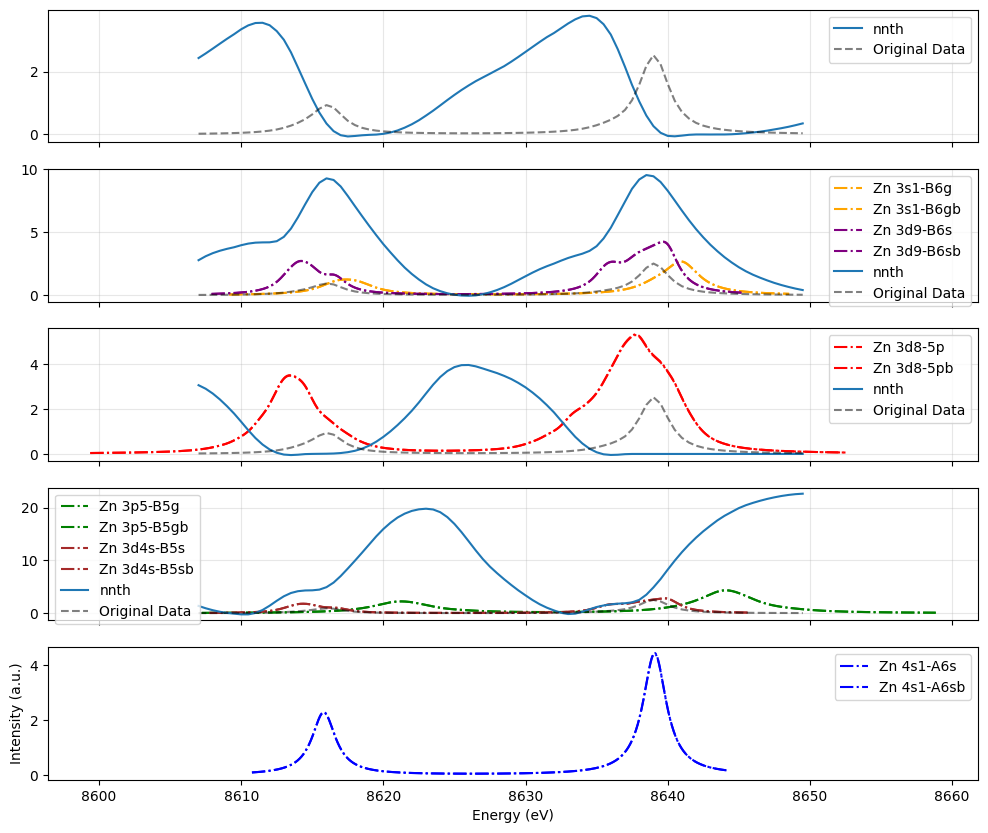

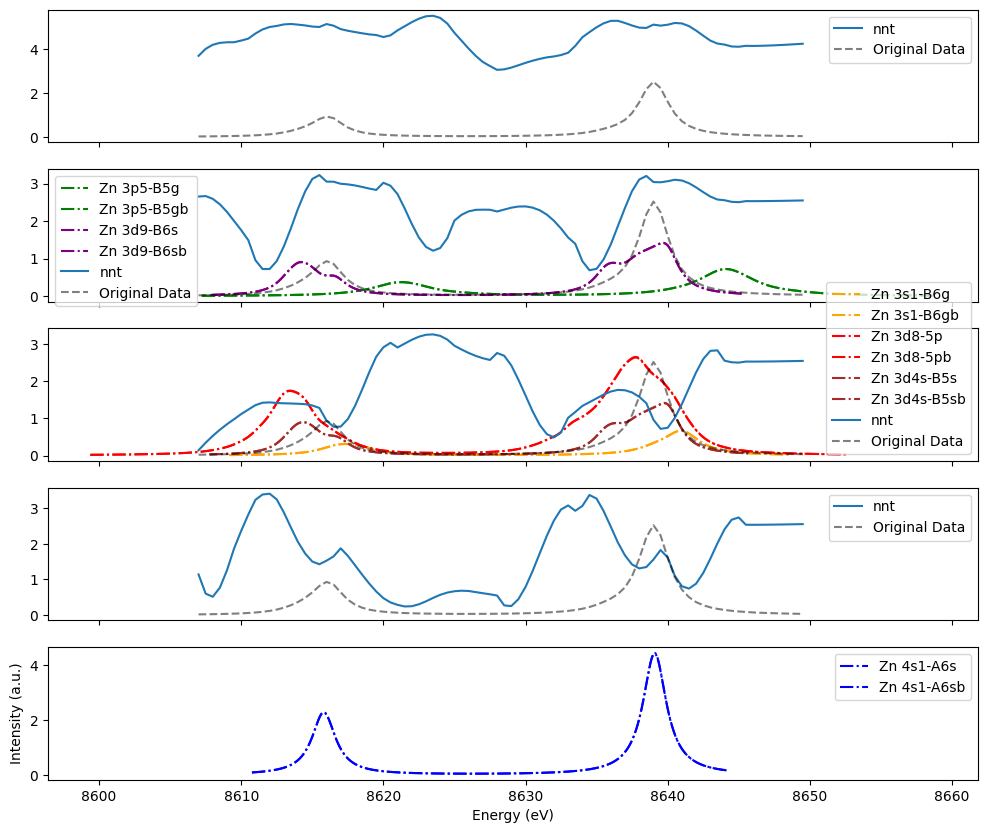

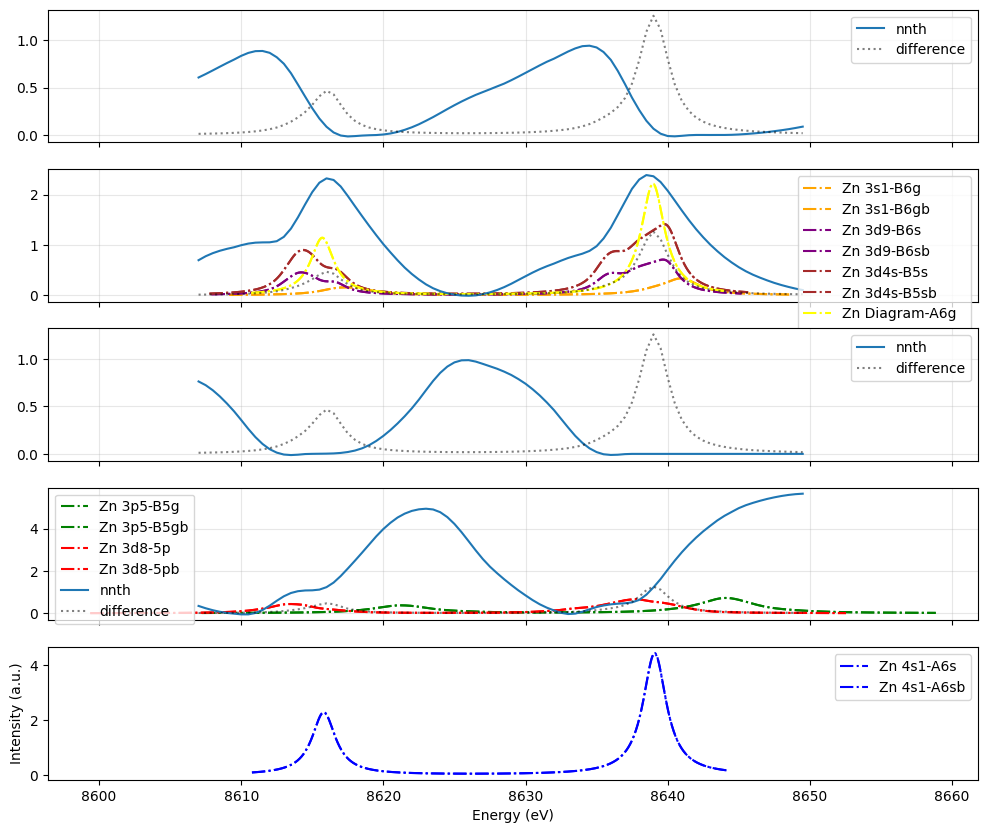

In [4]:
# fitting of broadened sattelites.
from scipy.stats import gaussian_kde
from pandas import concat

def single_lorentzian(x, x0, gamma, amplitude):
    # Standard Lorentzian function
    return amplitude * (gamma / np.pi) / ((x - x0)**2 + gamma**2)

#define a function to broaden the transition data points for better visualization using kde
def broaden_transition_data(energies, intensities, broadening_width):
    # Create a range of energy values for the broadened spectrum
    energy_range = np.linspace(np.min(energies)-broadening_width*5, np.max(energies)+broadening_width*5, 1000)
    
    # Initialize the broadened intensity array
    broadened_intensity = np.zeros_like(energy_range)
    
    # Apply Gaussian broadening to each transition
    for energy, intensity in zip(energies, intensities):
        broadened_intensity += single_lorentzian(energy_range, energy, broadening_width, intensity)
    return energy_range, broadened_intensity
    
#Broadening transition data with a Gaussian function for better visualization
broadening_width = 1  # Adjust this value for more or less broadening
broadening_widthlist =[1, 1.5, 2, 1, 1, 1, 1]
Framelist = [Frame4s, Frame3s, Frame3p5, Frame3d8, Frame3d9, Frames3d4s, FrameDia]
Framelist_broadened = tuple()

#for Frame in Framelist:
#    i=0
#    print(Frame.shape
#    print(Frame)
#    Framelist_broadened.append = np.array(broaden_transition_data(Frame.loc["Energy (ev)"],Frame.loc["gfc(r.intensity)"], broadening_widthlist[i])),
#    Framelist_broadened.append = np.array(broaden_transition_data(Frame.loc["Energy (ev)"],Frame.loc["gfb(r.intensity)"], broadening_widthlist[i]))
#    print(Frame)
#    i=i+1
#print(Framelist_broadened)
        
Frame4sc_broadened = broaden_transition_data(Frame4s.loc["Energy (ev)"], Frame4s.loc["gfc(r.intensity)"], broadening_width)
Frame4sb_broadened = broaden_transition_data(Frame4s.loc["Energy (ev)"], Frame4s.loc["gfb(r.intensity)"], broadening_width)
Frame3sc_broadened = broaden_transition_data(Frame3s.loc["Energy (ev)"], Frame3s.loc["gfc(r.intensity)"], 1.5*broadening_width)
Frame3sb_broadened = broaden_transition_data(Frame3s.loc["Energy (ev)"], Frame3s.loc["gfb(r.intensity)"], 1.5*broadening_width)
Frame3p5c_broadened = broaden_transition_data(Frame3p5.loc["Energy (ev)"], Frame3p5.loc["gfc(r.intensity)"], 2*broadening_width)
Frame3p5b_broadened = broaden_transition_data(Frame3p5.loc["Energy (ev)"], Frame3p5.loc["gfb(r.intensity)"], 2*broadening_width)
Frame3d8c_broadened = broaden_transition_data(Frame3d8.loc["Energy (ev)"], Frame3d8.loc["gfc(r.intensity)"], broadening_width)
Frame3d8b_broadened = broaden_transition_data(Frame3d8.loc["Energy (ev)"], Frame3d8.loc["gfb(r.intensity)"], broadening_width)
Frame3d9c_broadened = broaden_transition_data(Frame3d9.loc["Energy (ev)"], Frame3d9.loc["gfc(r.intensity)"], broadening_width)
Frame3d9b_broadened = broaden_transition_data(Frame3d9.loc["Energy (ev)"], Frame3d9.loc["gfb(r.intensity)"], broadening_width)
Frame3d4sc_broadened = broaden_transition_data(Frames3d4s.loc["Energy (ev)"], Frames3d4s.loc["gfc(r.intensity)"], broadening_width)
Frames3d4sb_broadened = broaden_transition_data(Frames3d4s.loc["Energy (ev)"], Frames3d4s.loc["gfb(r.intensity)"], broadening_width)
FrameDiac_broadened = broaden_transition_data(FrameDia.loc["Energy (ev)"], FrameDia.loc["gfc(r.intensity)"], broadening_width)
FrameDiab_broadened = broaden_transition_data(FrameDia.loc["Energy (ev)"], FrameDia.loc["gfb(r.intensity)"], broadening_width)

Fig, Axes = plt.subplots(5,1,figsize=(12, 10), sharex='col')
Axes[4].plot(Frame4sc_broadened[0], Frame4sc_broadened[1]*16, '-.', label='Zn 4s1-A6s', color='blue')
Axes[4].plot(Frame4sb_broadened[0], Frame4sb_broadened[1]*16, '-.', label='Zn 4s1-A6sb', color='blue')
Axes[1].plot(Frame3sc_broadened[0], Frame3sc_broadened[1]*16, '-.', label='Zn 3s1-B6g', color='orange')
Axes[1].plot(Frame3sb_broadened[0], Frame3sb_broadened[1]*16, '-.', label='Zn 3s1-B6gb', color='orange')
Axes[3].plot(Frame3p5c_broadened[0], Frame3p5c_broadened[1]*12, '-.', label='Zn 3p5-B5g', color='green')
Axes[3].plot(Frame3p5b_broadened[0], Frame3p5b_broadened[1]*12, '-.', label='Zn 3p5-B5gb', color='green')
Axes[2].plot(Frame3d8c_broadened[0], Frame3d8c_broadened[1]*2, '-.', label='Zn 3d8-5p', color='red')
Axes[2].plot(Frame3d8b_broadened[0], Frame3d8b_broadened[1]*2, '-.', label='Zn 3d8-5pb', color='red')
Axes[1].plot(Frame3d9c_broadened[0], Frame3d9c_broadened[1]*6, '-.', label='Zn 3d9-B6s', color='purple')
Axes[1].plot(Frame3d9b_broadened[0], Frame3d9b_broadened[1]*6, '-.', label='Zn 3d9-B6sb', color='purple')
Axes[3].plot(Frame3d4sc_broadened[0], Frame3d4sc_broadened[1]*2, '-.', label='Zn 3d4s-B5s', color='brown')
Axes[3].plot(Frames3d4sb_broadened[0], Frames3d4sb_broadened[1]*2, '-.', label='Zn 3d4s-B5sb', color='brown')

for i in range(n_components):
    #Axes[i].plot(Ef[:-1], nn_factors_smooth[mode][:-1, i]*4, label=f'nnt')
    Axes[i].plot(Ef[:-1], nnth_factors_smooth[mode][:-1, i]*4, label=f'nnth')
    #Axes[i].plot(Ef[:-1], nmf.components_[i, :-1]*2, label=f'nmf')
    
    Axes[i].plot(Ef[:-1], X_trans[test_idx, :-1]*2, 'k--', label='Original Data', alpha=0.5)
    Axes[i].grid(True, alpha=0.3)
    
#Axes[1].plot(Ef[:-1], nnth_factors_smooth[mode][:-1, 3]/2, label=f'nnth F4')
#Axes[2].plot(Ef[:-1], nnth_factors_smooth[mode][:-1, 2]/2, label=f'nnth F3')
#Axes[2].plot(Ef[:-1], nnth_factors_smooth[mode][:-1, 1], label=f'nnth F2')
#Axes[0].plot(Ef[:-1], nnth_factors_smooth[mode][:-1, 0]*6, label=f'nnth F1')
for i in range(5):
    Axes[i].legend()
plt.xlabel('Energy (eV)')
plt.ylabel('Intensity (a.u.)')
plt.legend()

Fig2, Axes2 = plt.subplots(5,1,figsize=(12, 10), sharex='col')
Axes2[4].plot(Frame4sc_broadened[0], Frame4sc_broadened[1]*16, '-.', label='Zn 4s1-A6s', color='blue')
Axes2[4].plot(Frame4sb_broadened[0], Frame4sb_broadened[1]*16, '-.', label='Zn 4s1-A6sb', color='blue')
Axes2[2].plot(Frame3sc_broadened[0], Frame3sc_broadened[1]*4, '-.', label='Zn 3s1-B6g', color='orange')
Axes2[2].plot(Frame3sb_broadened[0], Frame3sb_broadened[1]*4, '-.', label='Zn 3s1-B6gb', color='orange')
Axes2[1].plot(Frame3p5c_broadened[0], Frame3p5c_broadened[1]*2, '-.', label='Zn 3p5-B5g', color='green')
Axes2[1].plot(Frame3p5b_broadened[0], Frame3p5b_broadened[1]*2, '-.', label='Zn 3p5-B5gb', color='green')
Axes2[2].plot(Frame3d8c_broadened[0], Frame3d8c_broadened[1], '-.', label='Zn 3d8-5p', color='red')
Axes2[2].plot(Frame3d8b_broadened[0], Frame3d8b_broadened[1], '-.', label='Zn 3d8-5pb', color='red')
Axes2[1].plot(Frame3d9c_broadened[0], Frame3d9c_broadened[1]*2, '-.', label='Zn 3d9-B6s', color='purple')
Axes2[1].plot(Frame3d9b_broadened[0], Frame3d9b_broadened[1]*2, '-.', label='Zn 3d9-B6sb', color='purple')
Axes2[2].plot(Frame3d4sc_broadened[0], Frame3d4sc_broadened[1], '-.', label='Zn 3d4s-B5s', color='brown')
Axes2[2].plot(Frames3d4sb_broadened[0], Frames3d4sb_broadened[1], '-.', label='Zn 3d4s-B5sb', color='brown')

for i in range(n_components):    
    Axes2[i].plot(Ef[:-1], nn_factors_smooth[mode][:-1, i]*4, label=f'nnt')
    Axes2[i].plot(Ef[:-1], X_trans[test_idx, :-1]*2, 'k--', label='Original Data', alpha=0.5)
for i in range(5):
    Axes2[i].legend()
plt.xlabel('Energy (eV)')
plt.ylabel('Intensity (a.u.)')
plt.legend()

Fig3, Axes3 = plt.subplots(5,1,figsize=(12, 10), sharex='col')
Axes3[4].plot(Frame4sc_broadened[0], Frame4sc_broadened[1]*16, '-.', label='Zn 4s1-A6s', color='blue')
Axes3[4].plot(Frame4sb_broadened[0], Frame4sb_broadened[1]*16, '-.', label='Zn 4s1-A6sb', color='blue')
Axes3[1].plot(Frame3sc_broadened[0], Frame3sc_broadened[1]*2, '-.', label='Zn 3s1-B6g', color='orange')
Axes3[1].plot(Frame3sb_broadened[0], Frame3sb_broadened[1]*2, '-.', label='Zn 3s1-B6gb', color='orange')
Axes3[3].plot(Frame3p5c_broadened[0], Frame3p5c_broadened[1]*2, '-.', label='Zn 3p5-B5g', color='green')
Axes3[3].plot(Frame3p5b_broadened[0], Frame3p5b_broadened[1]*2, '-.', label='Zn 3p5-B5gb', color='green')
Axes3[3].plot(Frame3d8c_broadened[0], Frame3d8c_broadened[1]/4, '-.', label='Zn 3d8-5p', color='red')
Axes3[3].plot(Frame3d8b_broadened[0], Frame3d8b_broadened[1]/4, '-.', label='Zn 3d8-5pb', color='red')
Axes3[1].plot(Frame3d9c_broadened[0], Frame3d9c_broadened[1], '-.', label='Zn 3d9-B6s', color='purple')
Axes3[1].plot(Frame3d9b_broadened[0], Frame3d9b_broadened[1], '-.', label='Zn 3d9-B6sb', color='purple')
Axes3[1].plot(Frame3d4sc_broadened[0], Frame3d4sc_broadened[1], '-.', label='Zn 3d4s-B5s', color='brown')
Axes3[1].plot(Frames3d4sb_broadened[0], Frames3d4sb_broadened[1], '-.', label='Zn 3d4s-B5sb', color='brown')
Axes3[1].plot(FrameDiac_broadened[0], FrameDiac_broadened[1]*16, '-.', label='Zn Diagram-A6g', color='yellow')
Axes3[1].plot(FrameDiab_broadened[0], FrameDiab_broadened[1]*16, '-.', label='Zn Diagram-A6gb', color='yellow')

for i in range(n_components):
    #Axes[i].plot(Ef[:-1], nn_factors_smooth[mode][:-1, i], label=f'nnt')
    Axes3[i].plot(Ef[:-1], nnth_factors_smooth[mode][:-1, i], label=f'nnth')
    #Axes3[i].plot(Ef[:-1], nmf.components_[i, :-1]*2, label=f'nmf')
    #Axes3[i].plot(Ef[:-1], ((pca.components_[i, :-1]+1)*2-1), label=f'pca')
    #Axes3[i].plot(Ef[:-1], X_trans[test_idx, :-1]*2, 'k--', label='Original Data', alpha=0.5)
    Axes3[i].plot(Ef[:-1], (X_trans[test_idx, :-1]-X_trans[0, :-1]), 'k:', label='difference', alpha=0.5)
    Axes3[i].grid(True, alpha=0.3)
    
#Axes[1].plot(Ef[:-1], nnth_factors_smooth[mode][:-1, 3]/2, label=f'nnth F4')
#Axes[2].plot(Ef[:-1], nnth_factors_smooth[mode][:-1, 2]/2, label=f'nnth F3')
#Axes[2].plot(Ef[:-1], nnth_factors_smooth[mode][:-1, 1], label=f'nnth F2')
#Axes[0].plot(Ef[:-1], nnth_factors_smooth[mode][:-1, 0]*6, label=f'nnth F1')
for i in range(5):
    Axes3[i].legend()
plt.xlabel('Energy (eV)')
plt.ylabel('Intensity (a.u.)')
plt.legend()

Data structure loaded from pickle files.
Data structure keys: dict_keys(['all_data', 'crystal_data', 'sum_data', 'sigma_I', 'Ei', 'Ef', 'I1', 'FFcounts'])
Data structure new keys: dict_keys(['Ei_union', 'Ef_union', 'Fi_raw', 'BG_raw', 'I0_raw', 'Coverage', 'i0_outlier_mask'])
comb_datanew shape: (245, 87)
Bgtotal shape: (245, 87)
Full_data shape: (245, 87)


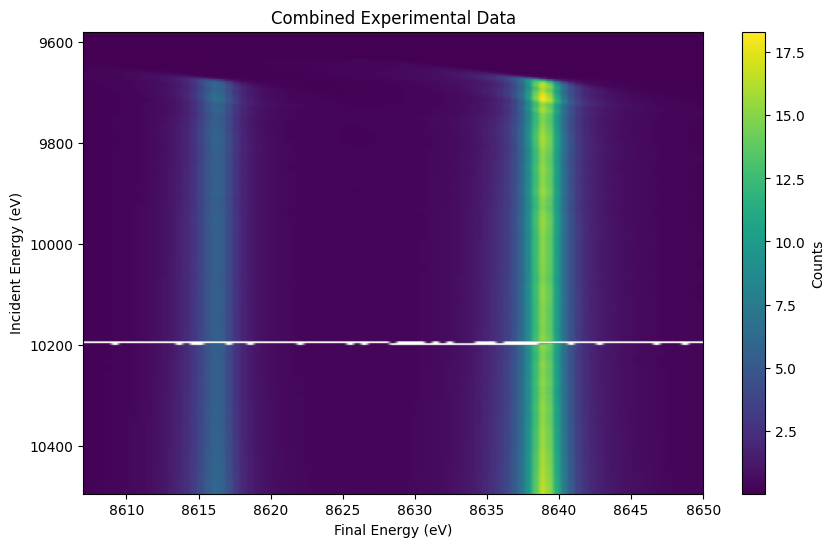

ffcountsnew shape: (2, 7, 245, 87)
Einew shape: (245,)
Efnew shape: (87,)
Ichecknew shape: (245, 87)
Bgnew shape: (2, 245, 87)
Sigma Check: [[3642.475806 3641.009475 3636.140811 ... 3601.384456 3593.210264
  3584.83054 ]
 [3645.741351 3643.641036 3639.337852 ... 3598.75534  3590.699096
  3582.217191]
 [3646.462669 3644.403929 3640.269221 ... 3598.792853 3590.575163
  3582.292562]
 ...
 [3551.408171 3546.974767 3538.399356 ... 3541.214481 3537.083544
  3521.428687]
 [3548.758938 3544.504197 3535.94259  ... 3538.874115 3534.006225
  3522.977434]
 [3545.975183 3541.966968 3533.249213 ... 3536.800814 3532.182045
  3519.995739]]
224
[[array([8615.703466, 8638.964216]), array([3.58664e+14, 7.00733e+14]), array([3.60972e+14, 7.05066e+14]), array([0.222703, 0.432763]), array([0.224136, 0.435438]), ['1', '1'], ['1', '1'], ['1_2', '1_2'], ['1_2', '3_2']], [array([8637.290104, 8637.674673, 8635.86219 , ..., 8635.77198 ,
       8613.998832, 8639.950671], shape=(36,)), array([1.16883e+14, 2.82449e+

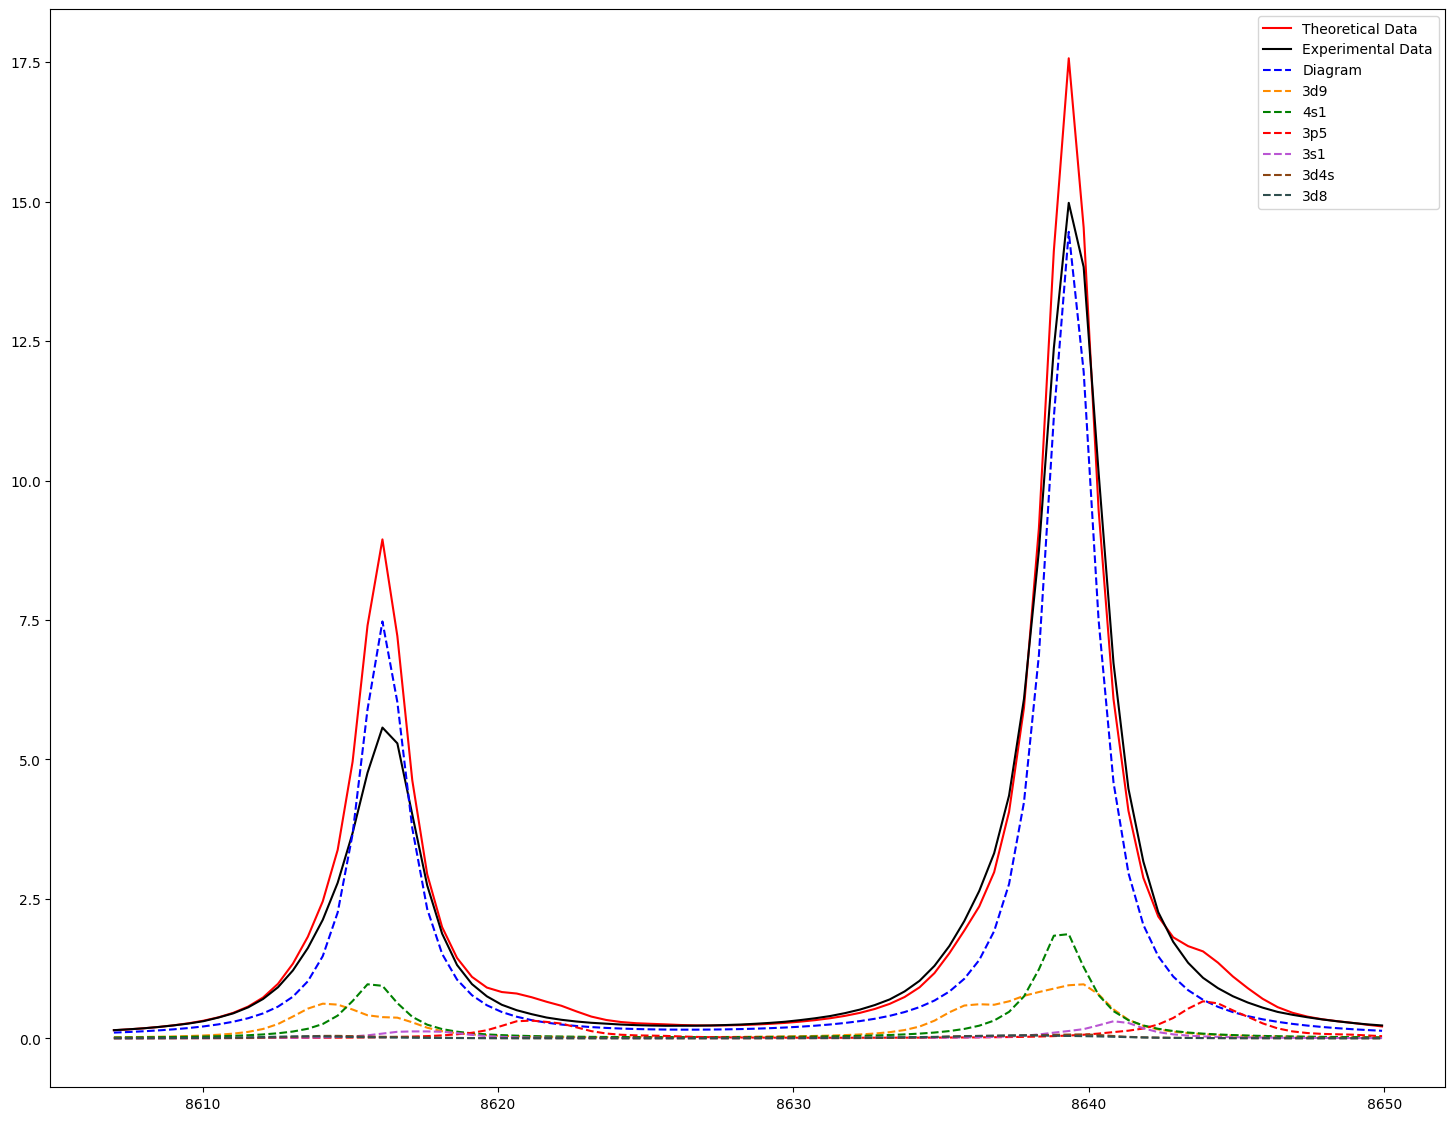

Begining Fitting procedure
Iteration number: 0
average residual: 0.29906632358751306
Max residual: 3.373363027752035
Iteration number: 100
average residual: 0.3080181873875797
Max residual: 2.236279647454202
Iteration number: 200
average residual: 0.27530364091006304
Max residual: 2.2122914431125364
Iteration number: 300
average residual: 0.21315003540994934
Max residual: 1.8158055170925094
Iteration number: 400
average residual: 0.2049814959102733
Max residual: 1.7908981149620553
Iteration number: 500
average residual: 0.20269228237801287
Max residual: 1.775505026426928
Iteration number: 600
average residual: 0.2013895468621318
Max residual: 1.7652949128803241
Iteration number: 700
average residual: 0.20023656229780304
Max residual: 1.755502376124979
Iteration number: 800
average residual: 0.19926418663940415
Max residual: 1.7482089189709322
Iteration number: 900
average residual: 0.1984369478099028
Max residual: 1.7373763874462078
Iteration number: 1000
average residual: 0.1981710092

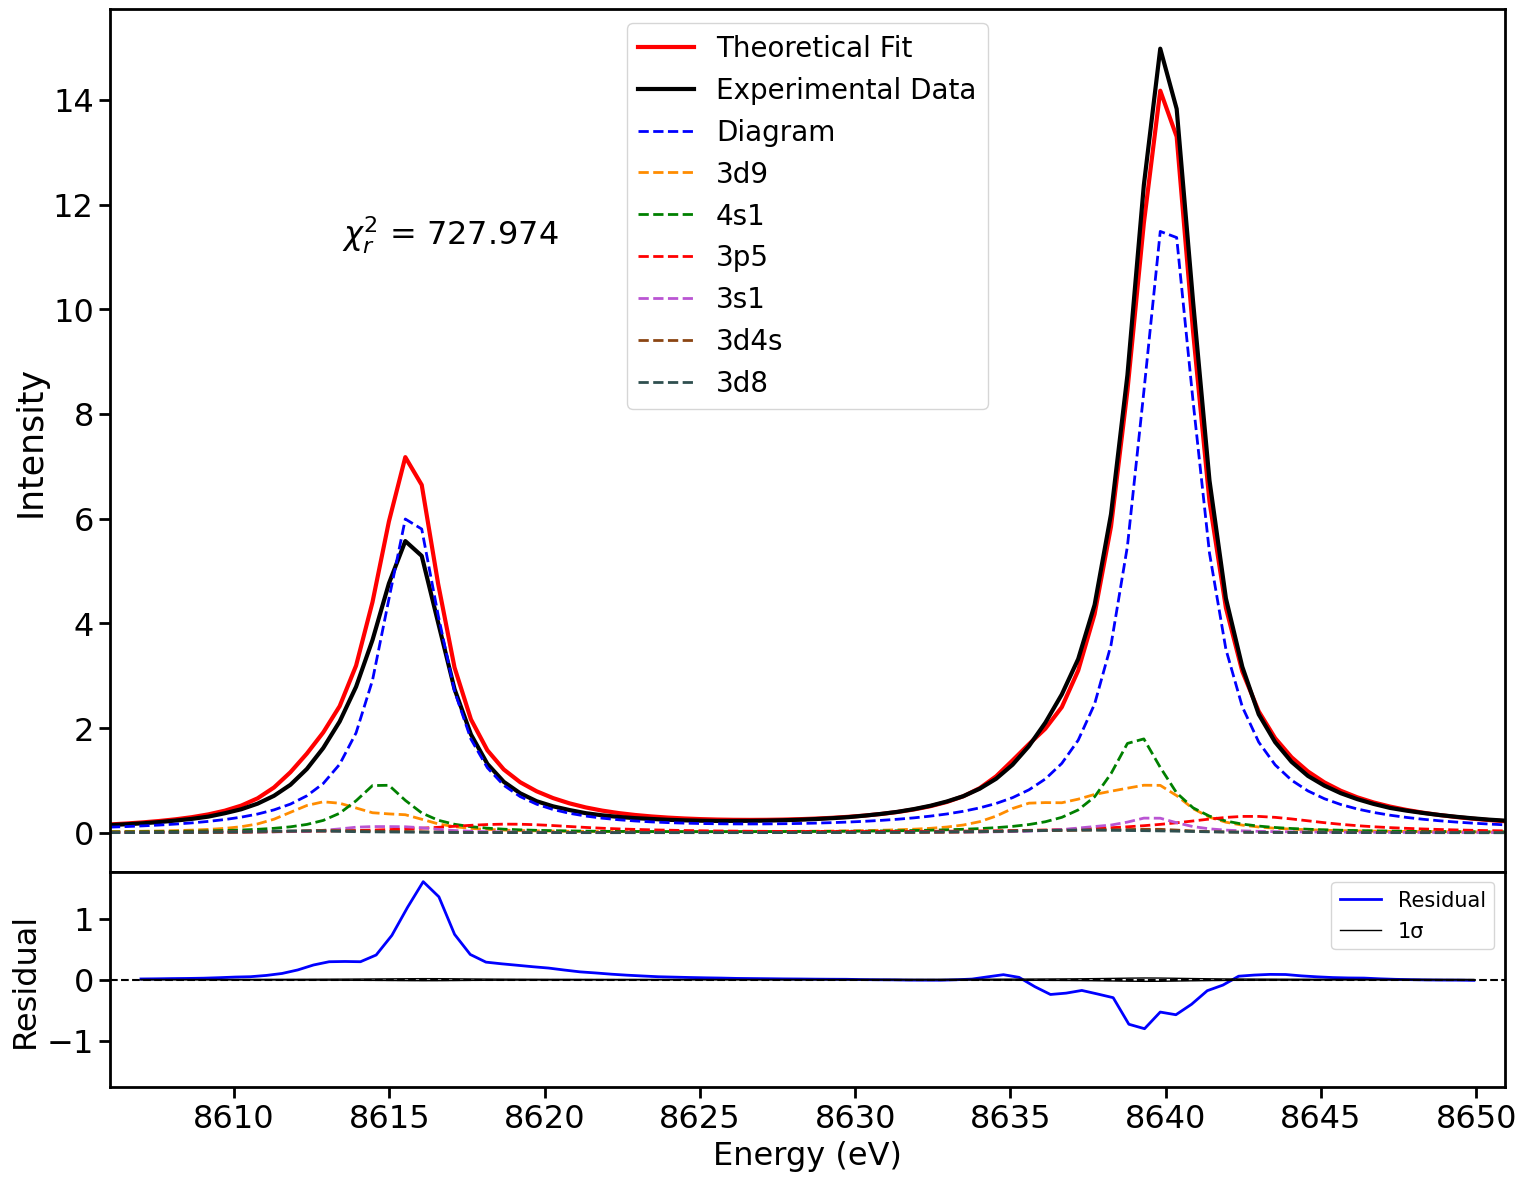

[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 19974
    # data points      = 86
    # variables        = 15
    chi-square         = 10.2753867
    reduced chi-square = 0.14472376
    Akaike info crit   = -152.715248
    Bayesian info crit = -115.900038
##  Warning: uncertainties could not be estimated:
    sat_3d9_fwhm:       at initial value
    sat_3d9_fwhm:       at boundary
    sat_4s1_fwhm:       at initial value
    sat_4s1_fwhm:       at boundary
    sat_3s1_fwhm:       at initial value
    sat_3s1_fwhm:       at boundary
    sat_3d4s_fwhm:      at initial value
    sat_3d4s_fwhm:      at boundary
    sat_3d8_fwhm:       at initial value
    sat_3d8_fwhm:       at boundary
[[Variables]]
    scale:              0.94530986 (init = 1)
    bkg_grad:           0 (fixed)
    bkg_yint:           0 (fixed)
    cshift:             0 (fixed)
    cfwhm:              0 (fixed)
    cfwhm_scale:        0 (fixed)
    fwhm_ka1:           0 (fixed)
    fwhm_ka2:  

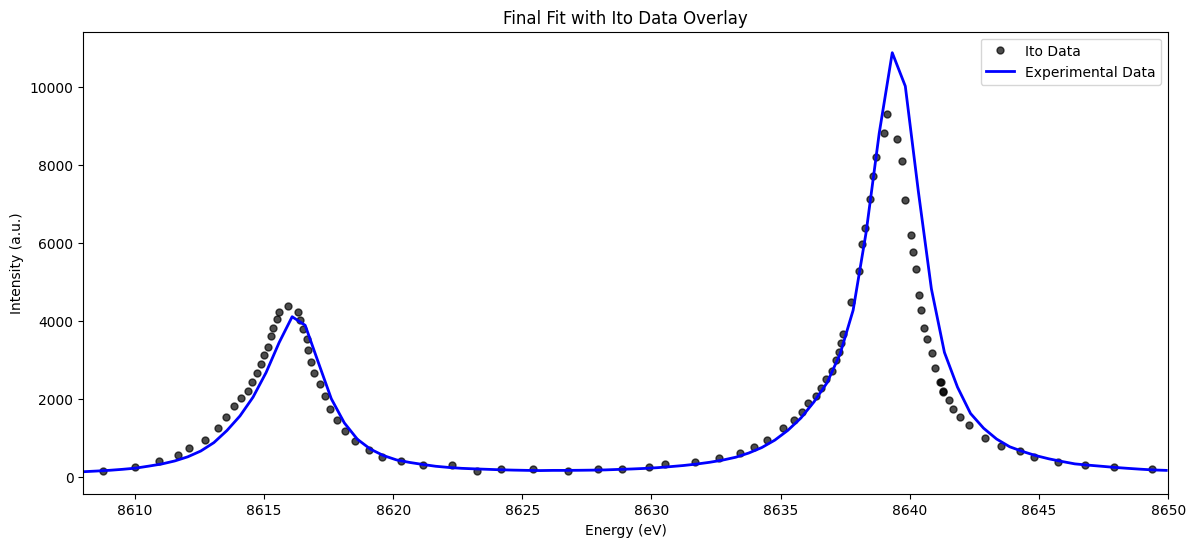

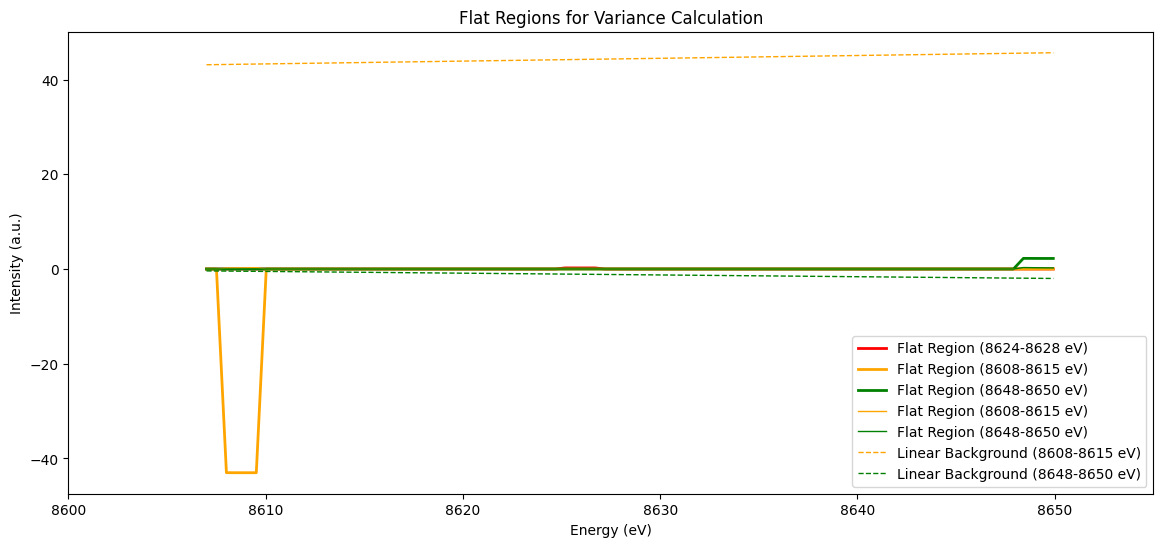

Ei value for reference: 9804.0


In [143]:
#Fits for theory to Zn 2026 HS
#Initialize empty lists for each column
Ito = []

#Import ito data from .txt file separated by break lines, each line is a string
with open('/Users/chantler/DiamondData/ZincIto20240424.txt', 'r') as f:
    for line in f:
        # split() automatically handles spaces or tabs. 
        # Pass a specific character like split(",") if using commas.
        parts = line.split() 
        if len(parts) >= 2:
        # Convert each column to a float and store as a pair
            col1 = float(parts[0])
            col2 = float(parts[1])
            Ito.append([col1, col2])

#add sigmas to ito and fit to ito.

ctpath = "/Users/chantler/DiamondData/TransitionFiles/"
ctFiles = [
    read_ct(ctpath+ "ZnDiagram-A6g.txt"),
    read_ct(ctpath + "Zn3d9-B6s.txt"),
    read_ct(ctpath + "Zn4s1-A6s.txt"),
    read_ct(ctpath + "Zn3p5-B5g.txt"),
    read_ct(ctpath + "Zn3s1-B6g.txt"), 
    read_ct(ctpath + "Zn3d4s-B5s.txt"),
    read_ct(ctpath + "Zn3d8-5p.txt")
    ]

#import experimental data sigmas
with open('/Users/chantler/DiamondData/processed_data/Data_struct', 'rb') as f:
    data_structure = pickle.load(f)
with open('/Users/chantler/DiamondData/processed_data/305229-305232DataStruct.pkl', 'rb') as f:    
#S 305242-305251DataStruct.pkl  HS 305229-305232DataStruct.pkl
    data_structurenew = pickle.load(f)
print('Data structure loaded from pickle files.')
print('Data structure keys:', data_structure.keys())
print('Data structure new keys:', data_structurenew.keys())

#import the sigmas from the data structure
sigmas = data_structure['sigma_I'].T
ffcounts = data_structure['FFcounts'].T
ffcheck = data_structure['FFcounts'].T
Icheck = data_structure['I1'].T
efs = data_structure['Ef'].T
sumdata = data_structure['sum_data'].T

ffcountsnew = data_structurenew['Fi_raw']
Einew = data_structurenew['Ei_union']
Efnew = data_structurenew['Ef_union']
Ichecknew = data_structurenew['I0_raw']
Bgnew = data_structurenew['BG_raw']
comb_datanew = np.zeros((len(Einew),len(Efnew)))
Full_data = np.zeros((len(Einew),len(Efnew)))
Bgtotal = np.zeros((len(Einew),len(Efnew)))


# create a combined data array by summing over the detector and crystal dimensions
for det in range(len(ffcountsnew)):
    for cryst in range(len(ffcountsnew[det])):
        comb_datanew = comb_datanew + ffcountsnew[det,cryst,:,:]
#create a combined background array by summing over the detectors
for det in range(len(Bgnew)):
    Bgtotal = Bgtotal + Bgnew[det,:,:]
    
#create fulldata array by doing ffcountsnew - Bgtotal divided by Ichecknew
Full_data = (comb_datanew - Bgtotal) / Ichecknew
print('comb_datanew shape:', comb_datanew.shape)
print('Bgtotal shape:', Bgtotal.shape)
print('Full_data shape:', Full_data.shape)

plt.figure(figsize=(10, 6))
plt.imshow(Full_data, aspect='auto', extent=[Efnew[0], Efnew[-1], Einew[-1], Einew[0]], cmap='viridis')
plt.colorbar(label='Counts')
plt.xlabel('Final Energy (eV)')
plt.ylabel('Incident Energy (eV)')
plt.title('Combined Experimental Data')
plt.show()
    
print('ffcountsnew shape:', ffcountsnew.shape)
print('Einew shape:', Einew.shape)
print('Efnew shape:', Efnew.shape)
print('Ichecknew shape:', Ichecknew.shape)
print('Bgnew shape:', Bgnew.shape)


slicenum = 120
Efscalenew = Efnew*1.01 + Efnew[0]-(Efnew[0]*1.01)
#read in the relevant csv files for the experimental data to use as a starting point for the optimization. These csv files contain data to fit against.
final_slice = pd.read_csv('/Users/chantler/DiamondData/ZnSigmaDetailed2025HS/scan_140_Ei_10514.900eV.csv').values
#scale the experimental data energy to match the final fit and overlay it
for i in range(len(final_slice)):
    final_slice[i][0] = final_slice[i][0]*1.01 + final_slice[0][0]-(final_slice[0][0]*1.01)
for i in range(len(efs[slicenum,:-1])):
    efs[slicenum,i] = efs[slicenum,i]*1.01 + efs[slicenum,0]-(efs[slicenum,0]*1.01)

#2. Calculate Intensity (I = F/U)
sum_datacheck = ffcheck / Icheck
# 3. Calculate Sigma I using Error Propagation (Poisson Statistics)
# Formula: Sigma_I = I * sqrt( (1/F) + (1/U) )
# Added 1e-10 to denominators to prevent division by zero errors
sigma_check = np.sqrt(8*10**-6 * sumdata + Icheck)
sigma_checknew = np.sqrt(80*comb_datanew[slicenum,:]) 
sigma_checkfnew = np.sqrt(0.00005*Full_data[slicenum,:]) 
print("Sigma Check:", sigma_check)
# ----------------------------------------------------

fslice_parts= (efs[slicenum,:-1], sumdata[slicenum,:-1], sigma_check[slicenum,:-1])
#(final_slice[:, 0], final_slice[:, 1]) #scan_140_Ei_10514.900eV.csv
#bgslice_parts = (Efnew[:-1], Bgnew[0,slicenum,:-1], sigma_checknew[0,:]) #scan_140_Ei_10514.900eV.csv
cdata_parts = (Efscalenew[:-1], comb_datanew[slicenum,:-1], sigma_checknew[:-1]) #scan_140_Ei_10514.900eV.csv
fdata_parts = (Efscalenew[:-1], Full_data[slicenum,:-1], sigma_checkfnew[:-1]) #scan_140_Ei_10514.900eV.csv

data_type = "Zn"
slice_idx = (Ef[:-1], ffcounts[:-1]) #ADD sigmas
print(len(X_trans)-20)

# Sets up common fitting paramters
s_list = ["Diagram", 
          "3d9", 
          "4s1",
          "3p5", 
          "3s1", 
          "3d4s",  
          "3d8"
          ]

s_cols = ["b",
          "darkorange",
          "green",
          "red",
          "mediumorchid",
          "saddlebrown",
          "darkslategrey"
          ]
cparams = [1,0,0,0,0,1,0,0]
cparam_var = [[(0,5),"s"],
              [0,"f"],[0,"f"],[1,"p"],[1,"p"],[1,"p"],[1,"p"],[1,"p"]]

# Sets up satellite paramters (Nguyen probs)
params = [[2, 68.872, 0.4],  # Diagram guess
          [2, 9.085, 0],  # 3d9 guess
          [2, 9.390, 0],  # 4s1 guess
          [2, 4.276, 0],  # 3p5 guess
          [2, 1.686, 0],  # 3s1 guess
          [2, 0.655, 0],  # 3d4s guess
          [2, 0.605, 0]  # 3d8 guess
]
param_var = [[[(2,18),"s"], [0,"f"], [2,"c"]],  # Diagram Bounds
             [[(2,18),"s"], [(0),"f"], [3,"c"]],  # 3d9 Bounds
             [[(2,18),"s"], [(0),"f"], [2,"c"]],  # 4s1 Bounds
             [[(2,18),"s"], [(0),"f"], [2,"c"]],  # 3p5 Bounds
             [[(2,18),"s"], [(0),"f"], [2,"c"]],  # 3s1 Bounds
             [[(2,18),"s"], [(0),"f"], [3,"c"]],  # 3d4s Bounds
             [[(2,18),"s"], [(0),"f"], [3,"c"]]  # 3d8 Bounds
            ]

ffout = fitting_function(ctFiles, fdata_parts, cparams, params, cparam_var, param_var, sat_list=s_list, sat_cols = s_cols, 
                 width = "sat", fwhm_scale = "unscaled", fig_title=data_type + "_D_4s_3d_3p_3s_3d4s_3d3d",
                 spec_sat=True, directory = ctpath + 'paper_fits/', 
                 save_plot = True, plot_sats = True, 
                 fontsize = 25, fig_size = [18,14],
                 n_sigma = 1, x_scale = 1, return_output=True, dont_fit=False
                 )
ofits = ffout[2] 

plt.figure(figsize=(14, 6))
for i in range(len(Ito)):
    plt.plot(Ito[i][0], Ito[i][1]*1.2, color='black', label='Ito Data' if i == 0 else "", marker='o', markersize=5, linestyle='None', alpha=0.7)
#find the variance from 8623- 8628 eV in the experimental data.
flatsmid = np.zeros(len(fdata_parts[0]))
flatslow = np.zeros(len(fdata_parts[0]))
flatshigh = np.zeros(len(fdata_parts[0]))
flatslowdt = np.zeros(len(fdata_parts[0]))
flatshighdt = np.zeros(len(fdata_parts[0]))

lowmin = 8608
lowmax = 8610
midmin = 8625
midmax = 8627
highmin = 8648
highmax = 8650

#populate the flat regions of the experimental data for variance calculation and minus a linear background based on the start and end points of the flat region.
for i in range(len(fdata_parts[0])):
    if fdata_parts[0][i] >= midmin and fdata_parts[0][i] <= midmax:
        flatsmid[i] = fdata_parts[1][i] 
    #add additional flat regions for variance calculation and minus a linear background based on the start and end points of the flat region.
    if fdata_parts[0][i] >= lowmin and fdata_parts[0][i] < lowmax:
        minvallow = fdata_parts[1][0]
        flatslow[i] = fdata_parts[1][i]
        if fdata_parts[1][i] <lowmax:
            maxvallow = fdata_parts[1][i]
    if fdata_parts[0][i] > highmin and fdata_parts[0][i] <= highmax:
        flatshigh[i] = fdata_parts[1][i]
        maxvalhigh = np.max(flatshigh[flatshigh > 0])
        minvalhigh = np.min(flatshigh[flatshigh > 0])

#find the linear gradient of the flat regions to remove any linear background from the flat regions.
flgrad = (maxvallow - minvallow) / (lowmax - lowmin)
fhgrad =  (minvalhigh - maxvalhigh) / (highmax - highmin)
flatslow_lin = fdata_parts[0] * flgrad  -466
flatshigh_lin = fdata_parts[0] * fhgrad +320
#add a linear trend to flatten flatslow and flatshigh to remove any linear background from the flat regions.
for i in range(len(flatslow)):
    if flatslow[i] > 0:
        flatslowdt[i] = flatslow[i] - flatslow_lin[i]
for i in range(len(flatshigh)):
    if flatshigh[i] > 0:
        flatshighdt[i] = flatshigh[i] - flatshigh_lin[i]
        

#flatslow[flatslow > 0] = flatslow[flatslow > 0] - fllin * flgrad
#flatshigh[flatshigh > 0] = flatshigh[flatshigh > 0] - fhlin * fhgrad
#find the variance of the flat region
#variance_flat = np.var(flats[flats > 0])  # Only consider non-zero values for variance calculation
#print("Variance of new flat region (8623-8628 eV):", variance_flat)
#print("Standard Deviation of new flat region (8623-8628 eV):", np.sqrt(variance_flat))
#variance_sigma = np.mean(sigma_check)
#print("Variance of sigma_check:", variance_sigma*variance_sigma)
#print("Standard Deviation of sigma_check:",variance_sigma)
#find the variance from 8623- 8628 eV in the experimental data.
#flats = np.zeros(len(fslice_parts[0]))
#for i in range(len(fslice_parts[0])):
#    if fslice_parts[0][i] >= 8624 and fslice_parts[0][i] <= 8628:
#        flats[i] = fslice_parts[1][i] 
#find the variance of the flat region
variance_midflat = np.var(flatsmid[flatsmid > 0])  # Only consider non-zero values for variance calculation
variance_highflat = np.var(flatshighdt[flatshigh > 0])  # Only consider non-zero values for variance calculation
variance_lowflat = np.var(flatslowdt[flatslow > 0])  # Only consider non-zero values for variance calculation

print(len(flatslow[flatslow > 0]), len(flatsmid[flatsmid > 0]), len(flatshigh[flatshigh > 0]))
print("Variance of low flat region (8608-8613 eV):", variance_lowflat)
print("Standard Deviation of low flat region (8608-8613 eV):", np.sqrt(variance_lowflat))
print("Variance of middle flat region (8623-8628 eV):", variance_midflat)
print("Standard Deviation of middle flat region (8623-8628 eV):", np.sqrt(variance_midflat))
print("Variance of high flat region (8648-8650 eV):", variance_highflat)
print("Standard Deviation of high flat region (8648-8650 eV):", np.sqrt(variance_highflat))
variance_sigma = np.mean(sigma_checkfnew)
print("Variance of sigma_checkfnew:", variance_sigma*variance_sigma)
print("Standard Deviation of sigma_checkfnew:",variance_sigma)
print(ofits)

#var_all = np.var(bgslice_parts[1])
#print("Variance of all background data:", var_all)
#print("Standard Deviation of all background data:", np.sqrt(var_all))
#scale the experimental data to match the final fit and overlay it
plt.plot(cdata_parts[0], cdata_parts[1]/(1276.390*1.4), color='blue', label='Experimental Data', linewidth=2)
plt.legend()
plt.title('Final Fit with Ito Data Overlay')
plt.xlabel('Energy (eV)')
plt.ylabel('Intensity (a.u.)')
plt.xlim(8608, 8650)
plt.show()

#plot the flat regions and the variance of the flat regions
plt.figure(figsize=(14, 6))
plt.plot(fdata_parts[0], flatsmid, color='red', label='Flat Region (8624-8628 eV)', linewidth=2)
plt.plot(fdata_parts[0], flatslowdt, color='orange', label='Flat Region (8608-8615 eV)', linewidth=2)
plt.plot(fdata_parts[0], flatshighdt, color='green', label='Flat Region (8648-8650 eV)', linewidth=2)
plt.plot(fdata_parts[0], flatslow, color='orange', label='Flat Region (8608-8615 eV)', linewidth=1)
plt.plot(fdata_parts[0], flatshigh, color='green', label='Flat Region (8648-8650 eV)', linewidth=1)
#plot the linear background of the flat regions

plt.plot(fdata_parts[0], flatslow_lin, color='orange', linestyle='--', label='Linear Background (8608-8615 eV)', linewidth=1)
plt.plot(fdata_parts[0], flatshigh_lin, color='green', linestyle='--', label='Linear Background (8648-8650 eV)', linewidth=1)

plt.legend()
plt.title('Flat Regions for Variance Calculation')
plt.xlabel('Energy (eV)')
plt.ylabel('Intensity (a.u.)')
plt.xlim(8600, 8655)
plt.show()

#print the Ei value for reference
print("Ei value for reference:", Einew[slicenum])
#fitting_csv(fig_title, directory, params, opt_params, cparam_names, sat_param_names, sat_list, width, norm_area, norm_opt_area, chisq, fwhm_scale):    
#fitting_function(all_sat[0:7], data, cparams, params[0:7], cparam_var, param_var[0:7], sat_cols= cols,spec_sat = True, sat_list = sat_list[0:7], plot_init = False, fwhm_scale = "unscaled", ka_dict = ka_dict, fig_title=data_type + "_D_4s_3d_3p_3s_3d4s_3d3d", directory = fit_path + data_type + '/paper_fits/', width='ka1ka2')

Data structure loaded from pickle file.
Data structure keys: dict_keys(['all_data', 'crystal_data', 'sum_data', 'sigma_I', 'Ei', 'Ef', 'I1', 'FFcounts'])
Data structure types: {'all_data': <class 'numpy.ndarray'>, 'crystal_data': <class 'numpy.ndarray'>, 'sum_data': <class 'numpy.ndarray'>, 'sigma_I': <class 'numpy.ndarray'>, 'Ei': <class 'numpy.ndarray'>, 'Ef': <class 'numpy.ndarray'>, 'I1': <class 'numpy.ndarray'>, 'FFcounts': <class 'numpy.ndarray'>}
[[   579    584    574 ...    475    495    445]
 [   538    551    615 ...    495    464    470]
 [   534    551    591 ...    490    453    479]
 ...
 [176789 197328 222273 ... 306910 279963 253365]
 [177388 197824 223193 ... 306550 279266 254095]
 [176832 198178 223154 ... 307052 279615 253546]]
(244, 87)
Sigma Check: [[72849.516127 72820.189508 72722.816227 ... 72027.68912  71864.205276
  71696.610799]
 [72914.827024 72872.820722 72786.757037 ... 71975.106808 71813.981926
  71644.34381 ]
 [72929.25339  72888.078586 72805.384416 ... 

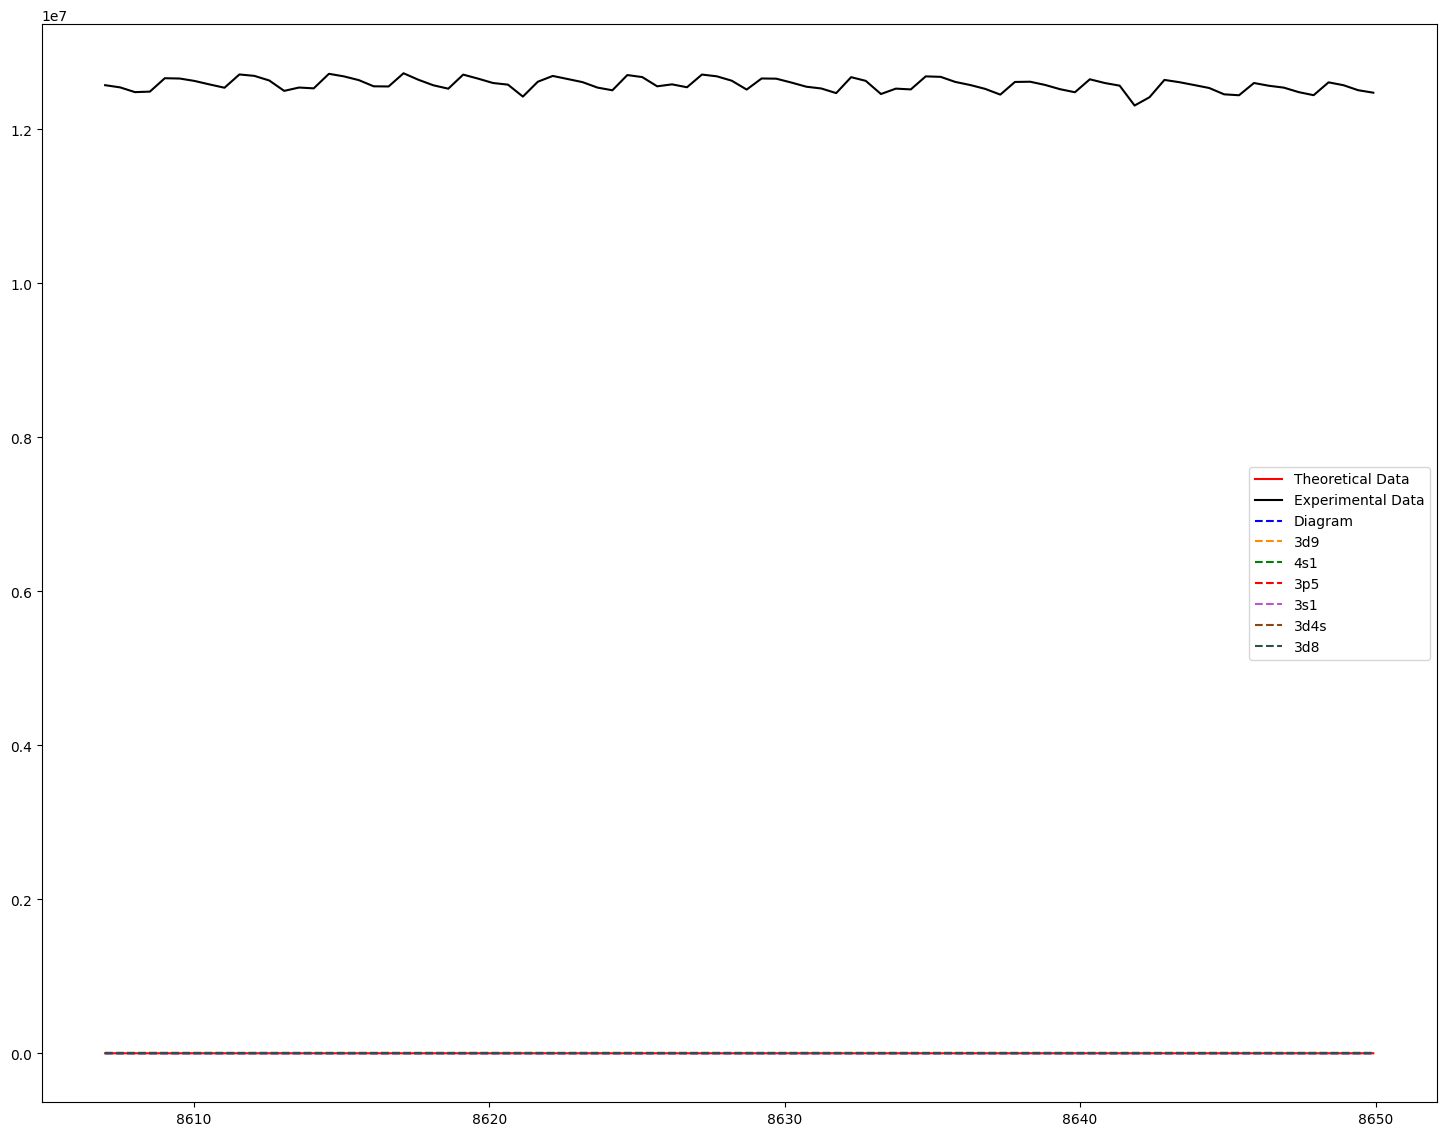

Begining Fitting procedure
Iteration number: 0
average residual: 12580782.328756714
Max residual: 12728617.686389158
Iteration number: 100
average residual: 12580764.97655444
Max residual: 12728599.149128135
Fitting procedure complete


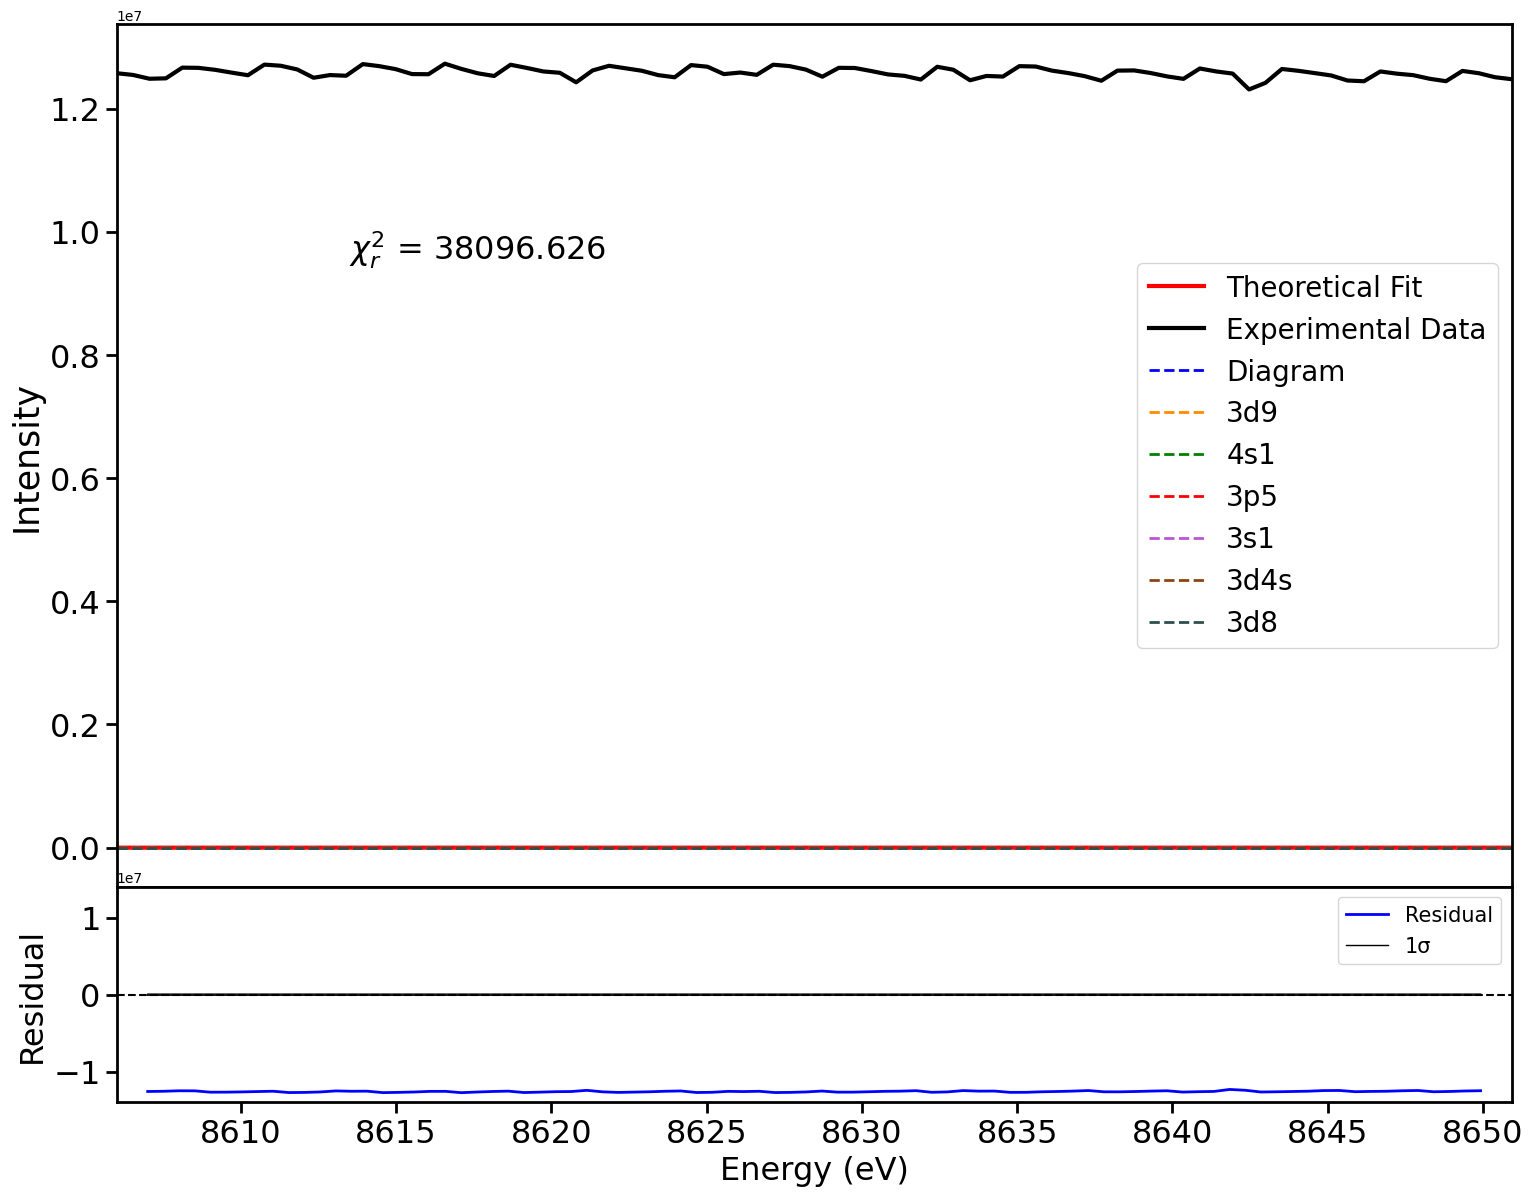

[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 121
    # data points      = 86
    # variables        = 15
    chi-square         = 1.3612e+16
    reduced chi-square = 1.9172e+14
    Akaike info crit   = 2841.80466
    Bayesian info crit = 2878.61987
[[Variables]]
    scale:              9.99959218 +/- 1304889.50 (13049427.17%) (init = 0.5)
    bkg_grad:           0 (fixed)
    bkg_yint:           0 (fixed)
    cshift:             0 (fixed)
    cfwhm:              0 (fixed)
    cfwhm_scale:        0 (fixed)
    fwhm_ka1:           0 (fixed)
    fwhm_ka2:           0 (fixed)
    sat_Diagram_fwhm:   8.73270864 +/- 9.3337e+09 (106881742265.94%) (init = 2)
    sat_Diagram_area:   68.872 (fixed)
    sat_Diagram_shift: -0.68179766 +/- 34160487.8 (5010355714.29%) (init = 0.4)
    sat_3d9_fwhm:       2.07909901 +/- 1.2525e+09 (60241287822.01%) (init = 2)
    sat_3d9_area:       9.085 (fixed)
    sat_3d9_shift:     -0.16562457 +/- 6953714.58 (4198480101.88%) (init 

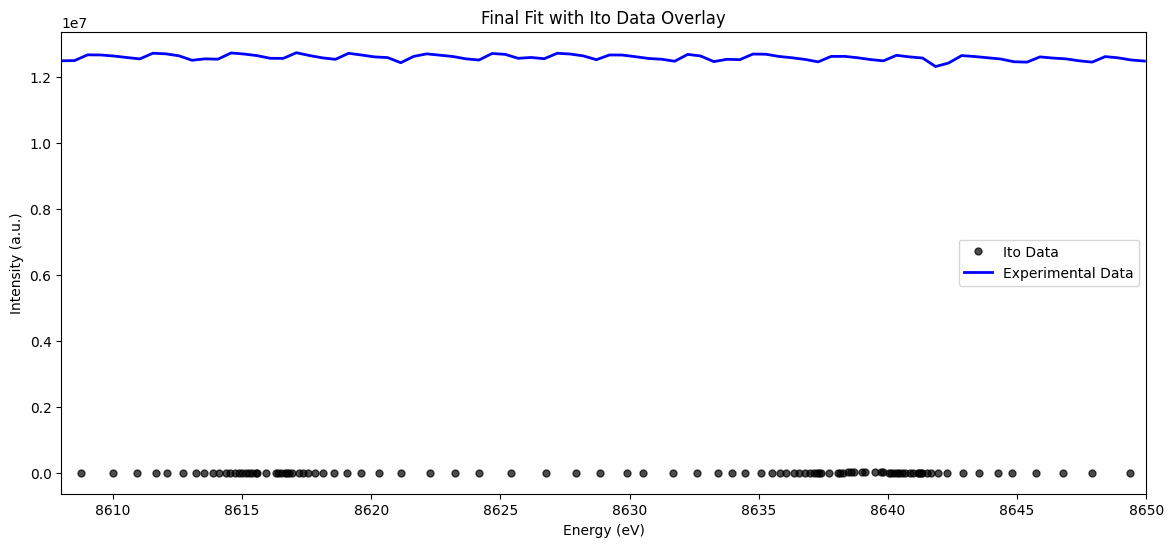

In [ ]:
#Fits for theory to I0 2026 HS
#Initialize empty lists for each column
Ito = []

#Import ito data from .txt file separated by break lines, each line is a string
with open('/Users/chantler/DiamondData/ZincIto20240424.txt', 'r') as f:
    for line in f:
        # split() automatically handles spaces or tabs. 
        # Pass a specific character like split(",") if using commas.
        parts = line.split() 
        if len(parts) >= 2:
        # Convert each column to a float and store as a pair
            col1 = float(parts[0])
            col2 = float(parts[1])
            Ito.append([col1, col2])

#add sigmas to ito and fit to ito.

ctpath = "/Users/chantler/DiamondData/TransitionFiles/"
ctFiles = [
    read_ct(ctpath+ "ZnDiagram-A6g.txt"),
    read_ct(ctpath + "Zn3d9-B6s.txt"),
    read_ct(ctpath + "Zn4s1-A6s.txt"),
    read_ct(ctpath + "Zn3p5-B5g.txt"),
    read_ct(ctpath + "Zn3s1-B6g.txt"), 
    read_ct(ctpath + "Zn3d4s-B5s.txt"),
    read_ct(ctpath + "Zn3d8-5p.txt")
    ]

#import experimental data sigmas
with open('/Users/chantler/DiamondData/processed_data/Data_struct', 'rb') as f:
    data_structure = pickle.load(f)
print('Data structure loaded from pickle file.')
print('Data structure keys:', data_structure.keys())
print('Data structure types:', {k: type(v) for k, v in data_structure.items()})
#import the sigmas from the data structure
sigmas = data_structure['sigma_I'].T
ffcounts = data_structure['FFcounts'].T
ffcheck = data_structure['FFcounts'].T
Icheck = data_structure['I1'].T
efs = data_structure['Ef'].T
sumdata = data_structure['sum_data'].T
print(ffcounts)
print(Icheck.shape)
slicenum = len(efs)-1
#read in the relevant csv files for the experimental data to use as a starting point for the optimization. These csv files contain data to fit against.
final_slice = pd.read_csv('/Users/chantler/DiamondData/ZnSigmaDetailed2025HS/scan_140_Ei_10514.900eV.csv').values
#scale the experimental data energy to match the final fit and overlay it
for i in range(len(final_slice)):
    final_slice[i][0] = final_slice[i][0]*1.01 + final_slice[0][0]-(final_slice[0][0]*1.01)
for i in range(len(efs[slicenum,:-1])):
    efs[slicenum,i] = efs[slicenum,i]*1.01 + efs[slicenum,0]-(efs[slicenum,0]*1.01)

#2. Calculate Intensity (I = F/U)
sum_datacheck = ffcheck / Icheck
# 3. Calculate Sigma I using Error Propagation (Poisson Statistics)
# Formula: Sigma_I = I * sqrt( (1/F) + (1/U) )
# Added 1e-10 to denominators to prevent division by zero errors
sigma_check = np.sqrt(400*Icheck)
print("Sigma Check:", sigma_check)
# ----------------------------------------------------

fslice_parts= (efs[slicenum,:-1], Icheck[slicenum,:-1], sigma_check[slicenum,:-1])
#(final_slice[:, 0], final_slice[:, 1]) #scan_140_Ei_10514.900eV.csv

data_type = "Zn"
slice_idx = (Ef[:-1], ffcounts[:-1]) #ADD sigmas
print(len(X_trans)-20)

# Sets up common fitting paramters
s_list = ["Diagram", 
          "3d9", 
          "4s1",
          "3p5", 
          "3s1", 
          "3d4s",  
          "3d8"
          ]

s_cols = ["b",
          "darkorange",
          "green",
          "red",
          "mediumorchid",
          "saddlebrown",
          "darkslategrey"
          ]
cparams = [0.5,0,0,0,0,1,0,0]
cparam_var = [[(0,10),"s"],
              [0,"f"],[0,"f"],[1,"p"],[1,"p"],[1,"p"],[1,"p"],[1,"p"]]

# Sets up satellite paramters (Nguyen probs)
params = [[2, 68.872, 0.4],  # Diagram guess
          [2, 9.085, 0],  # 3d9 guess
          [2, 9.390, 0],  # 4s1 guess
          [2, 4.276, 0],  # 3p5 guess
          [2, 1.686, 0],  # 3s1 guess
          [2, 0.655, 0],  # 3d4s guess
          [2, 0.605, 0]  # 3d8 guess
]
param_var = [[[(2,18),"s"], [0,"f"], [2,"c"]],  # Diagram Bounds
             [[(2,18),"s"], [(0),"f"], [3,"c"]],  # 3d9 Bounds
             [[(2,18),"s"], [(0),"f"], [2,"c"]],  # 4s1 Bounds
             [[(2,18),"s"], [(0),"f"], [2,"c"]],  # 3p5 Bounds
             [[(2,18),"s"], [(0),"f"], [2,"c"]],  # 3s1 Bounds
             [[(2,18),"s"], [(0),"f"], [2,"c"]],  # 3d4s Bounds
             [[(2,18),"s"], [(0),"f"], [2,"c"]]  # 3d8 Bounds
            ]

ffout = fitting_function(ctFiles, fslice_parts, cparams, params, cparam_var, param_var, sat_list=s_list, sat_cols = s_cols, 
                 width = "sat", fwhm_scale = "unscaled", fig_title=data_type + "_D_4s_3d_3p_3s_3d4s_3d3d",
                 spec_sat=True, directory = ctpath + 'paper_fits/', 
                 save_plot = True, plot_sats = True, 
                 fontsize = 25, fig_size = [18,14], 
                 n_sigma = 1, x_scale = 1, return_output=True, dont_fit=False
                 )
ofits = ffout[2] 

plt.figure(figsize=(14, 6))
for i in range(len(Ito)):
    plt.plot(Ito[i][0], Ito[i][1]*1.2, color='black', label='Ito Data' if i == 0 else "", marker='o', markersize=5, linestyle='None', alpha=0.7)

#find the variance from 8623- 8628 eV in the experimental data.
flats = np.zeros(len(cdata_parts[0]))
for i in range(len(cdata_parts[0])):
    if cdata_parts[0][i] >= 8624 and cdata_parts[0][i] <= 8628:
        flats[i] = cdata_parts[1][i] 
#find the variance of the flat region
variance_flat = np.var(flats[flats > 0])  # Only consider non-zero values for variance calculation
print("Variance of new flat region (8623-8628 eV):", variance_flat)
print("Standard Deviation of new flat region (8623-8628 eV):", np.sqrt(variance_flat))
variance_sigma = np.mean(sigma_check)
print("Variance of sigma_check:", variance_sigma*variance_sigma)
print("Standard Deviation of sigma_check:",variance_sigma)
print(ofits)
#scale the experimental data to match the final fit and overlay it
plt.plot(fslice_parts[0], fslice_parts[1], color='blue', label='Experimental Data', linewidth=2)
plt.legend()
plt.title('Final Fit with Ito Data Overlay')
plt.xlabel('Energy (eV)')
plt.ylabel('Intensity (a.u.)')
plt.xlim(8608, 8650)
plt.show()


Data structure loaded from pickle file.
Data structure new keys: dict_keys(['Ei_union', 'Ef_union', 'Fi_raw', 'BG_raw', 'I0_raw', 'Coverage', 'i0_outlier_mask'])
Data structure keys: dict_keys(['all_data', 'crystal_data', 'sum_data', 'sigma_I', 'Ei', 'Ef', 'I1', 'FFcounts'])
comb_datanew shape: (245, 87)
Bgtotal shape: (245, 87)
Full_data shape: (245, 87)
(244, 87)
(244, 87)
[ 9579.999  9585.     9590.    ... 10468.582 10481.38  10494.308]
(244, 87)
Slice Energy Values: 8617.099999999999
(244,) (244,)
[    516     560     570 ... 4541050 4551530 4565594]
Variance of flat region (10400-10500 eV): 25655729.459533602
Standard Deviation of flat region (10400-10500 eV): 5065.148513077736


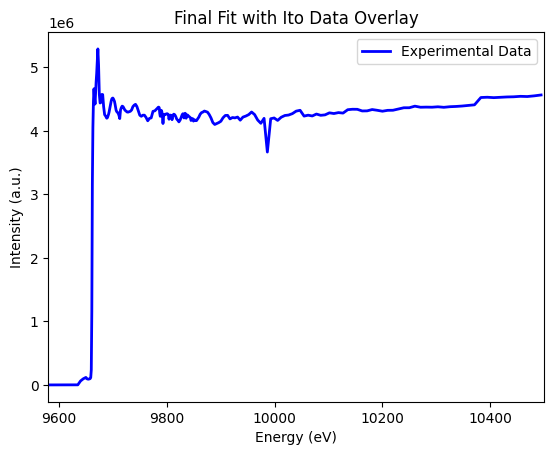

8 8 8
Variance of low flat region (8608-8613 eV): 1.5659477634280685e-07
Standard Deviation of low flat region (8608-8613 eV): 0.00039572057861931675
Variance of middle flat region (8623-8628 eV): 0.000127735855885131
Standard Deviation of middle flat region (8623-8628 eV): 0.011302028839333714
Variance of high flat region (8648-8650 eV): 2.8752630556090362e-05
Standard Deviation of high flat region (8648-8650 eV): 0.005362147942391217
Variance of flat region for scaled (10400-10500 eV): 5.048133941214997e-07
Standard Deviation of flat region for scaled (10400-10500 eV): 0.0007105022126084476


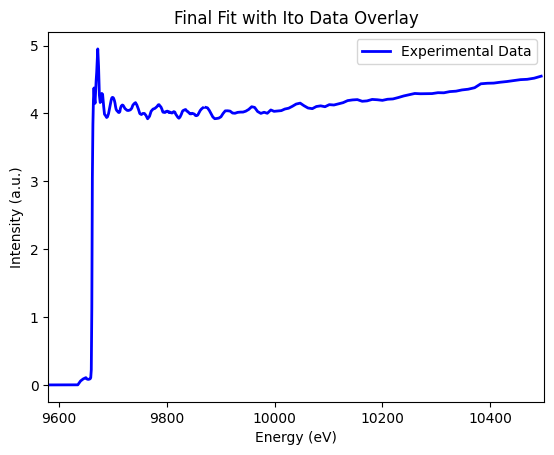

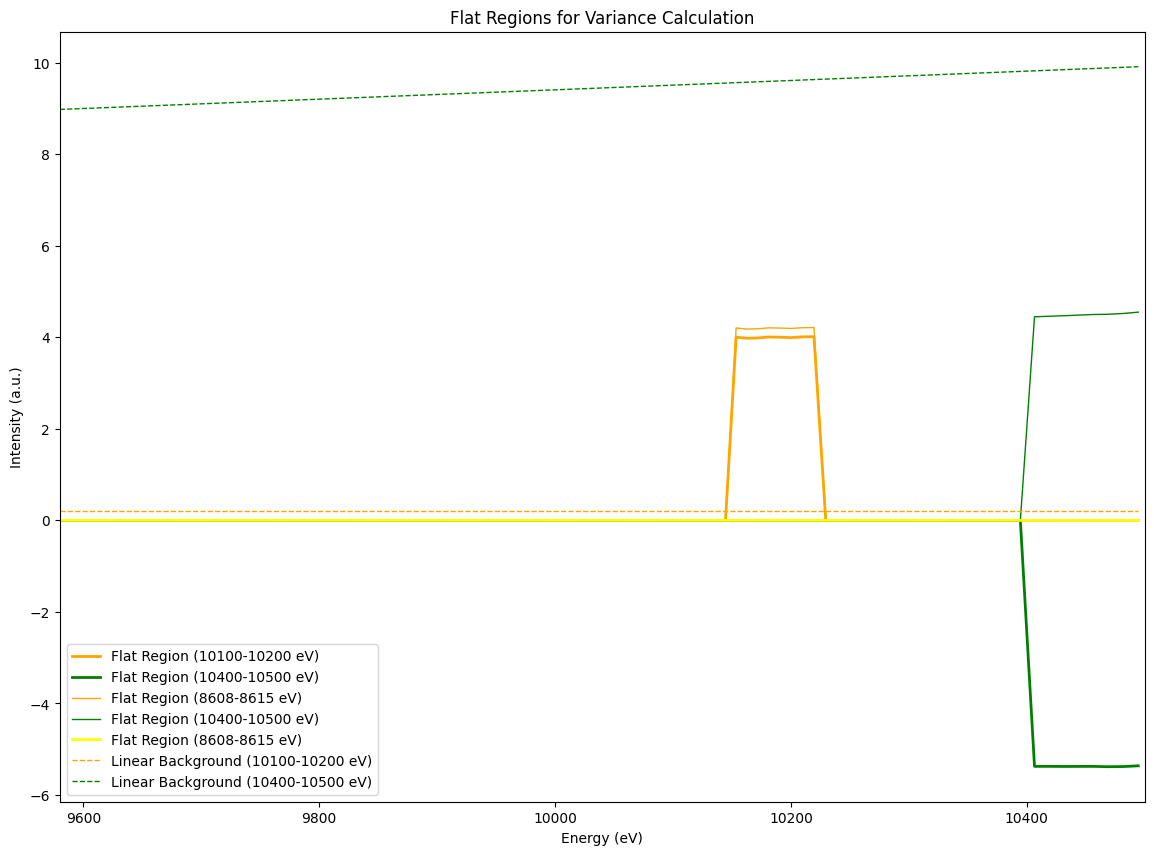

In [137]:
#Fits for theory to XAS 2026 HS

#Initialize empty lists for each column
Ito = []

#Import ito data from .txt file separated by break lines, each line is a string
with open('/Users/chantler/DiamondData/ZincIto20240424.txt', 'r') as f:
    for line in f:
        # split() automatically handles spaces or tabs. 
        # Pass a specific character like split(",") if using commas.
        parts = line.split() 
        if len(parts) >= 2:
        # Convert each column to a float and store as a pair
            col1 = float(parts[0])
            col2 = float(parts[1])
            Ito.append([col1, col2])

#add sigmas to ito and fit to ito.

ctpath = "/Users/chantler/DiamondData/TransitionFiles/"
ctFiles = [
    read_ct(ctpath+ "ZnDiagram-A6g.txt"),
    read_ct(ctpath + "Zn3d9-B6s.txt"),
    read_ct(ctpath + "Zn4s1-A6s.txt"),
    read_ct(ctpath + "Zn3p5-B5g.txt"),
    read_ct(ctpath + "Zn3s1-B6g.txt"), 
    read_ct(ctpath + "Zn3d4s-B5s.txt"),
    read_ct(ctpath + "Zn3d8-5p.txt")
    ]

#import experimental data sigmas
with open('/Users/chantler/DiamondData/processed_data/Data_struct', 'rb') as f:
    data_structure = pickle.load(f)

with open('/Users/chantler/DiamondData/processed_data/305229-305232DataStruct.pkl', 'rb') as f:    
#S 305242-305251DataStruct.pkl  HS 305229-305232DataStruct.pkl
    data_structurenew = pickle.load(f)
print('Data structure loaded from pickle file.')
print('Data structure new keys:', data_structurenew.keys())
print('Data structure keys:', data_structure.keys())

#import the sigmas from the data structure
sigmas = data_structure['sigma_I'].T
ffcounts = data_structure['FFcounts'].T
ffcheck = data_structure['FFcounts'].T
Icheck = data_structure['I1'].T
efs = data_structure['Ef'].T
eis = data_structure['Ei'].T

ffcountsnew = data_structurenew['Fi_raw']
Einew = data_structurenew['Ei_union']
Efnew = data_structurenew['Ef_union']
Ichecknew = data_structurenew['I0_raw']
Bgnew = data_structurenew['BG_raw']
comb_datanew = np.zeros((len(Einew),len(Efnew)))
Full_data = np.zeros((len(Einew),len(Efnew)))
Bgtotal = np.zeros((len(Einew),len(Efnew)))
# create a combined data array by summing over the detector and crystal dimensions
for det in range(len(ffcountsnew)):
    for cryst in range(len(ffcountsnew[det])):
        comb_datanew = comb_datanew + ffcountsnew[det,cryst,:,:]
#create a combined background array by summing over the detectors
for det in range(len(Bgnew)):
    Bgtotal = Bgtotal + Bgnew[det,:,:]

Full_data = (comb_datanew - Bgtotal) / Ichecknew


print('comb_datanew shape:', comb_datanew.shape)
print('Bgtotal shape:', Bgtotal.shape)
print('Full_data shape:', Full_data.shape)
sumdata = data_structure['sum_data'].T
print(ffcounts.shape)
print(eis.shape)
print(eis[:,0])
print(Icheck.shape)
slicenum = 20

#2. Calculate Intensity (I = F/U)
sum_datacheck = ffcheck / Icheck
# 3. Calculate Sigma I using Error Propagation (Poisson Statistics)
# Formula: Sigma_I = I * sqrt( (1/F) + (1/U) )
# Added 1e-10 to denominators to prevent division by zero errors
sigma_check = np.sqrt(400*Icheck)

#define the flat regions for variance calculation
flatsmid = np.zeros(len(fdata_parts[0]))
flatslow = np.zeros(len(fdata_parts[0]))
flatshigh = np.zeros(len(fdata_parts[0]))
flatslowdt = np.zeros(len(fdata_parts[0]))
flatshighdt = np.zeros(len(fdata_parts[0]))

lowmin = 9598
lowmax = 9635
midmin = 10150
midmax = 10220
highmin = 10400
highmax = 10500

# ----------------------------------------------------
fdata_parts = (Einew, Full_data[:,slicenum]) #scan_140_Ei_10514.900eV.csv

fslice_parts= (eis[:,slicenum], FFcounts[slicenum,:])
fslicei0_parts = (eis[:,slicenum], FFcounts[slicenum,:]/Icheck[:,slicenum])
#print the slice energy and intensity values for the experimental data
print("Slice Energy Values:", Efscalenew[slicenum])
print(fslice_parts[0].shape, fslice_parts[1].shape)
#(final_slice[:, 0], final_slice[:, 1]) #scan_140_Ei_10514.900eV.csv
print(fslice_parts[1])
#find the variance from 10400-10500 eV in the experimental data.



flatslow = np.zeros(len(fdata_parts[0]))
flatsmid = np.zeros(len(fdata_parts[0]))
flatshigh = np.zeros(len(fdata_parts[0]))
flatshighdt = np.zeros(len(fdata_parts[0]))
flatsmiddt = np.zeros(len(fdata_parts[0]))


#populate the flat regions of the experimental data for variance calculation and minus a linear background based on the start and end points of the flat region.
for i in range(len(fdata_parts[0])):
    if fdata_parts[0][i] >= lowmin and fdata_parts[0][i] <= lowmax:
        flatslow[i] = fdata_parts[1][i] 
    #add additional flat regions for variance calculation and minus a linear background based on the start and end points of the flat region.
    if fdata_parts[0][i] >= midmin and fdata_parts[0][i] < midmax:
        flatsmid[i] = fdata_parts[1][i]
    if fdata_parts[0][i] > highmin and fdata_parts[0][i] <= highmax:
        flatshigh[i] = fdata_parts[1][i]

maxvalmid = np.max(flatsmid[flatshigh > 0])
minvalmid = np.min(flatsmid[flatshigh > 0])
maxvalhigh = np.max(flatshigh[flatshigh > 0])
minvalhigh = np.min(flatshigh[flatshigh > 0])
#find the linear gradient of the flat regions to remove any linear background from the flat regions.
fmgrad = (maxvalmid - minvalmid) / (midmax - midmin)
fhgrad =  (maxvalhigh - minvalhigh) / (highmax - highmin)
flatsmid_lin = fdata_parts[0] * fmgrad +0.2
flatshigh_lin = fdata_parts[0] * fhgrad -0.8

#add a linear trend to flatten flatslow and flatshigh to remove any linear background from the flat regions.
for i in range(len(flatslow)):
    if flatsmid[i] > 0:
        flatsmiddt[i] = flatsmid[i] - flatsmid_lin[i]
for i in range(len(flatshigh)):
    if flatshigh[i] > 0:
        flatshighdt[i] = flatshigh[i] - flatshigh_lin[i]


variance_flat = np.var(flats[flats > 0])  # Only consider non-zero values for variance calculation
print("Variance of flat region (10400-10500 eV):", variance_flat)
print("Standard Deviation of flat region (10400-10500 eV):", np.sqrt(variance_flat))

#scale the experimental data to match the final fit and overlay it
plt.plot(fslice_parts[0], fslice_parts[1], color='blue', label='Experimental Data', linewidth=2)
plt.legend()
plt.title('Final Fit with Ito Data Overlay')
plt.xlabel('Energy (eV)')
plt.ylabel('Intensity (a.u.)')
plt.xlim(9580, 10500)
plt.show()


variance_midflat = np.var(flatsmiddt[flatsmid > 0])  # Only consider non-zero values for variance calculation
variance_highflat = np.var(flatshighdt[flatshigh > 0])  # Only consider non-zero values for variance calculation
variance_lowflat = np.var(flatslow[flatslow > 0])  # Only consider non-zero values for variance calculation

print(len(flatslow[flatslow > 0]), len(flatsmid[flatsmid > 0]), len(flatshigh[flatshigh > 0]))
print("Variance of low flat region (8608-8613 eV):", variance_lowflat)
print("Standard Deviation of low flat region (8608-8613 eV):", np.sqrt(variance_lowflat))
print("Variance of middle flat region (8623-8628 eV):", variance_midflat)
print("Standard Deviation of middle flat region (8623-8628 eV):", np.sqrt(variance_midflat))
print("Variance of high flat region (8648-8650 eV):", variance_highflat)
print("Standard Deviation of high flat region (8648-8650 eV):", np.sqrt(variance_highflat))
print("Variance of flat region for scaled (10400-10500 eV):", variance_flati0)
print("Standard Deviation of flat region for scaled (10400-10500 eV):", np.sqrt(variance_flati0))

#scale the experimental data to match the final fit and overlay it
plt.plot(fdata_parts[0], fdata_parts[1], color='blue', label='Experimental Data', linewidth=2)
plt.legend()
plt.title('Final Fit with Ito Data Overlay')
plt.xlabel('Energy (eV)')
plt.ylabel('Intensity (a.u.)')
plt.xlim(9580, 10500)
plt.show()
# plot the flat regions and the variance of the flat regions
plt.figure(figsize=(14, 10))
plt.plot(fdata_parts[0], flatsmiddt, color='orange', label='Flat Region (10100-10200 eV)', linewidth=2)
plt.plot(fdata_parts[0], flatshighdt, color='green', label='Flat Region (10400-10500 eV)', linewidth=2)
plt.plot(fdata_parts[0], flatsmid, color='orange', label='Flat Region (8608-8615 eV)', linewidth=1)
plt.plot(fdata_parts[0], flatshigh, color='green', label='Flat Region (10400-10500 eV)', linewidth=1)
plt.plot(fdata_parts[0], flatslow, color='yellow', label='Flat Region (8608-8615 eV)', linewidth=2)
#plot the linear background of the flat regions
plt.plot(fdata_parts[0], flatsmid_lin, color='orange', linestyle='--', label='Linear Background (10100-10200 eV)', linewidth=1)
plt.plot(fdata_parts[0], flatshigh_lin, color='green', linestyle='--', label='Linear Background (10400-10500 eV)', linewidth=1)
plt.legend()
plt.title('Flat Regions for Variance Calculation')
plt.xlabel('Energy (eV)')
plt.ylabel('Intensity (a.u.)')
plt.xlim(9580, 10500)
plt.show()

In [ ]:
# estimate an early fit using only the diagram and 4s1 transitions to create a static diagram line and a 4s1 line for the fitting function to use as a starting point. This is useful for the fitting function to have a good starting point for the optimization.

with open('/Users/chantler/DiamondData/processed_data/Data_struct', 'rb') as f:
    data_structure = pickle.load(f)
with open('/Users/chantler/DiamondData/processed_data/305229-305232DataStruct.pkl', 'rb') as f:    
    data_structurenew = pickle.load(f)
print('Data structure loaded from pickle files.')
print('Data structure keys:', data_structure.keys())
print('Data structure types:', {k: type(v) for k, v in data_structure.items()})
print('Data structure new keys:', data_structurenew.keys())
print('Data structure new types:', {k: type(v) for k, v in data_structurenew.items()})

#import the sigmas from the data structure
sigmas = data_structure['sigma_I'].T
data_type = "Zn"
ffout= data_structure["FFcounts"].T
Eef = data_structure['Ef'].T
print(Ef.shape)
print(Eef.shape)
slicenum = 30
#read in the relevant csv files for the experimental data to use as a starting point for the optimization. These csv files contain data to fit against.
init_slice = pd.read_csv('/Users/chantler/DiamondData/ZnEarlyHS-Scans2025/scan_001_Ei_9669.998eV.csv').values
#scale the experimental data energy to match the final fit and overlay it
for i in range(len(init_slice)):
    init_slice[i][0] = init_slice[i][0]*1.015 + init_slice[0][0]-(init_slice[0][0]*1.015)

Ediag_parts= (Eef[slicenum][:-1], ffout[slicenum][:-1]/10) #data structure for the diagram fit, using the final fit output from the previous fitting function call. This is used to create a static diagram line for the fitting function to use as a starting point for the optimization.
#(init_slice[:, 0], init_slice[:, 1], init_slice[:,2]) #from init_slice

chosen_slice = pd.read_csv('/Users/chantler/DiamondData/ZnSigmaDetailed2025HS/scan_031_Ei_9861.422eV.csv').values.tolist()
for i in range(len(chosen_slice)):
    chosen_slice[i][0] = chosen_slice[i][0]*1.015 + chosen_slice[0][0]-(chosen_slice[0][0]*1.015)

#transfer the csv values to a list of lists for the fitting function to use as input data.


ctFilesinit = [read_ct(ctpath+ "ZnDiagram-A6g.txt"),
    read_ct(ctpath + "Zn3d9-B6s.txt"),
    read_ct(ctpath + "Zn4s1-A6s.txt"),
    read_ct(ctpath + "Zn3p5-B5g.txt"),
    read_ct(ctpath + "Zn3s1-B6g.txt"), 
    read_ct(ctpath + "Zn3d4s-B5s.txt"),
    read_ct(ctpath + "Zn3d8-5p.txt")
]

# Sets up common fitting paramters
sinit_list = ["Diagram"
          ,"3d9"
          ,"4s1"
          ,"3p5"
          ,"3s1"
          ,"3d4s"
          ,"3d8"
          ]
s_cols = ["b",
          "darkorange",
          "green",
          "red",
          "mediumorchid",
          "saddlebrown",
          "darkslategrey"
          ]
          
cparams = [80000,0,0,0,0,1,0,0]
cparam_var = [[(0,200000),"s"],
              [0,"f"],[0,"f"],[1,"p"],[1,"p"],[1,"p"],[1,"p"],[1,"p"]]
slice_init = (Ef[:-1], X_trans[5, :-1], sigmas[len(X_trans)-30, :-1]) #ADD sigmas


#define Parameters for the fitting function to use as a starting point for the optimization. These parameters are guesses based on the diagram and 3d9 transitions, which are expected to be the most significant contributors to the overall spectrum.
params = [[2, 68.872, 0.4],  # Diagram guess
          [2, 9.085, 0],  # 3d9 guess
          [2, 9.390, 0],  # 4s1 guess
          [2, 4.276, 0],  # 3p5 guess
          [2, 1.686, 0],  # 3s1 guess
          [2, 0.655, 0],  # 3d4s guess
          [2, 0.605, 0]  # 3d8 guess
]
#define the bounds for the fitting function to use as a starting point for the optimization. These bounds are based on the expected range of values for each parameter, which are expected to be the most significant contributors to the overall spectrum.
param_var = [[[(1,8),"s"], [0,"f"], [1,"c"]],  # Diagram Bounds
             [[(1,8),"s"], [(0,9.085),"s"], [1,"c"]],  # 3d9 Bounds
             [[(1,8),"s"], [(0,9.390),"f"], [3,"c"]],  # 4s1 Bounds
             [[(1,8),"s"], [(0,4.276),"s"], [1,"c"]],  # 3p5 Bounds
             [[(1,8),"s"], [(0,1.686),"s"], [1,"c"]],  # 3s1 Bounds
             [[(1,8),"s"], [(0,0.655),"s"], [1,"c"]],  # 3d4s Bounds
             [[(1,8),"s"], [(0,0.605),"s"], [1,"c"]]  # 3d8 Bounds
]

fitting_function(ctFilesinit, Ediag_parts, cparams, params, cparam_var, param_var, sat_list=sinit_list, sat_cols = s_cols, 
                 width = "sat", fwhm_scale = "unscaled", fig_title=data_type + "_D_4s_3d_3p_3s_3d4s_3d3d",
                 spec_sat=True, directory = ctpath + 'paper_fits/', 
                 save_plot = True, plot_sats = True, 
                 fontsize = 25, fig_size = [18,14], 
                 n_sigma = 1, return_output=True, dont_fit=False,
                 
)

NameError: name 'pickle' is not defined

In [ ]:
#saving the optimised fits
print("Fitting parameters:")
with open('Zn2026fits.txt', 'w') as f:
    f.write(lmfit.fit_report(ofits))


Fitting parameters:


In [ ]:
#Create a dataframe from a folder of csv files containing the optimised fits for each transition. The dataframe will have the transition name as the index and the optimised parameters as columns.

for file in os.listdir("/Users/chantler/DiamondData/ZnSigmaDetailed2025HS"):
    if file.endswith(".csv"):
        transition_name = file.split(".")[0]
        df = pd.read_csv("/Users/chantler/DiamondData/ZnSigmaDetailed2025HS/" + file)
        df.to_csv("/Users/chantler/DiamondData/ZnSigmaDetailed2025HS/" + transition_name + ".csv", index=False)


[['4078.0694', '616.33'], ['4078.2083', '619.16'], ['4078.3472', '601.4'], ['4078.4861', '583.65'], ['4078.625', '593.42'], ['4078.7639', '580.85'], ['4078.9028', '609.88'], ['4079.0417', '646.99'], ['4079.1806', '608.1'], ['4079.3194', '614.09'], ['4079.4583', '653.55'], ['4079.5972', '663.32'], ['4079.7361', '671.55'], ['4079.875', '660.66'], ['4080.0139', '700.72'], ['4080.1528', '736.99'], ['4080.2917', '700.88'], ['4080.4306', '741.52'], ['4080.5694', '719.82'], ['4080.7083', '752.26'], ['4080.8472', '752.59'], ['4080.9861', '811.03'], ['4081.125', '796.54'], ['4081.2639', '852.77'], ['4081.4028', '862.92'], ['4081.5417', '866.55'], ['4081.6806', '813.06'], ['4081.8194', '885.16'], ['4081.9583', '916.38'], ['4082.0972', '940.63'], ['4082.2361', '912.99'], ['4082.375', '971.89'], ['4082.5139', '987.74'], ['4082.6528', '1030.88'], ['4082.7917', '1137.97'], ['4082.9306', '1129.69'], ['4083.0694', '1220.53'], ['4083.2083', '1329.8'], ['4083.3472', '1366.57'], ['4083.4861', '1489.95'],

TypeError: list indices must be integers or slices, not list

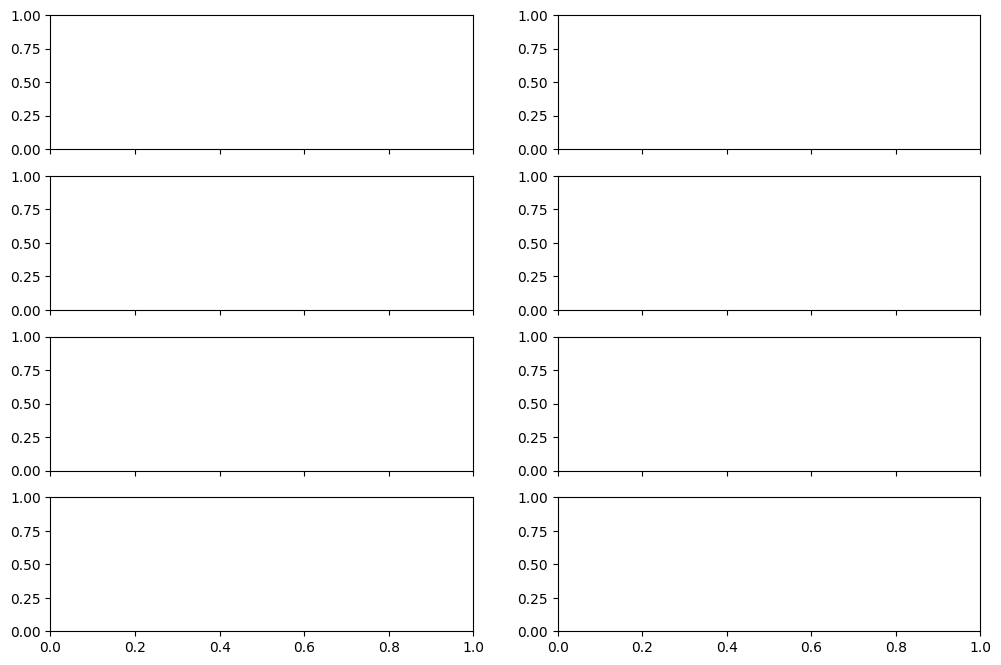

In [ ]:
#Noah PCA/NMF...
import csv
#import Sc Ka and Kb csv files
with open('SC_Ka.csv', mode='r', newline='', encoding='utf-8') as file:
    reader = csv.reader(file)
    # Convert the reader object directly into a Python list
    ScKa_list = list(reader)

ScKa_data = ScKa_list[1:]
print(ScKa_data)
ScKaSc = scaler.fit_transform(ScKa_data)
ScKaSSc = Nscaler.fit_transform(ScKa_data)

#Perform PCA on the I1-normalized sum data
n_components = 2
pca = PCA(n_components=n_components)
W_pca = pca.fit_transform(ScKaSc)
H_pca = pca.components_

# Perform NMF on the I1-normalized sum data
nmf = NMF(n_components=n_components, init='nndsvd', max_iter=1000)
W_nmf = nmf.fit_transform(ScKaSSc)
H_nmf = nmf.components_

# Perform ICA on the I1-normalized sum data
ica = FastICA(n_components=n_components, algorithm='parallel', max_iter=200, whiten_solver='eigh')
W_ica = ica.fit_transform(ScKaSc)
H_ica = ica.components_

# Perfom Latent Dirichlet Allocation on the I1-normalized sum data
lda = LatentDirichletAllocation(n_components=n_components, max_iter=10)
W_ica = lda.fit_transform(ScKaSSc)
H_lda = lda.components_
indow = 11
poly_order = 3

#smooth the PCA and NMF weights using Savitzky-Golay filter
W_pca_smooth = np.zeros_like(W_pca)
W_nmf_smooth = np.zeros_like(W_nmf)
W_ica_smooth = np.zeros_like(W_ica)
W_lda_smooth = np.zeros_like(W_ica) 


for i in range(n_components):
    W_pca_smooth[:, i] = savgol_filter(W_pca[:, i], window, poly_order)
    W_nmf_smooth[:, i] = savgol_filter(W_nmf[:, i], window, poly_order)
    W_ica_smooth[:, i] = savgol_filter(W_ica[:, i], window, poly_order)
    W_lda_smooth[:, i] = savgol_filter(W_ica[:, i], window, poly_order)

#create test points for later
test_idx = X_trans.shape[0] // 2
ein_val = Ei[test_idx]

# --- 2D Plots of PCA and NMF Components and Weights ---
fig, axes = plt.subplots(4, 2, figsize=(12, 8), sharex='col')

for i in ScKa_data:
    Ei.append = ScKa_data[i][0]
print(Ei)

# --- PCA Plots ---
for i in range(n_components):
    axes[0, 0].plot(Ef, abs(H_pca[i]), label=f'PC {i+1}')
    axes[0, 1].plot(Ei.T, abs(W_pca_smooth[:, i]), label=f'PC {i+1} Weight')
axes[0, 0].plot(Ef, X_trans[test_idx, :]/3, 'k--', label='Original Data', alpha=0.5)
axes[0, 0].set_title('Normalized PCA Components (Spectral Shapes)')
axes[0, 1].set_title('PCA Weights (vs Ein)')

#set readable axes limits for the PCA and NMF weight plots
Ei_min = 9800
W_pcamax = 10
W_nmfmax = 1
axes[0, 1].set_xlim(Ei_min, np.max(Ei.T))
axes[0, 1].set_ylim(0, W_pcamax)
axes[1, 1].set_xlim(Ei_min, np.max(Ei.T))
axes[1, 1].set_ylim(np.min(W_nmf_smooth), W_nmfmax)
axes[2, 1].set_xlim(Ei_min, np.max(Ei.T))
axes[2, 1].set_ylim(0, W_nmfmax)


# --- NMF Plots ---
for i in range(n_components):
    axes[1, 0].plot(Ef, H_nmf[i], label=f'NMF {i+1}')
    axes[1, 1].plot(Ei.T, W_nmf_smooth[:, i], label=f'NMF {i+1} Weight')
    
# plot original data for comparison
axes[1, 0].plot(Ef, X_trans[test_idx, :], 'k--', label='Original Data', alpha=0.5)
axes[1, 0].set_title('Normalized NMF Components (Spectral Shapes)')
axes[1, 1].set_title(' NMF Weights (vs Ein)')

# --- ICA Plots ---
for i in range(n_components):
    axes[2, 0].plot(Ef, abs(H_ica[i]), label=f'ICA {i+1}')
    axes[2, 1].plot(Ei.T, abs(W_ica_smooth[:, i]), label=f'ICA {i+1} Weight')
axes[2, 0].plot(Ef, X_trans[test_idx, :]/4, 'k--', label='Original Data', alpha=0.5)
axes[2, 0].set_title('Normalized ICA Components (Spectral Shapes)')
axes[2, 1].set_title('ICA Weights (vs Ein)')

# --- LDA Plots ---
for i in range(n_components):
    axes[3, 0].plot(Ef, abs(H_lda[i]), label=f'LDA {i+1}')
    axes[3, 1].plot(Ei.T, abs(W_lda_smooth[:, i]), label=f'LDA {i+1} Weight')
axes[3, 0].plot(Ef, X_trans[test_idx, :], 'k--', label='Original Data', alpha=0.5)
axes[3, 0].set_title('Normalized LDA Components (Spectral Shapes)')
axes[3, 1].set_title('LDA Weights (vs Ein)')

# Formatting
for ax in axes.flat:
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[1, 0].set_xlabel('Eem (eV)')
axes[1, 1].set_xlabel('Ein (eV)')
plt.tight_layout()
plt.show()



In [ ]:
#Simons initial fits.
"""
Created on Fri Jul 25 11:15:51 2025

@author: smkrstevski
"""

import os
os.chdir('/home/student.unimelb.edu.au/smkrstevski/Python/packages')
from read_ct import read_ct
from read_ka import find_ka
from plot_ct import plot_ct
from fitting_function_mk4 import fitting_function, read_exp
from metric_table import metric_table_tex
from fitting_function_mk4 import make_fwhm_table

# Extablishes Directory and paths
dire = '/home/student.unimelb.edu.au/smkrstevski/Documents/copper_paper/'
ct_path = dire + "ct_files/"
fit_path = dire + "fitting/"
exp_path = dire + "exp_data/"
eval_path = dire + "eval_spectra/"
mix_path = dire + "mix_files/"

# Reads in satellite data
Dia = [
    read_ct(ct_path + "Dia" + '/icu_4s.fcu_4s.ct'),
    read_ct(ct_path + "Dia" + '/icu_4f.fcu_4f.ct'),
    read_ct(ct_path + "Dia" + '/icu_5s.fcu_5s.ct'),
    read_ct(ct_path + "Dia" + '/icu_5g.fcu_5g.ct')
    ]

sat_3d = [
    read_ct(ct_path + "3d" + '/icu_4s.fcu_4s.ct'),
    read_ct(ct_path + "3d" + '/icu_4f.fcu_4f.ct'),
    read_ct(ct_path + "3d" + '/icu_5s.fcu_5s.ct')
    ]

sat_4s = [
    read_ct(ct_path + "4s" + '/icu_4s.fcu_4s.ct'),
    read_ct(ct_path + "4s" + '/icu_4f.fcu_4f.ct'),
    read_ct(ct_path + "4s" + '/icu_5s.fcu_5s.ct'),
    read_ct(ct_path + "4s" + '/icu_5g.fcu_5g.ct'),
    read_ct(ct_path + "4s" + '/icu_6s.fcu_6s.ct'),
    ]

sat_3p = [
    read_ct(ct_path + "3p" + '/icu_4s.fcu_4s.ct'),
    read_ct(ct_path + "3p" + '/icu_4f.fcu_4f.ct'),
    read_ct(ct_path + "3p" + '/icu_5s.fcu_5s.ct')
    ]

sat_3s = [
    read_ct(ct_path + "3s" + '/icu_4s.fcu_4s.ct'),
    read_ct(ct_path + "3s" + '/icu_4f.fcu_4f.ct'),
    read_ct(ct_path + "3s" + '/icu_5s.fcu_5s.ct'),
    read_ct(ct_path + "3s" + '/icu_5g.fcu_5g.ct')
    ]

sat_3d4s = [
    read_ct(ct_path + "3d4s" + '/icu_4s.fcu_4s.ct'),
    read_ct(ct_path + "3d4s" + '/icu_4f.fcu_4f.ct'),
    read_ct(ct_path + "3d4s" + '/icu_5s.fcu_5s.ct')
    ]

sat_3d3d = [
    read_ct(ct_path + "3d3d" + '/icu_4s.fcu_4s.ct'),
    read_ct(ct_path + "3d3d" + '/icu_4f.fcu_4f.ct'),
    read_ct(ct_path + "3d3d" + '/icu_5s.fcu_5s.ct')
    ]

Nguyen_sat = [
    read_ct(ct_path + "Nguyen" + '/Kaicu-5s.fcu-5s.ct'),
    read_ct(ct_path + "Nguyen" + '/Kaicu4s0-5s.fcu4s0-5s.ct'),
    read_ct(ct_path + "Nguyen" + '/Kaicu3d9-5s.fcu3d9-5s.ct'),
    read_ct(ct_path + "Nguyen" + '/Kaicu3p5-5s.fcu3p5-5s.ct'),
    read_ct(ct_path + "Nguyen" + '/Kaicu3s1-5s.fcu3s1-5s.ct'),
    read_ct(ct_path + "Nguyen" + '/Kaicu3d4s-5s.fcu3d4s-5s.ct'),
    read_ct(ct_path + "Nguyen" + '/Kaicu3d8-5s.fcu3d8-5s.ct'),
    ]

all_sat = [
    read_ct(ct_path + "Dia" + '/icu_5g.fcu_5g.ct'),
    read_ct(ct_path + "4s" + '/icu_6s.fcu_6s.ct'),
    read_ct(ct_path + "3d" + '/icu_5s.fcu_5s.ct'),
    read_ct(ct_path + "3p" + '/icu_5s.fcu_5s.ct'),
    read_ct(ct_path + "3s" + '/icu_5g.fcu_5g.ct'),
    read_ct(ct_path + "3d4s" + '/icu_5s.fcu_5s.ct'),
    read_ct(ct_path + "3d3d" + '/icu_5s.fcu_5s.ct')
    ]

sat_list = ["Diagram", "4s", "3d", "3p", "3s","3d4s","3d3d"]
# %% 
D_ka = find_ka(mix_path + "D_fcu_5g_mix.txt")
sat_4s_ka = find_ka(mix_path + "4s_fcu_6s_mix.txt")
sat_3d_ka = find_ka(mix_path + "3d_fcu_5s_mix.txt")
sat_3p_ka = find_ka(mix_path + "3p_fcu_5s_mix.txt")
sat_3s_ka = find_ka(mix_path + "3s_fcu_5g_mix.txt")
sat_3d4s_ka = find_ka(mix_path + "3d4s_fcu_5s_mix.txt")
sat_3d3d_ka = find_ka(mix_path + "3d3d_fcu_5s_mix.txt")
sat_3d3d_ka_4s = find_ka(mix_path + "3d3d_fcu_5s_mix.txt")

# %% Fitting with all Satellites (ka1 ka2 FWHM method)
data_type = "deut" # Switch for mend or deut

# Reads experimental data
data = read_exp(exp_path + "mendenhall_data.dat") if data_type == "mend" else read_exp(exp_path + "deutsch.txt",error_vals = False)

# Sets up common fitting paramters
cparams = [45 if data_type == "mend" else 12000,0,0,0,0,1,2,2]
cparam_var = [[(0,100),"s"] if data_type == "mend" else [(5000,50000),"s"],
              [0,"f"],[0,"f"],[0,"f"],[0,"f"],[1,"p"],[1,"p"],[1,"p"]]

# Sets up satellite paramters (Nguyen probs)
params = [[1, 0.58924, 0],  # Diagram guess
          [1, 0.07473, 0],  # 4s guess
          [1, 0.11494, 0],  # 3d guess
          [1, 0.04484, 0],  # 3p guess
          [1, 0.01789, 0],  # 3s guess
          [1, 0.01458, 0],  # 3d4s guess
          [1, 0.01009, 0]]  # 3d3d guess

param_var = [[[0,"f"], [0,"f"], [1,"c"]],  # Diagram Bounds
             [[0,"f"], [0,"f"], [1,"c"]],  # 4s Bounds
             [[0,"f"], [0,"f"], [1,"c"]],  # 3d Bounds
             [[0,"f"], [0,"f"], [3,"c"]],  # 3p Bounds
             [[0,"f"], [0,"f"], [3,"c"]],  # 3s Bounds
             [[0,"f"], [0,"f"], [1,"c"]],  # 3d4s Bounds
             [[0,"f"], [0,"f"], [1,"c"]],] # 3d3d Bounds

#List of Satellite names
sat_list = ["Diagram", "4s", "3d", "3p", "3s","3d4s","3d3d"]
cols = ["b","darkorange","green","red","mediumorchid","saddlebrown","darkslategrey"]
# Ka dictionary
ka_dict = [D_ka, sat_4s_ka, sat_3d_ka, sat_3p_ka, sat_3s_ka, sat_3d4s_ka, sat_3d3d_ka]

fitting_function([all_sat[0]], data, cparams, [params[0]], cparam_var, [param_var[0]], sat_cols= cols,
                 spec_sat = True, sat_list = [sat_list[0]], plot_init = True, fwhm_scale = "unscaled", ka_dict = ka_dict,
                 fig_title=data_type + "_D", directory = fit_path + data_type + '/paper_fits/', width='ka1ka2')

fitting_function(all_sat[0:2], data, cparams, params[0:2], cparam_var, param_var[0:2], sat_cols= cols,
                 spec_sat = True, sat_list = sat_list[0:2], plot_init = False, fwhm_scale = "unscaled", ka_dict = ka_dict,
                 fig_title=data_type + "_D_4s", directory = fit_path + data_type + '/paper_fits/', width='ka1ka2')

fitting_function(all_sat[0:3], data, cparams, params[0:3], cparam_var, param_var[0:3], sat_cols= cols,
                 spec_sat = True, sat_list = sat_list[0:3], plot_init = False, fwhm_scale = "unscaled", ka_dict = ka_dict,
                 fig_title=data_type + "_D_4s_3d", directory = fit_path + data_type + '/paper_fits/', width='ka1ka2')

fitting_function(all_sat[0:4], data, cparams, params[0:4], cparam_var, param_var[0:4], sat_cols= cols,
                 spec_sat = True, sat_list = sat_list[0:4], plot_init = False, fwhm_scale = "unscaled", ka_dict = ka_dict,
                 fig_title=data_type + "_D_4s_3d_3p", directory = fit_path + data_type + '/paper_fits/', width='ka1ka2')

fitting_function(all_sat[0:5], data, cparams, params[0:5], cparam_var, param_var[0:5], sat_cols= cols,
                 spec_sat = True, sat_list = sat_list[0:5], plot_init = False, fwhm_scale = "unscaled", ka_dict = ka_dict,
                 fig_title=data_type + "_D_4s_3d_3p_3s", directory = fit_path + data_type + '/paper_fits/', width='ka1ka2')

fitting_function(all_sat[0:6], data, cparams, params[0:6], cparam_var, param_var[0:6], sat_cols= cols,
                 spec_sat = True, sat_list = sat_list[0:6], plot_init = False, fwhm_scale = "unscaled", ka_dict = ka_dict,
                 fig_title=data_type + "_D_4s_3d_3p_3s_3d4s", directory = fit_path + data_type + '/paper_fits/', width='ka1ka2')

fitting_function(all_sat[0:7], data, cparams, params[0:7], cparam_var, param_var[0:7], sat_cols= cols,
                 spec_sat = True, sat_list = sat_list[0:7], plot_init = False, fwhm_scale = "unscaled", ka_dict = ka_dict,
                 fig_title=data_type + "_D_4s_3d_3p_3s_3d4s_3d3d", directory = fit_path + data_type + '/paper_fits/', width='ka1ka2')

# %% Eval Spectra
expansion = ["4s", "4f", "5s"]
cols = ["b","darkorange","green","red","mediumorchid", "saddlebrown", "darkslategrey"]
D_ka_dict = find_ka(mix_path + "D_fcu_5g_mix.txt")

plot_ct(cts = Dia, sat_names = expansion + ["5g","6s"], path = eval_path, name = "Diagram_eval",
        max_y = 'same', xlim = [8020,8060], conv_stats = True, col = "black", 
        split_trans = True, ka_dicts=[D_ka]*5)

plot_ct(cts = sat_4s, sat_names = expansion + ["5g", "6s"], path = eval_path, name = "4s_eval",
        max_y = 'same', xlim = [8020,8060], conv_stats = [True]*5, col = "black",
        split_trans = [True]*5, ka_dicts=[sat_4s_ka]*5)

plot_ct(cts = sat_3d + [Nguyen_sat[2]], sat_names = expansion + ["Nguyen \n et al."], path = eval_path, name = "3d_eval", 
        max_y = 'same', xlim = [8020,8060], conv_stats = [True]*3+[False], col = "black",
        split_trans = [True]*3 + [False], ka_dicts=[sat_3d_ka]*3)

plot_ct(cts = sat_3p + [Nguyen_sat[3]], sat_names = expansion + ["Nguyen \n et al."], path = eval_path, name = "3p_eval",
        max_y = 'same', xlim = [8020,8060], conv_stats = [True]*3+[False], col = "black",
        split_trans = [True]*3 + [False], ka_dicts=[sat_3p_ka]*3)

plot_ct(cts = sat_3s + [Nguyen_sat[4]], sat_names = expansion + ["5g","Nguyen \n et al."], path = eval_path, name = "3s_eval",
        max_y = 'same', xlim = [8020,8060], conv_stats = [True]*4+[False], col = "black",
        split_trans = [True]*4 + [False], ka_dicts=[sat_3s_ka]*4)

plot_ct(cts = sat_3d4s, sat_names = expansion, path = eval_path, name = "3d4s_eval",
        max_y = 'same', xlim = [8020,8060], conv_stats = [True]*3, col = "black",
        split_trans = [True]*3, ka_dicts=[sat_3d4s_ka]*3)

plot_ct(cts = sat_3d3d + [Nguyen_sat[6]], sat_names = expansion + ["Nguyen \n et al."], path = eval_path, name = "3d3d_eval",
        max_y = 'same', xlim = [8020,8060], conv_stats = [True]*3+[False], col = "black",
        split_trans = [True]*3 + [False], ka_dicts= [sat_3d3d_ka_4s] + [sat_3d3d_ka]*2)

plot_ct(cts = all_sat, sat_names = ["Dia.", "[4s]", "[3d]", "[3p]", "[3s]", "[3d4s]", "[3d3d]"],
        path = eval_path, name = "Combined_eval", y_lab = "Satellite Transition",
        max_y = 'diff', xlim = [8020,8060], conv_stats = False, col = cols)

# %% Metric table
all_cts = [Dia, sat_4s, sat_3d, sat_3p, sat_3s, sat_3d4s, sat_3d3d]
print(metric_table_tex(all_cts))
#%%
for a, sat in enumerate(all_sat):
    print(sat_list[a])
    make_fwhm_table(sat)
    print("\n")


In [ ]:
# Ramesh Main execution starts here
File_loc = r'/Volumes/One Touch/July2026/nexus/'  # Path to the directory containing the data files 
# List of scan numbers to process
Scan_Nos = np.array(['305229', '305230', '305231', '305232'])

# Define the dimensions of the crystal region to extract from the detector images
crystal_width = 50
crystal_height = 15

plot_data = int(
    input('Do you want to plot the detector regions? (1=y, 0=n): ')
)
save = int(input('Do you want to save the data? (1=y, 0=n): '))
Strong_Scan = int(
    input('Is there a particular high intensity scan you want to use for determining the analyser ROIs? If yes type scan number, if no type 0: ')
)


# Get the analyser coordinates from the HDF files, either from a strong scan or the first scan in the list
Crystal_Coords = Get_Analysers(File_loc, Strong_Scan)

comb_data = None
Ef_comb = None
I1_comb = None
Ei_comb = None
Progress_index = 0
scan_axis = 0


# Loop through each scan number, read the corresponding files, extract the data, and combine it
for idx, Scan_No in enumerate(Scan_Nos):
    Progress_index += 1
    print('Reading Scan:', Scan_No, round(100.0 * Progress_index / len(Scan_Nos), 2), '% Complete')
    
    nexus_file, hdf_files = Find_files(File_loc, Scan_No)
    if not nexus_file:
        print('Warning: Could not find nexus file for scan', Scan_No)
        continue
        
    nxs = nxload(File_loc + nexus_file)
    Ei, Ef, I1 = Get_Nexus(nxs)
    
    all_data = get_data(
        hdf_files,
        crystal_height,
        crystal_width,
        plot_data,
        Crystal_Coords,
        plot_scan_no=Scan_No,
    )
    
    # Dynamically determine the scanning axis based on the first file
    if idx == 0:
        if Ef is not None and Ef.ndim > 1:
            if abs(Ef[0, 1] - Ef[0, 0]) > 1e-6:
                scan_axis = 1
            else:
                scan_axis = 0
        else:
            scan_axis = 0

    # Drop the final overlapping point along the specific scanning axis for the first two scans only
    if idx < 2:
        if scan_axis == 1:
            if Ef is not None and Ef.ndim > 1: Ef = Ef[:, :-1]
            elif Ef is not None: Ef = Ef[:-1]
            
            if Ei is not None and Ei.ndim > 1: Ei = Ei[:, :-1]
            elif Ei is not None: Ei = Ei[:-1]
            
            if I1 is not None and I1.ndim > 1: I1 = I1[:, :-1]
            elif I1 is not None: I1 = I1[:-1]
            
            if all_data is not None: all_data = all_data[:, :-1, ...]
        else:
            if Ef is not None: Ef = Ef[:-1, ...]
            if Ei is not None: Ei = Ei[:-1, ...]
            if I1 is not None: I1 = I1[:-1, ...]
            if all_data is not None: all_data = all_data[:-1, ...]

    # Concatenate without flattening to preserve native multidimensional shapes
    if idx == 0:
        comb_data = all_data
        I1_comb = I1
        Ef_comb = Ef
        Ei_comb = Ei  
    else:
        comb_data = np.concatenate((comb_data, all_data), axis=scan_axis)
        I1_comb = np.concatenate((I1_comb, I1), axis=scan_axis)
        Ef_comb = np.concatenate((Ef_comb, Ef), axis=scan_axis)
        Ei_comb = np.concatenate((Ei_comb, Ei), axis=scan_axis)

# print(nxs.tree)

crystal_sum = np.sum(comb_data, axis=(-2, -3))
FFcounts = np.sum(comb_data, axis=(-1, -2, -3))
I1_comb = I1_comb * 10
U_counts = I1_comb

# Shapes will now perfectly align for the math operation
sum_data = FFcounts / U_counts
sigma_I = sum_data * np.sqrt(
    (1.0 / (FFcounts + 1e-10)) + (1.0 / (U_counts + 1e-10))
)

# Create a dictionary to hold all the relevant data for saving
data_structure = {
    'all_data': comb_data,
    'crystal_data': crystal_sum,
    'sum_data': sum_data,
    'sigma_I': sigma_I,
    'Ei': Ei_comb,
    'Ef': Ef_comb,
    'I1': I1_comb,
    'FFcounts': FFcounts,
    'BGcounts': B_counts,
}
# save the data structure to a file if the user requested it
if save:
    with open(Scan_Nos[0] + 'to' + Scan_Nos[-1] + '_Data_Struc_SE', 'wb') as f:
        pickle.dump(data_structure, f)

print('All Data Shape:', data_structure['all_data'].shape)
print('Crystal Data Shape:', data_structure['crystal_data'].shape)
print('Sum Data Shape:', data_structure['sum_data'].shape)
print('I1 Shape:', data_structure['I1'].shape)
print('Ei Shape:', data_structure['Ei'].shape)
print('Ef Shape:', data_structure['Ef'].shape)

# Handle Plotting based on the dimensions we just built
if sum_data.ndim > 1:
    plot_Ef = Ef_comb[0, :] if scan_axis == 1 else Ef_comb[:, 0]
    plot_Ei = Ei_comb[:, 0] if scan_axis == 1 else Ei_comb[0, :]
    
    # 3D surface plot
    surface_plot(plot_Ef, plot_Ei, sum_data, r"$I_F/I_0$")
    
    # 1D slice or averaged plot
    plt.figure()
    if scan_axis == 1:
        plt.plot(plot_Ef, np.log(np.sum(sum_data, axis=0)), label='Combined Scans (Summed)')
    else:
        plt.plot(plot_Ef, np.log(np.sum(sum_data, axis=1)), label='Combined Scans (Summed)')
    plt.xlabel(r'Emission Energy (eV)')
    plt.ylabel(r'$I_F/I_0$')
    plt.title('Combined Emission Spectrum')
    plt.legend()
    plt.show()

else:
    # Basic 1D plot
    plt.figure()
    plt.plot(data_structure['Ef'], np.log(data_structure['sum_data']), label='Combined Scans')
    plt.xlabel(r'Emission Energy (eV)')
    plt.ylabel(r'$I_F/I_0$')
    plt.title('Combined Emission Spectrum')
    plt.legend()
    plt.show()
    
#save the data if save variable set to true
if save:
    print('>> Saving Crystal Coordinates and Combined Data')
    #Checks all processed data folders exist, if not creates them:
    if not os.path.exists(File_loc + 'processed_data/'):
        os.makedirs(File_loc + 'processed_data/')
    if not os.path.exists(File_loc + 'processed_data/Uncorrected_data/'):
        os.makedirs(File_loc + 'processed_data/Uncorrected_data/')
    if not os.path.exists(File_loc + 'processed_data/Background_data/'):
        os.makedirs(File_loc + 'processed_data/Background_data/')
    if not os.path.exists(File_loc + 'processed_data/Spliced_data/'):
        os.makedirs(File_loc + 'processed_data/Spliced_data/')
    if not os.path.exists(File_loc + 'processed_data/Corrected_data/'):
        os.makedirs(File_loc + 'processed_data/Corrected_data/')
    #Saves the data for later stages of processing and analysis:
    with open('/Users/chantler/DiamondData/processed_data/' + Scan_Nos[0] + '-' + Scan_Nos[-1] + '_Crystal_Coords', 'wb') as f:
        pickle.dump(Crystal_Coords, f)
    with open('/Users/chantler/DiamondData/processed_data/Data_struct', 'wb') as f:
        pickle.dump(data_structure, f)
    with open('/Users/chantler/DiamondData/processed_data/Uncorrected_data/' + Scan_Nos[0] + '-' + Scan_Nos[-1] + '_comb_data', 'wb') as f:
        pickle.dump(comb_data, f)
    with open('/Users/chantler/DiamondData/processed_data/Uncorrected_data/Ef', 'wb') as f:
        pickle.dump(Ef_comb, f)
    with open('/Users/chantler/DiamondData/processed_data/Uncorrected_data/Ei', 'wb') as f:
        pickle.dump(Ei, f)
    with open('/Users/chantler/DiamondData/processed_data/Uncorrected_data/I1_comb', 'wb') as f:
        pickle.dump(I1_comb, f)

ValueError: invalid literal for int() with base 10: ''

In [ ]:
# Pierce Function Defs

# NOTE! need to run this cell first everytime you open this notebook, but once you run it
# once you don't need to run it again to run the other cells.

''' This is the master script for the analysis of XR-HERFD data. It is a culmination of the
Multiple_Scan_No_Masking_With_Stats.py and will eventually include cells to implement the
binary splicing processing as well as redundant saving. This will drastically improve
efficiency, simplicity and allow for enhanced modification/manipulation of the analysis
procedure.

- Pierce Bowman, 1/10/2025.

There have been many upgrades and improvements made to the script. we have reached a point
where we have begun implementing the splicing procedure to the processed data. However, after
Ramesh's investigation we have found the the calibration for the Zinc dataset on I20 was
excellent, with little improvement to be gained from the splicing process. So I will now proceed
to introducing an 'Error and Significance Analysis' cell which provides important insight
for the paper on the discovery of the Zinc K alpha n=2 satellite.

- Pierce Bowman, 24/11/2025.

We are yet to properly implement the binary data splicing, though we have been able to use
what he have to produce the results for the Zinc K alpha satellite paper which has been submitted
today. Next steps for this script would be to create a version where we can take in both the
RIXS scan style files and the DOSE scan style files then create a uniform data object to operate
on as opposed to haphazard scaling and concatenating of data. Then of course, add in the splicing
process and an optional/parallel process. As of rright now though, I am going to try and do
some pre-processing of the Scandium dataset which is of lower quality and riddled with hot pixels

- Pierce Bowman, 1/4/2026.
'''

# =======================================================================================================
# Module Imports
# =======================================================================================================
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from mpl_toolkits import mplot3d
import scipy.signal
from mpl_toolkits.mplot3d import Axes3D
import h5py
from nexusformat.nexus import *
from matplotlib import cm
from scipy.optimize import curve_fit
import sys
import json
from scipy import interpolate
import matplotlib.colors as colors
import pystyle
from pystyle import Colors, Colorate
import os
import re
import time
from scipy.ndimage import label, center_of_mass, gaussian_filter
import pickle
from sklearn.decomposition import NMF, PCA
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from _pca import PCA as PCA2


# =======================================================================================================
# Set-up output parameters
# =======================================================================================================
# Ideal ploting parameters
plt.rc('xtick', labelsize=13)
plt.rc('ytick', labelsize=13)
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.titlesize'] = 16

# =======================================================================================================
# Define the relevant raw data file paths
# =======================================================================================================
# Define location of nexus/hdf files
File_loc = '/Volumes/One Touch/July2026/nexus/' # experimental data location
elastic_path = '/Volumes/One Touch/July2026/nexus/' # Elastic scan path for binary data splicing alignment
#define the first file number
First_Scan_No = 305229
#define final scan number
Last_Scan_Number1 = 305232 # started getting extra crystals after scan 268205 ?
#as sometimes there are dummy scans, some scans re skipped. need to iterate basedon useful scans:
scan_steps = 3
#Generate all the intermidiate scan numbers
Scan_Nos= np.asarray(list(range(First_Scan_No,Last_Scan_Number1+1,scan_steps)))

# # If another section:

# #define the first file number
# First_Scan_No1 = 268532
# #define final scan number
# Last_Scan_Number = 268631
# #Generate all the intermidiate scan numbers
# Scan_Nos= np.concatenate((Scan_Nos,np.asarray(list(range(First_Scan_No1,Last_Scan_Number+1,3)))))#['268070', '268073','268076'] # '235801' # '236469' # '153148' #

#convert integards to strings
Scan_Nos=Scan_Nos.astype(int).astype(str)#[str(int(x)) for x in Scan_Nos]

elastic_scan_num = 305239 # 267998 # 268220

# =======================================================================================================
# Define the crystal image parameters:
# =======================================================================================================
# Input known parameters for the experiment:
num_detectors = 2 # number of detector arrays
num_crystal_analysers = 7 # number of crystal analysers per detector

# define the half width of the desired crystal image
# crystal images on medipix2 appeared bigger than medipix1, might need to extend from 50 to 60 half height?
# crystal_width = 50
crystal_width = 60

# define the half height of the desired crystal image
# crystal images on medipix2 appeared bigger, might need to extend from 15 to 20 half height?
# crystal_height = 15 
crystal_height = 20

# define the slice_height for splicing:
# !! Note: the 2 x crystal_height must be even and divisible by slice_height:
# num_slices = (crystal_height*2)/slice_height
slice_height = 4
num_slices = (2*crystal_height)/slice_height

# Background ROI params:
bg_left_bound = 0
bg_right_bound = 20 # full width of detector = 1033 pixels
bg_top_bound = 5 # full height of detector = 256 pixels
bg_bottom_bound = 0

# =======================================================================================================
# Plotting specific params
# =======================================================================================================
plot_data = 0
save = 1
Strong_Scan = 0
Binary_Splicing = 0 # set to 1 to splice, 0 to not.
FLIP_VERTICAL = 1 # set to True to flip images vertically for correct orientation

# ==============================================================================================================
# Functions for XR-HERFD Run time processing:
# ==============================================================================================================





In [ ]:
# Data Acquisition and Collation Section:
# ==============================================================================================================

print('>>>> Retrieving DOSE experimental data')

# print the first frame for sanity check:
#first_frames = Get_single_full_image(File_loc,Scan_Nos[0])[0]
#print('First frame shape (before any flipping):', first_frames[0].shape)
#fig, ax = plt.subplots(num_detectors, 1, figsize=(9,4*num_detectors))

#for d in np.arange(num_detectors):
#    print(f'>> Detector {d+1} first frame')
#    first_frames[d] = np.flip(first_frames[d], axis=-2) if FLIP_VERTICAL else first_frames[d]
#    print('First frame shape:', first_frames[d].shape)
#    img_dimensions = first_frames[d].shape[1:3]
#    print('Image dimensions:', img_dimensions)

#    c = ax[d].pcolormesh(first_frames[d][4][0], cmap='rainbow',shading='gouraud') # proper measurements start from 4th incident energy
#    ax[d].set_title('Medipix '+str(d+1), fontsize=14)
#    cbar=fig.colorbar(c, ax=ax[d], orientation='horizontal').set_label(label='Counts/Pixel',size=12)

#fig.tight_layout(pad=4.0)
#fig.show()

# print the last frame for sanity check:
#last_frames = Get_single_full_image(File_loc,Scan_Nos[-1])
#print('Last frame shape (before any flipping):', last_frames[0][0].shape)
#fig, ax = plt.subplots(num_detectors, 1, figsize=(9,4*num_detectors))
#for d in np.arange(num_detectors):
#    print(f'>> Detector {d+1} last frame')
#    last_frames[d] = np.flip(last_frames[d], axis=-2) if FLIP_VERTICAL else last_frames[d]
#    print('Last frame shape:', last_frames[d].shape)
#    img_dimensions = last_frames[d].shape[1:3]
#    print('Image dimensions:', img_dimensions)

#    c = ax[d].pcolormesh(last_frames[d][4], cmap='rainbow',shading='gouraud') # proper measurements start from 4th incident energy
#    ax[d].set_title('Medipix '+str(d+1), fontsize=14)
#    cbar=fig.colorbar(c, ax=ax[d], orientation='horizontal').set_label(label='Counts/Pixel',size=12)

#fig.tight_layout(pad=4.0)
#fig.show()

#Get the coordinates of the crystal images
Crystal_Coords = Get_Analysers(File_loc,Strong_Scan)

# Set up Scan file loop
comb_data = []
Ef_comb = []
I1_comb = []
Ei_comb = []
Progress_index = 0
print('=============================================================')
print('>> Reading in raw data:')
for idx, Scan_No in enumerate(Scan_Nos):
    Progress_index += 1
    print('Reading Scan:', Scan_No, round(100.0 * Progress_index / len(Scan_Nos), 2), '% Complete')
    
    nexus_file, hdf_files = Find_files(File_loc, Scan_No)
    if not nexus_file:
        print('Warning: Could not find nexus file for scan', Scan_No)
        continue
        
    nxs = nxload(File_loc + nexus_file)
    Ei, Ef, I1 = Get_Nexus(nxs)
    
    all_data = get_data(
        hdf_files,
        crystal_height,
        crystal_width,
        plot_data,
        Crystal_Coords,
       # plot_scan_no=Scan_No,
    )
    
    # Dynamically determine the scanning axis based on the first file
    if idx == 0:
        if Ef is not None and Ef.ndim > 1:
            if abs(Ef[0, 1] - Ef[0, 0]) > 1e-6:
                scan_axis = 1
            else:
                scan_axis = 0
        else:
            scan_axis = 0

    # Drop the final overlapping point along the specific scanning axis for the first two scans only
    if idx < 2:
        if scan_axis == 1:
            if Ef is not None and Ef.ndim > 1: Ef = Ef[:, :-1]
            elif Ef is not None: Ef = Ef[:-1]
            
            if Ei is not None and Ei.ndim > 1: Ei = Ei[:, :-1]
            elif Ei is not None: Ei = Ei[:-1]
            
            if I1 is not None and I1.ndim > 1: I1 = I1[:, :-1]
            elif I1 is not None: I1 = I1[:-1]
            
            if all_data is not None: all_data = all_data[:, :-1, ...]
        else:
            if Ef is not None: Ef = Ef[:-1, ...]
            if Ei is not None: Ei = Ei[:-1, ...]
            if I1 is not None: I1 = I1[:-1, ...]
            if all_data is not None: all_data = all_data[:-1, ...]

    # Concatenate without flattening to preserve native multidimensional shapes
    if idx == 0:
        comb_data = all_data
        I1_comb = I1
        Ef_comb = Ef
        Ei_comb = Ei  
    else:
        comb_data = np.concatenate((comb_data, all_data), axis=scan_axis)
        I1_comb = np.concatenate((I1_comb, I1), axis=scan_axis)
        Ef_comb = np.concatenate((Ef_comb, Ef), axis=scan_axis)
        Ei_comb = np.concatenate((Ei_comb, Ei), axis=scan_axis)

# important data info
print("==============================================================")
print(">>>> Data Information:")
print(">> Crystal_Coords | Type:", type(Crystal_Coords), "| shape:", np.array(Crystal_Coords).shape)
print(">> comb_data shape:", comb_data.shape)
print(">> I1_comb shape:", I1_comb.shape)
num_Ef = len(comb_data)
num_Ei = len(comb_data[1])
print(f">> Number of Emission Energies = {num_Ef}")
print(f">> Number of Incident Energies = {num_Ei}")

# show some useful plots to visualise the un-processed data
for img in np.arange(num_crystal_analysers*num_detectors):
    fig, ax = plt.subplots()
    c = ax.pcolormesh(comb_data[0,0,:,:,img], cmap='rainbow',shading='gouraud')
    cbar=fig.colorbar(c,orientation='vertical').set_label(label='Counts/Pixel',size=14)
    ax.set_title(f'Crystal img {img+1}, first scan')
    fig.show()

    fig, ax = plt.subplots()
    c = ax.pcolormesh(comb_data[-1,-1,:,:,img], cmap='rainbow',shading='gouraud')
    cbar=fig.colorbar(c,orientation='vertical').set_label(label='Counts/Pixel',size=14)
    ax.set_title(f'Crystal img {img+1}, last scan')
    fig.show()

# first_crystal_data = np.sum(comb_data[:,:,:,:,0], axis=(2,3)) # sum over spatial dimensions only for first crystal
# surface_plot(Ef_comb, Ei, first_crystal_data, r'$I_F$ first crystal')
# surface_plot(Ef_comb, Ei, np.log(first_crystal_data), r'$ln(I_F)$ first crystal')

# SUM DATA PLOT
# calculate the sum_data:
sum_data = np.sum(comb_data, axis=(2,3,4)) # sum over spatial and crystal dimensions
print('sum_data shape:', sum_data.shape)
# normalize sum_data by I1_comb
normalized_sum_data = sum_data / I1_comb
# plot both the normalized and unnormalized data
contour_plot(Ef_comb, Ei, sum_data, r'$I_F$')
contour_plot(Ef_comb, Ei, normalized_sum_data, r'$I_F/I_0$')

#save the data if save variable set to true
if save:
    print('>> Saving Crystal Coordinates and Combined Data')
    #Checks all processed data folders exist, if not creates them:
    if not os.path.exists(File_loc + 'processed_data/'):
        os.makedirs(File_loc + 'processed_data/')
    if not os.path.exists(File_loc + 'processed_data/Uncorrected_data/'):
        os.makedirs(File_loc + 'processed_data/Uncorrected_data/')
    if not os.path.exists(File_loc + 'processed_data/Background_data/'):
        os.makedirs(File_loc + 'processed_data/Background_data/')
    if not os.path.exists(File_loc + 'processed_data/Spliced_data/'):
        os.makedirs(File_loc + 'processed_data/Spliced_data/')
    if not os.path.exists(File_loc + 'processed_data/Corrected_data/'):
        os.makedirs(File_loc + 'processed_data/Corrected_data/')
    #Saves the data for later stages of processing and analysis:
    with open('/Users/chantler/DiamondData/processed_data/' + Scan_Nos[0] + '-' + Scan_Nos[-1] + '_Crystal_Coords', 'wb') as f:
        pickle.dump(Crystal_Coords, f)
    with open('/Users/chantler/DiamondData/processed_data/img_dimensions', 'wb') as f:
        pickle.dump(img_dimensions, f)
    with open('/Users/chantler/DiamondData/processed_data/Uncorrected_data/' + Scan_Nos[0] + '-' + Scan_Nos[-1] + '_comb_data', 'wb') as f:
        pickle.dump(comb_data, f)
    with open('/Users/chantler/DiamondData/processed_data/Uncorrected_data/Ef', 'wb') as f:
        pickle.dump(Ef_comb, f)
    with open('/Users/chantler/DiamondData/processed_data/Uncorrected_data/Ei', 'wb') as f:
        pickle.dump(Ei, f)
    with open('/Users/chantler/DiamondData/processed_data/Uncorrected_data/I1_comb', 'wb') as f:
        pickle.dump(I1_comb, f)

del comb_data
del Ef_comb
del Ei_comb
del I1_comb


>>>> Retrieving DOSE experimental data
>> Detector 0:
Sparce Data Read in Took:  1.0967254638671875e-05 Seconds
Threshold = 358.4
>> Detector 1:
Sparce Data Read in Took:  6.198883056640625e-06 Seconds
Threshold = 162.7
>> Crystal Positions:
Medipix1 Crystal:  1 , Position:  (121, 106)
Medipix1 Crystal:  2 , Position:  (121, 245)
Medipix1 Crystal:  3 , Position:  (122, 376)
Medipix1 Crystal:  4 , Position:  (123, 516)
Medipix1 Crystal:  5 , Position:  (124, 657)
Medipix1 Crystal:  6 , Position:  (121, 799)
Medipix1 Crystal:  7 , Position:  (126, 944)
Medipix2 Crystal:  1 , Position:  (119, 65)
Medipix2 Crystal:  2 , Position:  (124, 221)
Medipix2 Crystal:  3 , Position:  (121, 368)
Medipix2 Crystal:  4 , Position:  (122, 509)
Medipix2 Crystal:  5 , Position:  (121, 660)
Medipix2 Crystal:  6 , Position:  (119, 813)
Medipix2 Crystal:  7 , Position:  (119, 956)
>> Reading in raw data:
Reading Scan: 305229 50.0 % Complete


TypeError: get_data() missing 1 required positional argument: 'Crystal_Coords'

In [ ]:
# Correction: Load Data + Calculate Background
# ==============================================================================================================

print('>>>> Loading data and computing background statistics')

# Load energy data
Ef_data_file = open('/Users/chantler/DiamondData/processed_data/Uncorrected_data/Ef','rb')
Ef = np.array(pickle.load(Ef_data_file))
Ei_data_file = open('/Users/chantler/DiamondData/processed_data/Uncorrected_data/Ei','rb')
Ei = np.array(pickle.load(Ei_data_file))

# ===== BACKGROUND CALCULATION =====
print("==============================================================")
print('>>>> Computing background statistics')
Progress_index = 0
Background_avg_grid = np.zeros((num_detectors, len(Ef), len(Ei)))
Background_std_dev_grid = np.zeros((num_detectors, len(Ef), len(Ei)))
bg_roi_dimensions = 0

# This nested loop is set up to generate the background data objects. it should end up with
# a data object of dimensions (num_of_detectors, num_of_emission_energies, num_of_incident_energies)
# this is as each detector has different statistics and each energy pair will have different background counts
for count1, Scan_No in enumerate(Scan_Nos): # iterate though emission energies
    Progress_index+=1
    print(f'>> Reading Scan: {Scan_No} | {round(100.0*Progress_index/len(Scan_Nos), 2)}% Complete')
    background_nxs, background_hdf = Find_files(File_loc, Scan_No)
    nxs = nxload(File_loc + background_nxs)
    Ei_temp, Ef_temp, I1_temp = Get_Nexus(nxs)
    
    for count2, hdf in enumerate(background_hdf): # iterate through incident energies
        bg = read_HDF(File_loc + hdf)
        bg = np.flip(bg, axis=1) if FLIP_VERTICAL else bg
        bg = np.flip(bg, axis=0) if FLIP_VERTICAL else bg

        inc_avgs = []
        inc_std_dev = []
        for count3 in np.arange(len(bg)): # find the bg counts (and std) and save
            # bg_region = bg[count3, 0:50, 0:50] # 50x50 pixel region from corner
            # bg_region = bg[count3, 0:5, :] # whole width, first 5 rows
            # bg_region = bg[count3, 0:5, 0:5] # whole width, first 5 rows
            bg_region = bg[count3, bg_bottom_bound:bg_top_bound, bg_left_bound:bg_right_bound] # BG region defined by the parameters in the first cell
            bg_roi_dimensions = bg_region.shape if count1 == 0 and count2 == 0 and count3 == 0 else bg_roi_dimensions
            inc_avgs.append(np.average(bg_region))
            inc_std_dev.append(np.std(bg_region))

            # preview of background region
            if count1 == 0 and count2 == 0 and count3 == 0:
                fig, ax = plt.subplots(figsize=(15,4))
                c = ax.pcolormesh(bg[0], cmap='rainbow',shading='gouraud',)
                cbar=fig.colorbar(c,orientation='vertical')
                cbar.set_label(label='Counts/Pixel',size=14)
                rect = patches.Rectangle((bg_left_bound, bg_bottom_bound), bg_right_bound-bg_left_bound, bg_top_bound-bg_bottom_bound, linewidth=2, edgecolor='red', facecolor='none')
                ax.add_patch(rect)
                ax.set_title('First Scan Bg ROI Location Check')
                fig.show()

                fig, ax = plt.subplots(figsize=(15,4))
                c = ax.pcolormesh(bg_region, cmap='rainbow',shading='gouraud')
                cbar=fig.colorbar(c,orientation='vertical')
                cbar.set_label(label='Counts/Pixel',size=14)
                ax.set_title('First bg_region Check')
                # ax.set_xticks([])
                # ax.set_yticks([])
                # ax.set_xticklabels([])
                # ax.set_yticklabels([])
                ax.set_xlabel
                fig.show()

                print('------------------------------------------------')
                print(f'>> First bg_roi count total: {np.sum(bg_region)}')
                print(f'>> First bg_total count total: {np.sum(bg[0])}')
                print(f'>> First bg_total/bg_roi count ratio: {np.sum(bg[0])/np.sum(bg_region)}')
                print('------------------------------------------------')
            
            # BG Signal checking plots: -------------------------------------------------------------
            elif count1 == 20 and count2 == 0 and count3 == 114:
                fig, ax = plt.subplots(figsize=(15,4))
                c = ax.pcolormesh(bg[0], cmap='rainbow',shading='gouraud', vmin=0, vmax = 5)
                cbar=fig.colorbar(c,orientation='vertical')
                cbar.set_label(label='Counts/Pixel',size=14)
                rect = patches.Rectangle((bg_left_bound, bg_bottom_bound), bg_right_bound-bg_left_bound, bg_top_bound-bg_bottom_bound, linewidth=2, edgecolor='red', facecolor='none')
                ax.set_title(f'Bound Contour plot | Incident Energy = {Ei[count3]}, Emission Energy = {Ef[count1]}' )
                ax.add_patch(rect)
                fig.show()

                fig, ax = plt.subplots(figsize=(15,4))
                c = ax.pcolormesh(np.log(bg[0]+1e-6), cmap='rainbow',shading='gouraud',)
                cbar=fig.colorbar(c,orientation='vertical')
                cbar.set_label(label='Counts/Pixel',size=14)
                rect = patches.Rectangle((bg_left_bound, bg_bottom_bound), bg_right_bound-bg_left_bound, bg_top_bound-bg_bottom_bound, linewidth=2, edgecolor='red', facecolor='none')
                ax.set_title(f'Log plot | Incident Energy = {Ei[count3]}, Emission Energy = {Ef[count1]}' )
                ax.add_patch(rect)
                fig.show()
            #-----------------------------------------------------------------------------------

            elif count1 == len(Ef)-1 and count2 == 0 and count3 == len(bg)-1:
                fig, ax = plt.subplots(figsize=(15,4))
                c = ax.pcolormesh(bg[-1], cmap='rainbow',shading='gouraud')
                cbar=fig.colorbar(c,orientation='vertical')
                cbar.set_label(label='Counts/Pixel',size=14)
                rect = patches.Rectangle((bg_left_bound, bg_bottom_bound), bg_right_bound-bg_left_bound, bg_top_bound-bg_bottom_bound, linewidth=2, edgecolor='red', facecolor='none')
                ax.add_patch(rect)
                ax.set_title('Last Scan Bg ROI Location Check')
                fig.show()

                fig, ax = plt.subplots(figsize=(15,4))
                c = ax.pcolormesh(bg_region, cmap='rainbow',shading='gouraud')
                cbar=fig.colorbar(c,orientation='vertical')
                cbar.set_label(label='Counts/Pixel',size=14)
                ax.set_title('Last bg_region Check')
                fig.show()

                print('------------------------------------------------')
                print(f'>> Last bg_roi count total: {np.sum(bg_region)}')
                print(f'>> Last bg_total count total: {np.sum(bg[-1])}')
                print(f'>> Last bg_total/bg_roi count ratio: {np.sum(bg[-1])/np.sum(bg_region)}')
                print('------------------------------------------------')

        Background_avg_grid[count2, count1, :] = inc_avgs
        Background_std_dev_grid[count2, count1, :] = inc_std_dev
        
print(f'Background_avg_grid Shape: {Background_avg_grid.shape}')
print(f'Background_std_dev_grid Shape: {Background_std_dev_grid.shape}')

# Save background grids
with open(File_loc +'processed_data/Background_data/Background_avg_grid', 'wb') as f:
    pickle.dump(Background_avg_grid, f)
with open(File_loc +'processed_data/Background_data/Background_std_dev_grid', 'wb') as f:
    pickle.dump(Background_std_dev_grid, f)
with open(File_loc +'processed_data/Background_data/bg_roi_dimensions', 'wb') as f:
    pickle.dump(bg_roi_dimensions, f)

# Plot background statistics
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

c = axes[0,0].pcolormesh(
    Ei[4:],              # x coordinates
    Ef,                  # y coordinates
    Background_avg_grid[0, :, 4:], 
    cmap='rainbow',
    shading='gouraud'
)
fig.colorbar(c, ax=axes[0,0], label='Counts/Pixel')
axes[0,0].set_title('Medipix1 avg background')

c = axes[0,1].pcolormesh(
    Ei[4:],              # x coordinates
    Ef,                  # y coordinates
    Background_std_dev_grid[0, :, 4::], 
    cmap='rainbow',
    shading='gouraud'
)
fig.colorbar(c, ax=axes[0,1], label='Counts/Pixel')
axes[0,1].set_title('Medipix1 background std dev')

c = axes[1,0].pcolormesh(
    Ei[4:],              # x coordinates
    Ef,                  # y coordinates
    Background_avg_grid[1, :, 4:], 
    cmap='rainbow',
    shading='gouraud'
)
fig.colorbar(c, ax=axes[1,0], label='Counts/Pixel')
axes[1,0].set_title('Medipix2 avg background')

c = axes[1,1].pcolormesh(
    Ei[4:],              # x coordinates
    Ef,                  # y coordinates
    Background_std_dev_grid[1, :, 4::], 
    cmap='rainbow',
    shading='gouraud'
)
fig.colorbar(c, ax=axes[1,1], label='Counts/Pixel')
axes[1,1].set_title('Medipix2 background std dev')

plt.tight_layout()
fig.show()

print(">> Background calculation complete")

# Cleanup
del Ef, Ei, Background_avg_grid, Background_std_dev_grid

>>>> Loading data and computing background statistics
>>>> Computing background statistics
>> Reading Scan: 305229 | 25.0% Complete
root:NXroot
  entry1:NXentry
    I1:NXdata
      I1 -> /entry1/instrument/I1/I1
      Time -> /entry1/instrument/I1/Time
      XESEnergyLower -> /entry1/instrument/XESEnergyBoth/XESEnergyLower
      XESEnergyUpper -> /entry1/instrument/XESEnergyBoth/XESEnergyUpper
      bragg1WithOffset -> /entry1/instrument/bragg1WithOffset/bragg1WithOffset
    before_scan:NXinstrument
      ATN1:NXattenuator
        atn1 = 'Empty'
          @local_name = 'atn1.atn1'
      ATN2:NXattenuator
        atn2 = 'Empty'
          @local_name = 'atn2.atn2'
      ATN3:NXattenuator
        atn3 = '0.1 mm pC'
          @local_name = 'atn3.atn3'
      ATN4:NXattenuator
        atn4 = 'Empty'
          @local_name = 'atn4.atn4'
      ATN5:NXattenuator
        Filter1:NXfilter
          atn5_filter1 = 'Out'
            @local_name = 'atn5_filter1.value'
          atn5_filter1_name = 'A

ValueError: Step must be >= 1 (got -1)

In [ ]:
# Correction: Apply Corrections + Build Structure
# ==============================================================================================================
# Load energy data

data_file = open(File_loc +'processed_data/Uncorrected_data/268055-268100_comb_data','rb')
comb_data = pickle.load(data_file)
print(">> comb_data shape:", comb_data.shape)
I1_file = open(File_loc +'processed_data/Uncorrected_data/I1_comb','rb')
I1_comb = pickle.load(I1_file)
print(">> I1_comb shape:", I1_comb.shape)
Ef_data_file = open(File_loc +'processed_data/Uncorrected_data/Ef','rb')
Ef = np.array(pickle.load(Ef_data_file))
print(">> Ef shape:", Ef.shape)
Ei_data_file = open(File_loc +'processed_data/Uncorrected_data/Ei','rb')
Ei = np.array(pickle.load(Ei_data_file))
print(">> Ei shape:", Ei.shape)
Background_avg_grid_file = open(File_loc +'processed_data/Background_data/Background_avg_grid','rb')
Background_avg_grid = np.array(pickle.load(Background_avg_grid_file))
print(">> Background_avg_grid shape:", Background_avg_grid.shape)
Background_std_dev_grid_file = open(File_loc +'processed_data/Background_data/Background_std_dev_grid','rb')
Background_std_dev_grid = np.array(pickle.load(Background_std_dev_grid_file))
print(">> Background_std_dev_grid shape:", Background_std_dev_grid.shape)

# Sum over spatial dimensions only (keep crystals separate)
crystal_sum = np.sum(comb_data, axis=(-2,-3))  # shape: (num_Ef, num_Ei, num_crystals)

# Sum over spatial + crystals to get total counts per (Ef, Ei) point
sum_data_raw = np.sum(comb_data, axis=(-1,-2,-3))  # shape: (num_Ef, num_Ei)

# Normalize by I1 (divide total counts by incident intensity)
sum_data = sum_data_raw / I1_comb  # shape: (num_Ef, num_Ei) — now normalizing

print("---------------------------------------------------------")
print(f"Per-crystal sums (should be ~10^6 (order of per crystal counts max)): {np.mean(crystal_sum)}")
print(f"Total sum across all crystals (should be ~num_of_crystals*10^6): {np.mean(sum_data_raw)}")
print(f"After I1 normalization: {np.mean(sum_data)}")
print("---------------------------------------------------------")

# create data object for convenient processing and comparisons
uncorrected_data_structure = {
    "all_data":comb_data,
    "crystal_data":crystal_sum,
    "sum_data": sum_data_raw, 
    "sum_data_I1_norm": sum_data, 
    "Ei":Ei,
    "Ef":Ef,
    "I1":I1_comb
}

print('>> Imported Uncorrected data structure info:')
print(f'uncorrected_data_structure["all_data"] shape: {np.array(uncorrected_data_structure["all_data"]).shape}')
print(f'uncorrected_data_structure["sum_data"] shape: {np.array(uncorrected_data_structure["sum_data"]).shape}')
print(f'uncorrected_data_structure["sum_data_I1_norm"] shape: {np.array(uncorrected_data_structure["sum_data_I1_norm"]).shape}')
print(f'uncorrected_data_structure["crystal_data"] shape: {np.array(uncorrected_data_structure["crystal_data"]).shape}')
print(f'uncorrected_data_structure["Ei"] shape: {np.array(uncorrected_data_structure["Ei"]).shape}')
print(f'uncorrected_data_structure["Ef"] shape: {np.array(uncorrected_data_structure["Ef"]).shape}')
print(f'uncorrected_data_structure["I1"] shape: {np.array(uncorrected_data_structure["I1"]).shape}')
print('==================================================================================')
print(">>>> Applying background corrections")

corrected = {}
Progress_index = 0

# this loop applies the background correction by subtracting the background counts from each energy pair
for detector_count in np.arange(num_detectors):
    for crystal_count in np.arange(num_crystal_analysers):
        corrected[f'Detector_{detector_count+1}_Crystal_{crystal_count+1}'] = []
        print(f'>> Correcting medipix{detector_count+1} crystal #{crystal_count+1} | {round(100.0*Progress_index/(num_crystal_analysers*num_detectors), 2)}%')
        
        for Ef_count, ef in enumerate(Ef):
            Ef_obj = []
            
            for Ei_count, ei in enumerate(Ei):
                img = comb_data[Ef_count, Ei_count, :, :, detector_count*num_crystal_analysers+crystal_count].astype(float)
                bg_val = Background_avg_grid[detector_count, Ef_count, Ei_count]
                img_corrected = np.where(img > bg_val, img - bg_val, 0.1) # the background correction
                Ef_obj.append(img_corrected)
            
            corrected[f'Detector_{detector_count+1}_Crystal_{crystal_count+1}'].append(Ef_obj)
        
        Progress_index += 1

print(">>>> Finished all corrections")

# Build corrected data structure
corrected_comb_data = []
for item_num, (key, value) in enumerate(corrected.items()):
    if item_num == 0:
        corrected_comb_data = value
    elif item_num == 1:
        corrected_comb_data = np.stack((corrected_comb_data, value), axis=0)
    else:
        expanded = np.expand_dims(value, axis=0)
        corrected_comb_data = np.concatenate((corrected_comb_data, expanded), axis=0)

corrected_crystal_sum = np.sum(corrected_comb_data, axis=(3, 4)) # currently shape (num_crystals, num_Ef, num_Ei)

# make ordering consistent with uncorrected_data: (num_Ef, num_Ei, num_crystals)
corrected_crystal_sum = np.moveaxis(corrected_crystal_sum, 0, -1)  # -> (num_Ef, num_Ei, num_crystals)

# sum over crystals to get total counts per (Ef, Ei) then normalize by I1_comb
corrected_sum_raw = np.sum(corrected_crystal_sum, axis=-1) # -> (num_Ef, num_Ei)
corrected_sum = corrected_sum_raw / I1_comb

corrected_data_structure = {
    "all_data": corrected_comb_data[:, :, 4::, :, :], # (n_crystals, n_Ef, n_Ei_trimmed, h, w)
    # transpose crystal sums to (n_crystals, n_Ef, n_Ei) — matches Error & Significance code expectations
    "crystal_data": np.transpose(corrected_crystal_sum[:, 4::, :], (2, 0, 1)),  # (n_crystals, n_Ef, n_Ei_trimmed)
    "sum_data": corrected_sum_raw[:, 4::], # (Ef, Ei_trimmed)
    "sum_data_I1_norm": corrected_sum[:, 4::], # (Ef, Ei_trimmed)
    "Ei": Ei[4::],
    "Ef": Ef,
    "I1": I1_comb[:, 4::],
    "Background_avg": Background_avg_grid[:, :, 4::],
    "Background_std": Background_std_dev_grid[:, :, 4::]
}

# plot
fig, ax = plt.subplots(figsize=(10,8))
ax.set_title('Corrected vs Uncorrected Emission spectra (normalised)')
ax.plot(Ef, normalize_data(np.log(uncorrected_data_structure['sum_data'][:,0])), label='Uncorrected, First Incident energy') 
ax.plot(Ef, normalize_data(np.log(corrected_data_structure['sum_data'][:,0])), label='Corrected, First Incident energy') 
ax.legend()
fig.show()

print('>> Final Corrected data structure:')
for key in ['all_data', 'sum_data', 'crystal_data', 'Ei', 'Ef', 'I1']:
    print(f'  {key}: {corrected_data_structure[key].shape}')

surface_plot(Ef, Ei, np.log(uncorrected_data_structure['sum_data']), r'Uncorrected Sum $ln(I_F/I_0)$')
surface_plot(Ef, Ei[4::], np.log(corrected_data_structure['sum_data']), r'Raw corrected sum $ln(I_F/I_0)$')
surface_plot(Ef, Ei[4::], np.log(corrected_data_structure['sum_data_I1_norm']), r'I1-Normalised corrected sum $ln(I_F/I_0)$')

# Save
with open(File_loc +'processed_data/Corrected_data/corrected_data_structure', 'wb') as f:
    pickle.dump(corrected_data_structure, f)

print(">> Saved corrected_data_structure")

# Cleanup
del comb_data, corrected, corrected_comb_data, Background_avg_grid, Background_std_dev_grid, uncorrected_data_structure, corrected_data_structure, I1_comb, Ef, Ei

In [ ]:
# Error and Significance Analysis section
# =======================================================================================================
# This section looks at the error and significance of the data. this provides important indictators as
# to the precision and the significance of the discovery claimed by the paper.

# THIS SECTION IS CURRENTLY BEING PERFORMED IN Paper_Plot_Generator_v2.py and needs to be adapted to here.


In [ ]:
# Binary data Splicing section
# =======================================================================================================
# here is where we will look at the splicing per crystal and applying an alignment method using the
# elastic scan to align the slices and improve resolution/sharpness.

# Read in the data
corrected_data_structure_file = open(File_loc +'processed_data/Corrected_data/corrected_data_structure','rb')
corrected_data_structure = pickle.load(corrected_data_structure_file)

print('>> Imported Corrected data structure info:')
print(f'corrected_data_structure["all_data"] shape: {np.array(corrected_data_structure["all_data"]).shape}')
print(f'corrected_data_structure["sum_data"] shape: {np.array(corrected_data_structure["sum_data"]).shape}')
print(f'corrected_data_structure["crystal_data"] shape: {np.array(corrected_data_structure["crystal_data"]).shape}')
print(f'corrected_data_structure["Ei"] shape: {np.array(corrected_data_structure["Ei"]).shape}')
print(f'corrected_data_structure["Ef"] shape: {np.array(corrected_data_structure["Ef"]).shape}')
print(f'corrected_data_structure["I1"] shape: {np.array(corrected_data_structure["I1"]).shape}')
print('==================================================================================')
Crystal_Coords_file = open(File_loc +'processed_data/268055-268100_Crystal_Coords','rb')
Crystal_Coords = pickle.load(Crystal_Coords_file)
print(">> Crystal_Coords | Type:", type(Crystal_Coords), "| Shape: ", Crystal_Coords.shape)
print(">> Positions: ")
for d in np.arange(num_detectors):
    print(f"   Detector {d+1}:")
    for a in np.arange(num_crystal_analysers):
        print(f"      Crystal Image {a+1}:", Crystal_Coords[d][a])

print('==================================================================================')
print(">> Slice profiles:")
for d in np.arange(num_detectors):
    print(f"   Detector {d+1}:")
    for a in np.arange(num_crystal_analysers):
        # retrieve scan data for crystal:
        crystal_image = corrected_data_structure['all_data'][d*num_crystal_analysers+a]

        # display image with slice overlay for observation:
        fig, ax = plt.subplots(figsize = (10,8))
        for slice in np.arange(num_slices-1):
            ax.hlines(y=(slice+1)*slice_height, xmin = 0, xmax = crystal_width*2, colors = 'black', linestyles='--')
            ax.text(0, (slice+1)*slice_height-1, f'Slice #{int(slice+1)}', fontsize=9)
            if slice == len(np.arange(num_slices-2)):
                ax.text(0, (slice+2)*slice_height-1, f'Slice #{int(slice+2)}', fontsize=9)
        c = ax.pcolormesh(crystal_image[0,0,:,:], cmap='rainbow',shading='gouraud')
        cbar=fig.colorbar(c,orientation='vertical').set_label(label='Counts/Pixel',size=14)
        ax.set_title(f'Crystal Image #{d*num_crystal_analysers+a+1} First scan')
        ax.set_xlim([0,crystal_width*2])
        ax.set_ylim([0,crystal_height*2])
        fig.show()

        # collate and store the slice information:
        crystal_slices = []
        for slice in np.arange(num_slices):
            slice_data = crystal_image[:,:,int(slice*slice_height):int((slice+1)*slice_height),:]
            crystal_slices.append(np.sum(slice_data, axis=(2)))

        # plot the unshifted slices (only looking at first scan, not at all energies):
        # !!! Need to figure out alignment with emission energies??
        fig, ax = plt.subplots(figsize = (10,8))
        ax.set_title(f'Crystal Image #{d*num_crystal_analysers+a+1} Slice Profiles')
        for count, profile in enumerate(crystal_slices):
            ax.plot(profile[0,0,:], label=f'Slice #{count+1}') # only looking at the first energy scan
        ax.legend()
        fig.show()

surface_plot(corrected_data_structure['Ef'], corrected_data_structure['Ei'], np.log(corrected_data_structure['sum_data']), r'$ln(I_F/I_0)$')

# #save the data if you want
# if save:
#     with open('', 'wb') as f:
#         pickle.dump(, f)

plt.show()


In [ ]:
# # Unnecessary, just for testing * Elastic scan importing
# =======================================================================================================

# need to retrieve the elastic scan for the alignment of binary slices:
print("==============================================================")
print('>>>> Retrieving Elastic scan experimental data')
print(f'>> Elastic scan; Scan number {str(elastic_scan_num)}')

elastic_nxs = []
elastic_hdf = []
for trial_file in os.listdir(elastic_path):
        #if the file name contains the desired scan number
        if str(elastic_scan_num) in trial_file:
            #if it's a nexus file
            if trial_file.endswith(".nxs"):
                #add it to the list of nexus files that relate to our specific scan
                elastic_nxs=trial_file
            #if it's a hdf file
            elif trial_file.endswith(".hdf"):
                elastic_hdf.append(trial_file)

elastic_nxs = nxload(elastic_path+elastic_nxs)
elastic_Ei, elastic_Ef, elastic_I1 = Get_Nexus(elastic_nxs)

elastic_data = []
for hdf in elastic_hdf:
    elastic_data.append(read_HDF(elastic_path+hdf))

print('>>>> Elastic scan data variables:\n')
print(">> elastic_Ei | Type:", type(elastic_Ei), "| shape:", np.array(elastic_Ei).shape)
print(elastic_Ei)
print("")
print(">> elastic_Ef | Type:", type(elastic_Ef), "| shape:", np.array(elastic_Ef).shape)
print(elastic_Ef)
print("")
print(">> elastic_I1 | Type:", type(elastic_I1), "| shape:", np.array(elastic_I1).shape)
print(elastic_I1)
print("")
print(">> elastic_data | Type:", type(elastic_data), "| shape:", np.array(elastic_data).shape)
print(f"num of elastic scan detectors: {len(elastic_data)}")
print(f"num of emission energies: {len(elastic_data[0])}")
print(f"detector image dimensions: ({len(elastic_data[0][0])}, {len(elastic_data[0][0][0])})")

# # Whole range plot
# fig, ax = plt.subplots(figsize = (10,8))
# for count,ef in enumerate(elastic_data[0]):
#     ax.plot(np.sum(ef, axis=1), label=f'Emission: {elastic_Ef[count]}')
# ax.set_title('Elastic scan photon counts vs Emission energy (medipix1)')
# ax.legend()
# fig.show()

# fig, ax = plt.subplots(figsize = (10,8))
# for count,ef in enumerate(elastic_data[1]):
#     ax.plot(np.sum(ef, axis=1), label=f'Emission: {elastic_Ef[count]}')
# ax.set_title('Elastic scan photon counts vs Emission energy (medipix2)')
# ax.legend()
# fig.show()

# plot the elastic spectrum
ef_elastic_bounds = [8637, 8639]
plot_dict = {}
for d in np.arange(num_detectors):
    plot_dict[f'plot_array_{d+1}'] = [ef for count, ef in enumerate(elastic_data[d]) if elastic_Ef[count] > ef_elastic_bounds[0] and elastic_Ef[count] < ef_elastic_bounds[1]]
    plot_dict[f'colours_{d+1}'] = plt.cm.turbo(np.linspace(0, 1, len(plot_dict[f'plot_array_{d+1}'])))
ef_sparceness = 1

for d in np.arange(num_detectors):
    fig, ax = plt.subplots(figsize = (10,8))
    index = 1
    for count, ef in enumerate(plot_dict[f'plot_array_{d+1}']):
            if index % ef_sparceness == 0:
                ax.plot(np.sum(ef, axis=1), label=f'Emission: {elastic_Ef[count]}', color=plot_dict[f'colours_{d+1}'][count])
            index+=1
    ax.set_title(f'Elastic scan photon counts vs Emission energy (medipix{d+1})')
    ax.legend()
    fig.show()

# # plot some elastic scans
# fig, ax = plt.subplots(figsize = (10,8))
# c = ax.pcolormesh(elastic_data[0][0], cmap='rainbow',shading='gouraud')
# cbar=fig.colorbar(c,orientation='vertical').set_label(label='Counts/Pixel',size=14)
# ax.set_title('Elastic scan map medipix1 first emission')
# fig.show()

# fig, ax = plt.subplots(figsize = (10,8))
# c = ax.pcolormesh(elastic_data[0][-1], cmap='rainbow',shading='gouraud')
# cbar=fig.colorbar(c,orientation='vertical').set_label(label='Counts/Pixel',size=14)
# ax.set_title('Elastic scan map medipix1 last emission')
# fig.show()

# fig, ax = plt.subplots(figsize = (10,8))
# c = ax.pcolormesh(elastic_data[1][0], cmap='rainbow',shading='gouraud')
# cbar=fig.colorbar(c,orientation='vertical').set_label(label='Counts/Pixel',size=14)
# ax.set_title('Elastic scan map medipix2 first emission')
# fig.show()

# fig, ax = plt.subplots(figsize = (10,8))
# c = ax.pcolormesh(elastic_data[1][-1], cmap='rainbow',shading='gouraud')
# cbar=fig.colorbar(c,orientation='vertical').set_label(label='Counts/Pixel',size=14)
# ax.set_title('Elastic scan map medipix2 last emission')
# plt.show()

# =====================================================================
# NEED TO DISCUSS HOW THE ELASTIC SCANS ARE TREATED AND SET TO BE THE
# REFERENCE BEFORE SORTING OUT HOW TO SAVE IT AND APPLY TO THE SPLICING
# - Taking the elastic scan at a particular emission?
# - Summing the distributions of all emissions?
# - Also there seems to be two weird peak regions per detector and 
#   considerable differences between the two detector elastic scans
#   both amplitude and position.
# =====================================================================
